In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
import h5py
import pickle
from scipy.integrate import simpson

In [2]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [3]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra, 
    get_realspace_profile, get_NFW_profile, comoving_distance, 
    get_cached_profile
)

##### Power Spectrum Plots

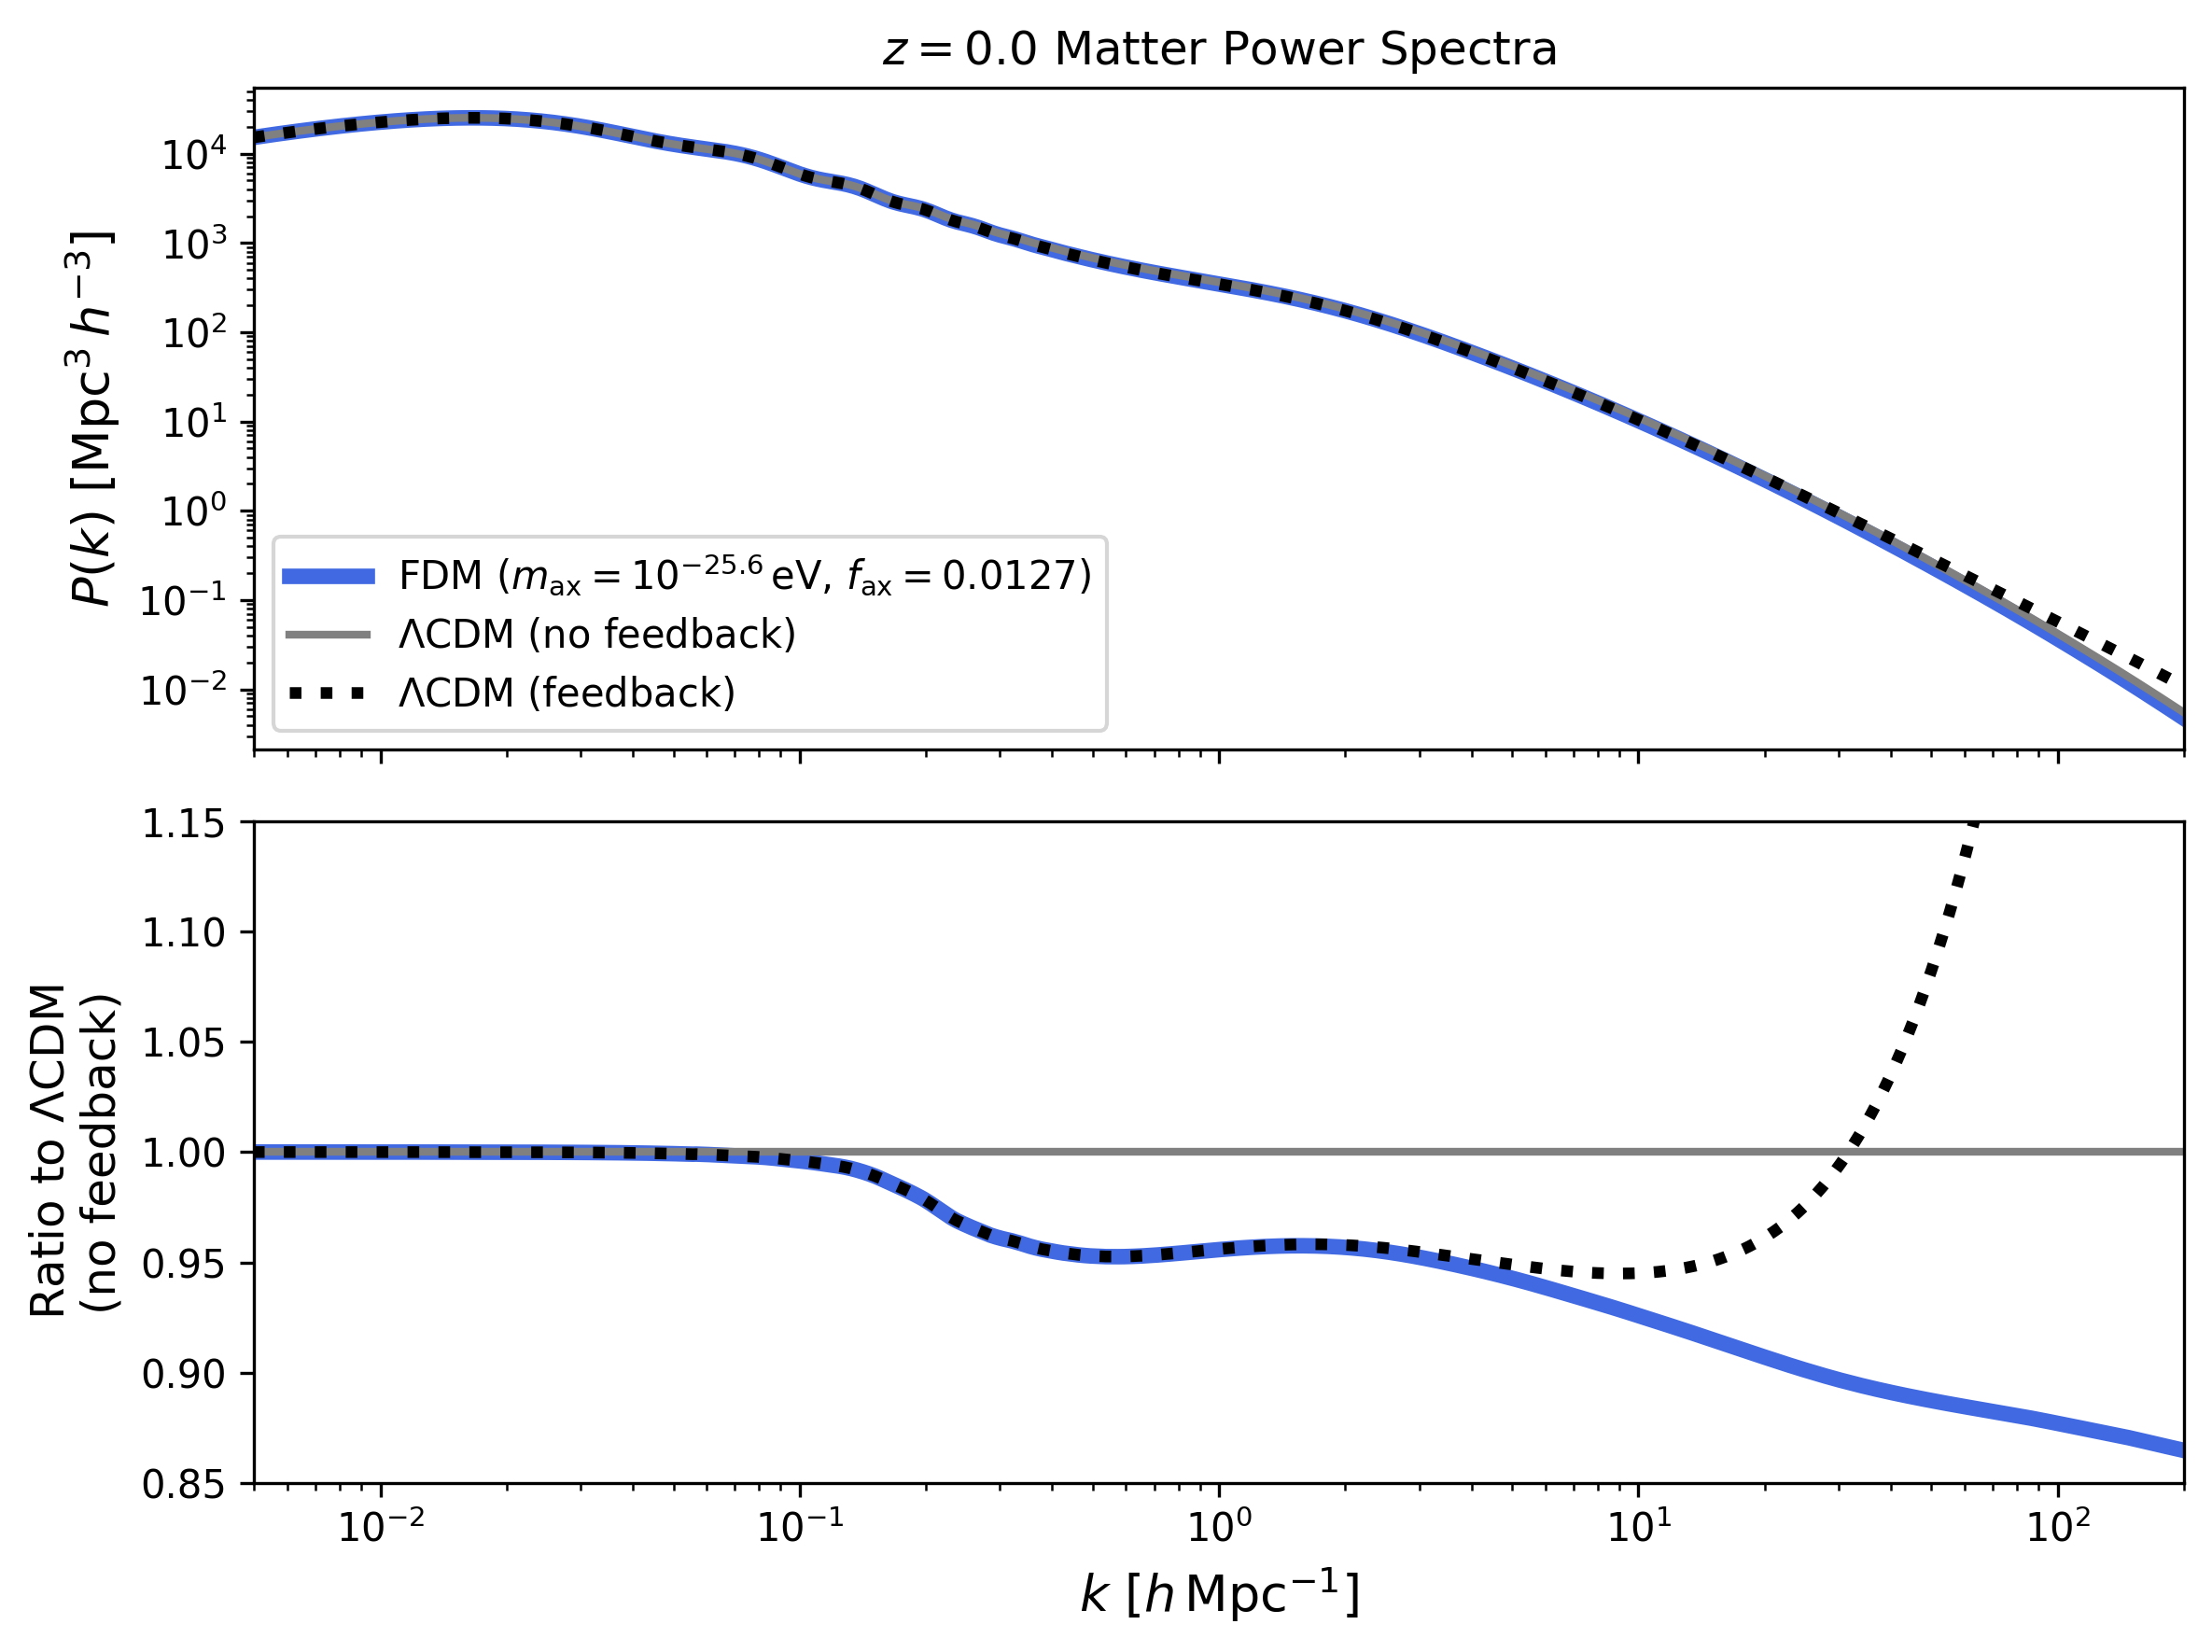

In [42]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 0.0

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to $\Lambda$CDM' + '\n(no feedback)', fontsize=12)
ax1.set_title(r'$z=0.0$ Matter Power Spectra')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()

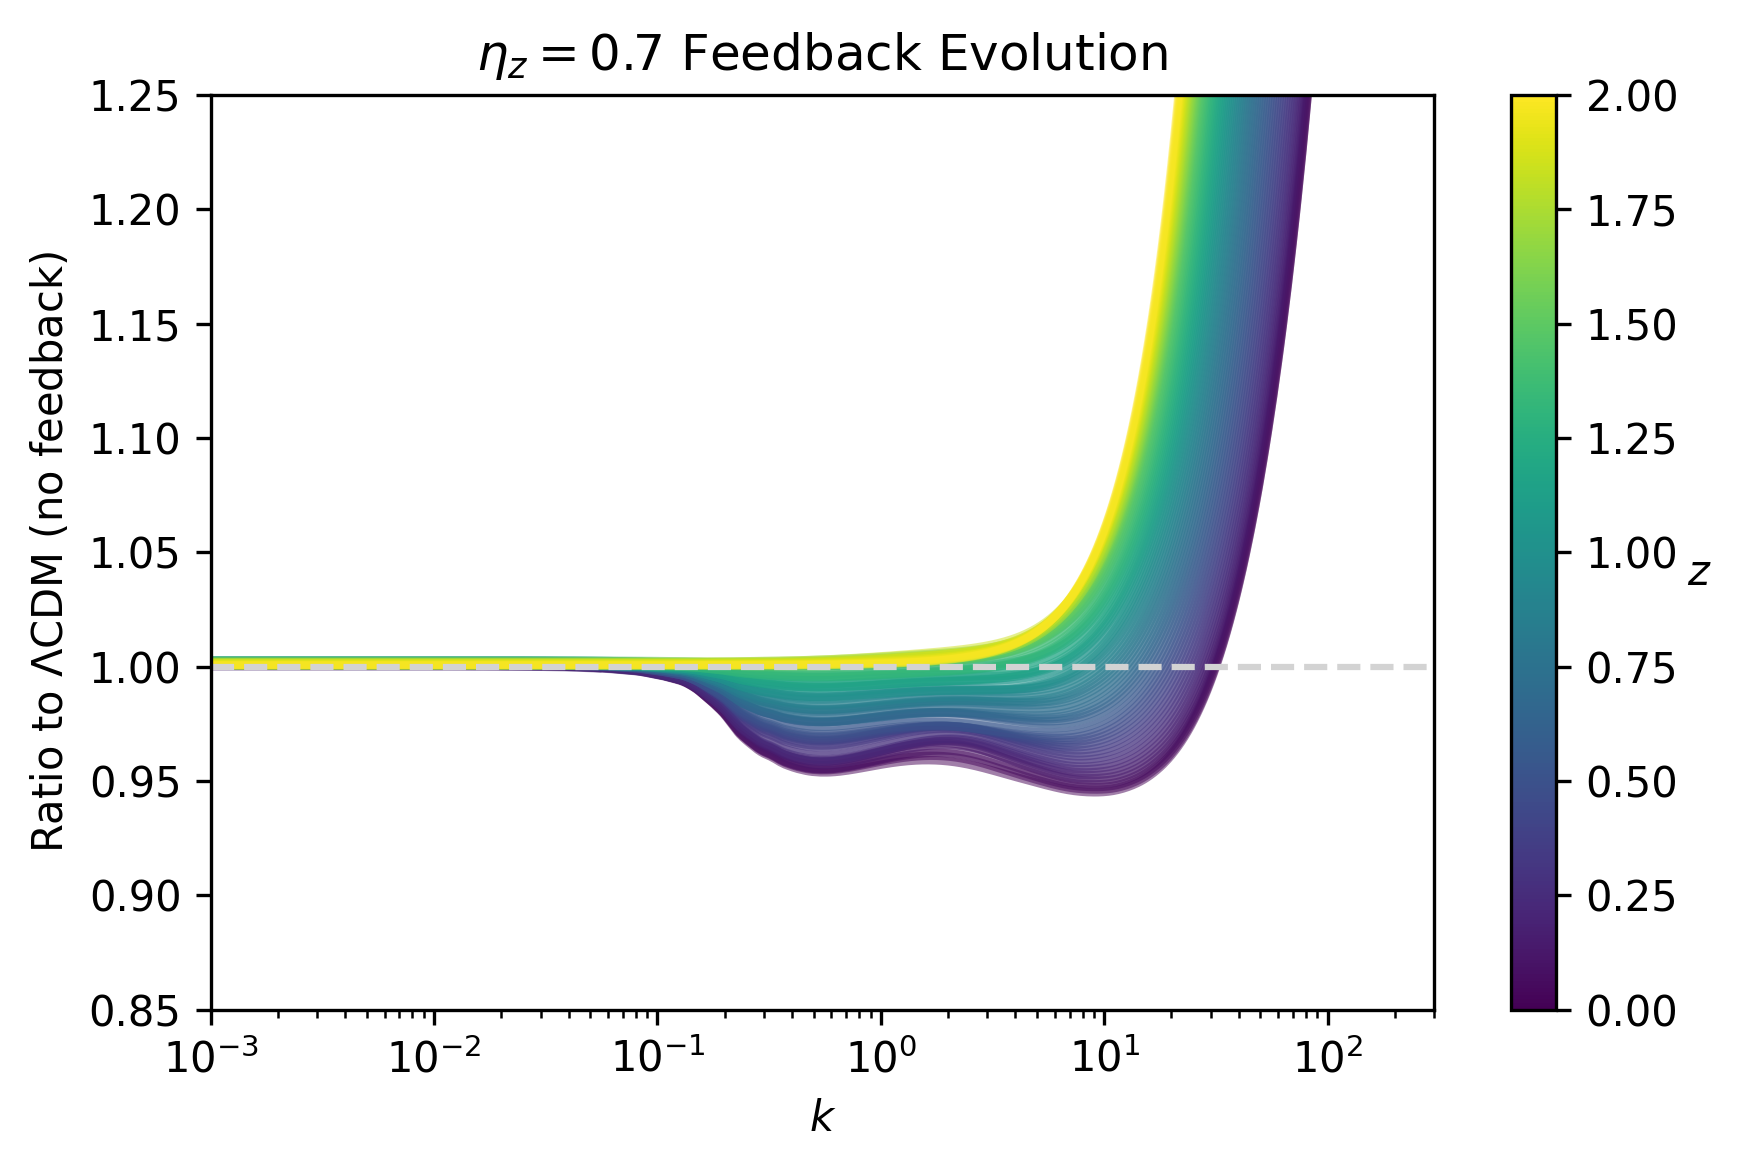

In [5]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 4), dpi=300)

gamma_val = 0.0
etaz = 0.7

K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

z_arr      = np.linspace(0.0, 2.0, 81)
#z_arr = [0.0,0.5,1.0,1.5,2.0]
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(z_arr)))

for z, color in zip(z_arr, colors):
    with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    k_arr_HMCode = data_LCDM['power_spec_dic']['k']

    feedback_model = f"etaz{etaz}_preferred_cooled"
    baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
    #baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]

    ax1.semilogx(k_arr_HMCode, baryonic_profile[-1]['P']/data_LCDM['P'], c=color, ls='-',lw=2.,alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.0, vmax=2.0))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1)
cbar.set_label(r'$z$', rotation=0, labelpad=5)

ax1.axhline(1.0, c='lightgray', ls='--')

ax1.set_xlabel(r'$k$')
ax1.set_ylabel(r'Ratio to $\Lambda$CDM (no feedback)')

ax1.set_ylim(0.85,1.25)
ax1.set_xlim(1e-3,3e2)
ax1.set_title(fr"$\eta_z = {etaz}$ Feedback Evolution")

plt.tight_layout()
plt.show()

##### Profile Plots

/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")
/tmp/ipykernel_2940391/3895193278.py:30: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
/tmp/ipykernel_2940391/3895193278.py:33: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])


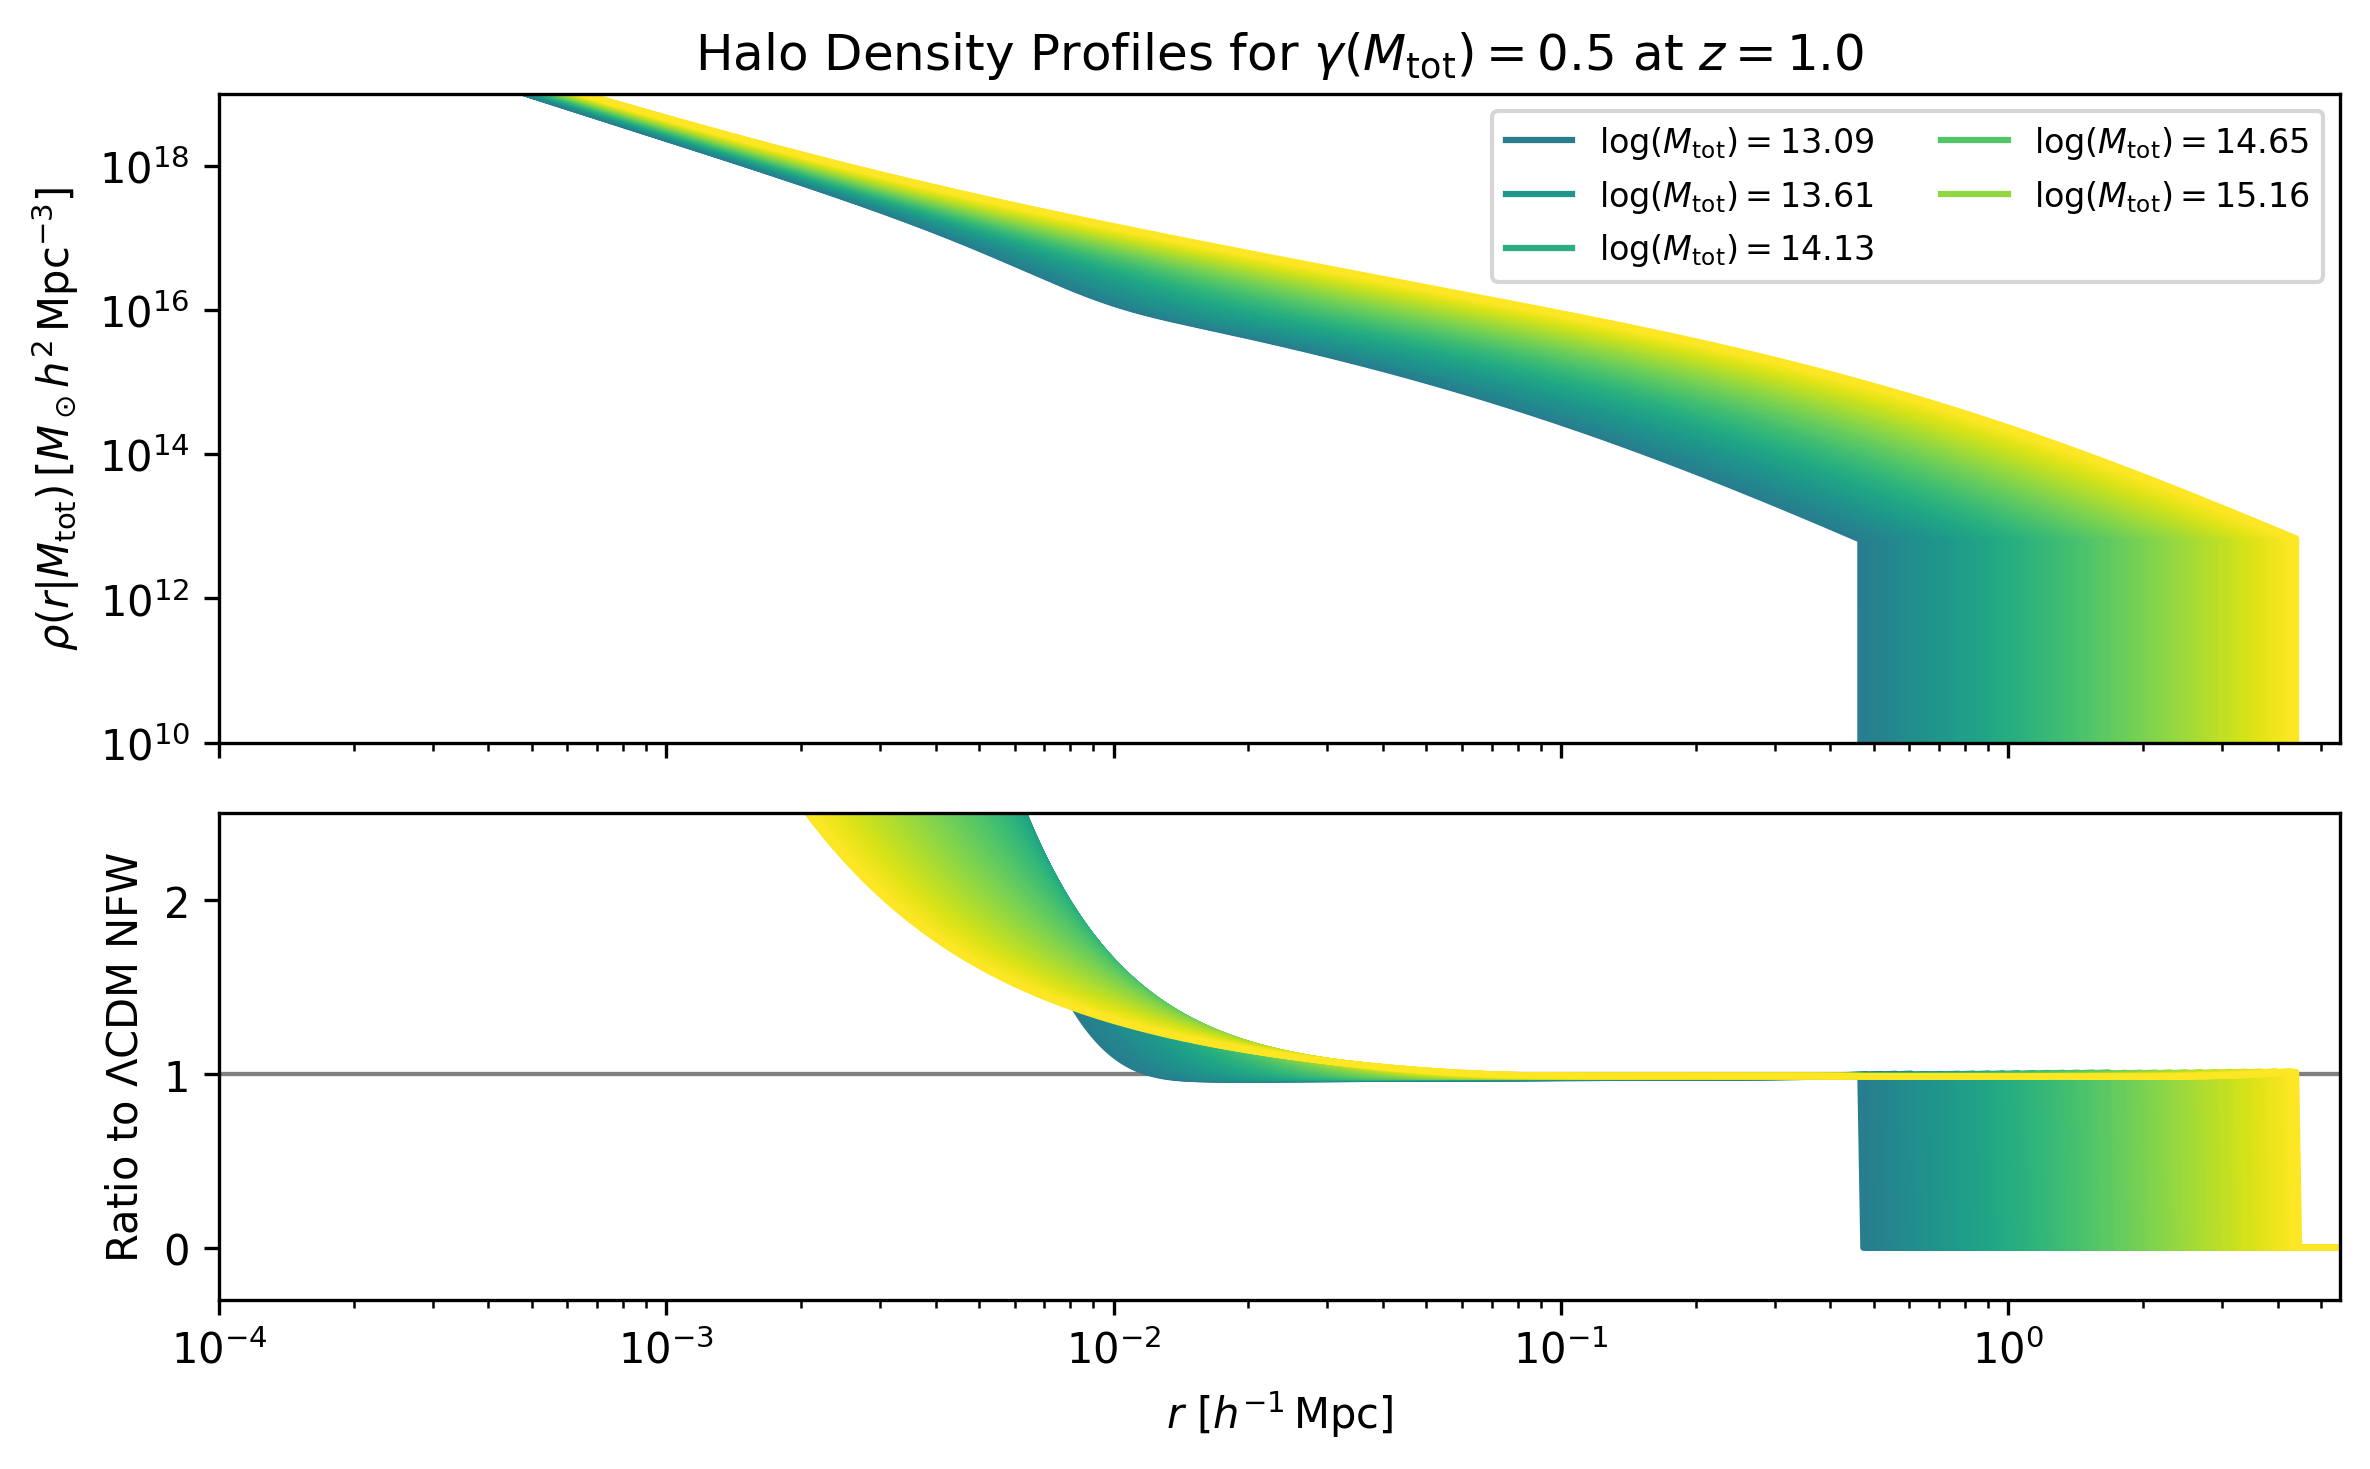

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)
k_arr = np.logspace(-6, 6, 8192)
r_arr = np.logspace(-4, np.log10(1/min(k_arr)), 1500)

gamma_val = 0.5
etaz = 0.7
z = 1.0
feedback_model = f"etaz{etaz}_preferred_cooled"
keys = np.arange(np.size(data_LCDM['M'])) # M values
keys_labels = [0,31,62,93,125,156,187,218,249] # M values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
rho_NFW = get_realspace_profile(get_NFW_profile(k_arr=k_arr, r_s=r_s, r_v=r_v, r_t=max(r_arr) * r_v/r_v), 
                                r_t=max(r_arr) * r_v/r_v, r_arr=r_arr, k_arr=k_arr, M_arr=data_LCDM['M'])

#baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
for m_index in keys[125:]:
    if m_index in keys_labels:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
    else:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])
#print(np.round(baryonic_profile[-1]['M_total_enclosed']/M_arr,4))

ax1.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
ax2.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
#ax2.set_ylim(0.5,1.5)
#ax1.set_ylim(1e12,1e19)
ax2.set_ylim(-0.3,2.5)
ax1.set_ylim(1e10,1e19)

ax2.set_ylabel(r'Ratio to $\Lambda$CDM NFW')
ax2.set_xscale("log")
ax2.set_yscale("linear")
ax1.set_yscale("log")
ax1.set_ylabel(r'$\rho(r|M_\text{tot}) \, [M_\odot h^2\,\text{Mpc}^{-3} ]$')
ax2.set_xlabel(r'$r$ $[h^{-1}\,\text{Mpc}]$')

ax1.set_title(rf'Halo Density Profiles for $\gamma(M_\text{{tot}}) = {gamma_val}$ at $z={z}$')
ax1.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

##### Cluster Counts Plot

LCDM_hat0.0: N_sel=27323
LCDM_hat0.5: N_sel=27817
LCDM_hat1.0: N_sel=27949
LCDM: N_sel=30134
FDM_preferred: N_sel=28901


/tmp/ipykernel_777417/3617513077.py:393: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


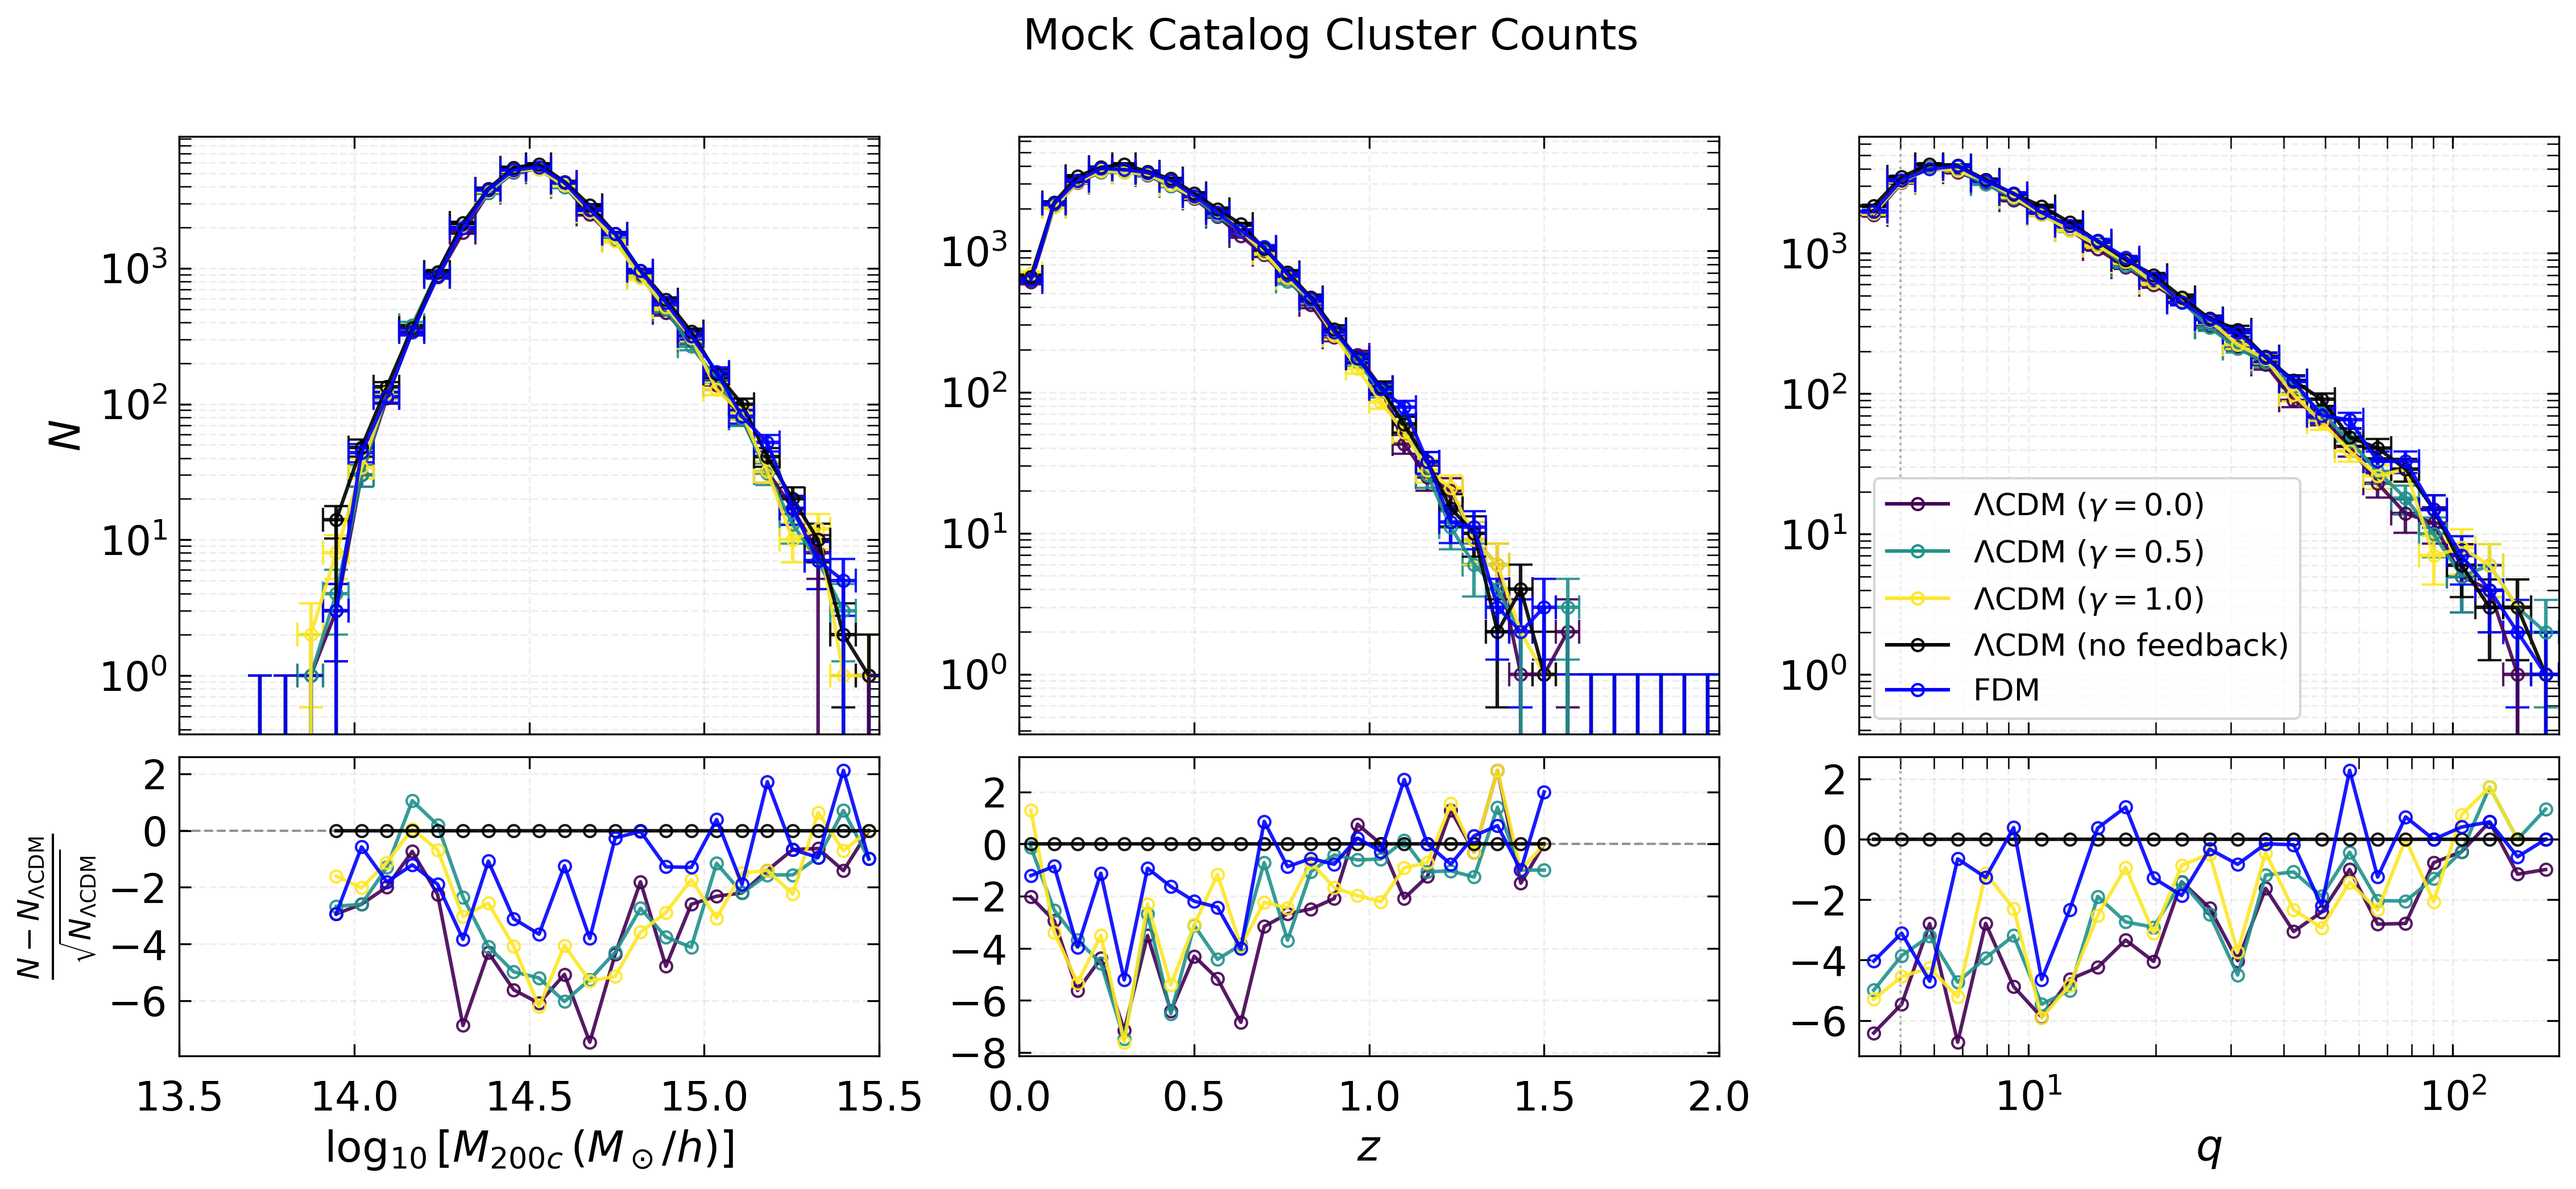

In [6]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

CATALOG_DIR = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
SEED = 42

keys = [0.0,0.5,1.0] # gamma values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))
HMF_TYPES = [
    'LCDM_hat0.0',
    'LCDM_hat0.5',
    'LCDM_hat1.0',
    'LCDM',
    'FDM_preferred',
]

COLORS = [
    color_dict[0.0],
    color_dict[0.5],
    color_dict[1.0],
    'k',
    'b',
]

LABELS = [
    r'$\Lambda$CDM ($\gamma=0.0$)',
    r'$\Lambda$CDM ($\gamma=0.5$)',
    r'$\Lambda$CDM ($\gamma=1.0$)',
    r'$\Lambda$CDM (no feedback)',
    r'FDM',
]

N_BINS_M = 25
N_BINS_Z = 30
N_BINS_Q = 25

label_size = 17
title_size = 18
legend_size = 13

q_type = 'q_true'

# ──────────────────────────────────────────────────────────────────────────────
# STYLING
# ──────────────────────────────────────────────────────────────────────────────

def style_ax(ax):

    ax.tick_params(
        axis='x',
        which='both',
        length=5,
        direction='in',
        pad=10
    )

    ax.tick_params(
        axis='y',
        which='both',
        length=5,
        direction='in',
        pad=5
    )

    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

    plt.setp(
        ax.get_yticklabels(),
        rotation='horizontal',
        fontsize=label_size
    )

    plt.setp(
        ax.get_xticklabels(),
        fontsize=label_size
    )

    ax.grid(
        visible=True,
        which='both',
        alpha=0.2,
        linestyle='--'
    )


# ──────────────────────────────────────────────────────────────────────────────
# LOAD CATALOGS
# ──────────────────────────────────────────────────────────────────────────────

cats = {}

for hmf_type in HMF_TYPES:

    path = (
        f"{CATALOG_DIR}/"
        f"{hmf_type.replace('.', 'p')}_mock_seed{SEED}.pkl"
    )

    with open(path, "rb") as f:
        cats[hmf_type] = pickle.load(f)

    print(f"{hmf_type}: N_sel={cats[hmf_type]['n_selected']}")

# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────

ref = cats['LCDM']

M_edges = np.logspace(
    np.log10(ref['M200c_true'].min() * 0.6),
    np.log10(ref['M200c_true'].max() * 1.1),
    N_BINS_M + 1
)

z_edges = np.linspace(
    0.0,
    2.0,
    N_BINS_Z + 1
)

q_edges = np.logspace(
    np.log10(ref['Q_TH'] * 0.8),
    np.log10(ref[q_type].max() * 1.1),
    N_BINS_Q + 1
)

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

# plotting coordinates

M_x = np.log10(M_centres)
z_x = z_centres
q_x = q_centres

# ──────────────────────────────────────────────────────────────────────────────
# HORIZONTAL BIN-WIDTH ERRORS
# ──────────────────────────────────────────────────────────────────────────────

M_xerr = np.vstack([
    M_x - np.log10(M_edges[:-1]),
    np.log10(M_edges[1:]) - M_x
])

z_xerr = np.vstack([
    z_x - z_edges[:-1],
    z_edges[1:] - z_x
])

q_xerr = np.vstack([
    q_x - q_edges[:-1],
    q_edges[1:] - q_x
])

# ──────────────────────────────────────────────────────────────────────────────
# HISTOGRAMS
# ──────────────────────────────────────────────────────────────────────────────

counts = {}

for hmf_type in HMF_TYPES:

    c = cats[hmf_type]

    counts[hmf_type] = {
        'M': np.histogram(c['M200c_true'], bins=M_edges)[0].astype(float),
        'z': np.histogram(c['z'], bins=z_edges)[0].astype(float),
        'q': np.histogram(c[q_type], bins=q_edges)[0].astype(float),
    }

n_lcdm = counts['LCDM']

# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 7),
    dpi=300,
    gridspec_kw={
        'height_ratios': [1, 0.5],
        'hspace': 0.05,
    }
)

(ax_M, ax_z, ax_q), (ax_dM, ax_dz, ax_dq) = axes

top_axes = [ax_M, ax_z, ax_q]
bot_axes = [ax_dM, ax_dz, ax_dq]

# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────

for hmf_type, color, label in zip(HMF_TYPES, COLORS, LABELS):

    n = counts[hmf_type]

    # -------------------------------------------------------------------------
    # TOP ROW
    # -------------------------------------------------------------------------

    for ax, vals, x, xerr in [

        (ax_M, n['M'], M_x, M_xerr),
        (ax_z, n['z'], z_x, z_xerr),
        (ax_q, n['q'], q_x, q_xerr),

    ]:

        ax.errorbar(
            x,
            vals,
            xerr=xerr,
            yerr=np.sqrt(np.maximum(vals, 1)),
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            capsize=5,
            color=color,
            alpha=0.9,
            label=label
        )

    # -------------------------------------------------------------------------
    # BOTTOM ROW
    # -------------------------------------------------------------------------

    for ax, vals, ref_vals, x in [

        (ax_dM, n['M'], n_lcdm['M'], M_x),
        (ax_dz, n['z'], n_lcdm['z'], z_x),
        (ax_dq, n['q'], n_lcdm['q'], q_x),

    ]:

        safe_ref = np.where(ref_vals > 0, ref_vals, np.nan)

        delta_sigma = (vals - ref_vals) / np.sqrt(safe_ref)

        ax.plot(
            x,
            delta_sigma,
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            color=color,
            alpha=0.9,
        )

# ──────────────────────────────────────────────────────────────────────────────
# TOP ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in top_axes:

    style_ax(ax)

    ax.set_yscale('log')

    ax.tick_params(
        labelbottom=False
    )

top_axes[0].set_ylabel(
        r'$N$',
        size=title_size
    )

# q axis

ax_q.set_xscale('log')

ax_q.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# BOTTOM ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in bot_axes:

    style_ax(ax)

    ax.axhline(
        0,
        color='k',
        lw=1,
        ls='--',
        alpha=0.4
    )

bot_axes[0].set_ylabel(
    r'$\frac{N-N_{\Lambda\rm CDM}}{\sqrt{N_{\Lambda\rm CDM}}}$',
    size=title_size
)

ax_dM.set_xlabel(
    r'$\log_{10}[M_{200c}\,(M_\odot/h)]$',
    size=title_size
)

ax_dz.set_xlabel(
    r'$z$',
    size=title_size
)

ax_dq.set_xlabel(
    r'$q$',
    size=title_size
)

ax_dq.set_xscale('log')

ax_dq.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# AXIS LIMITS
# ──────────────────────────────────────────────────────────────────────────────

ax_M.set_xlim(M_x.min(), M_x.max())
ax_dM.set_xlim(M_x.min(), M_x.max())

ax_z.set_xlim(z_edges[0], z_edges[-1])
ax_dz.set_xlim(z_edges[0], z_edges[-1])

ax_q.set_xlim(q_edges[0], q_edges[-1])
ax_dq.set_xlim(q_edges[0], q_edges[-1])

# optional redshift ticks

ax_M.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_dM.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_z.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax_dz.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])

# ──────────────────────────────────────────────────────────────────────────────
# LEGEND
# ──────────────────────────────────────────────────────────────────────────────

handles = [
    Line2D(
        [0],
        [0],
        color=c,
        lw=1.5,
        marker='o',
        markersize=5,
        fillstyle='none',
        label=l
    )
    for c, l in zip(COLORS, LABELS)
]

ax_q.legend(
    handles=handles,
    loc='lower left',
    frameon=True,
    fontsize=legend_size
)

plt.suptitle("Mock Catalog Cluster Counts", fontsize=title_size)
plt.tight_layout()
plt.show()

###### q vals

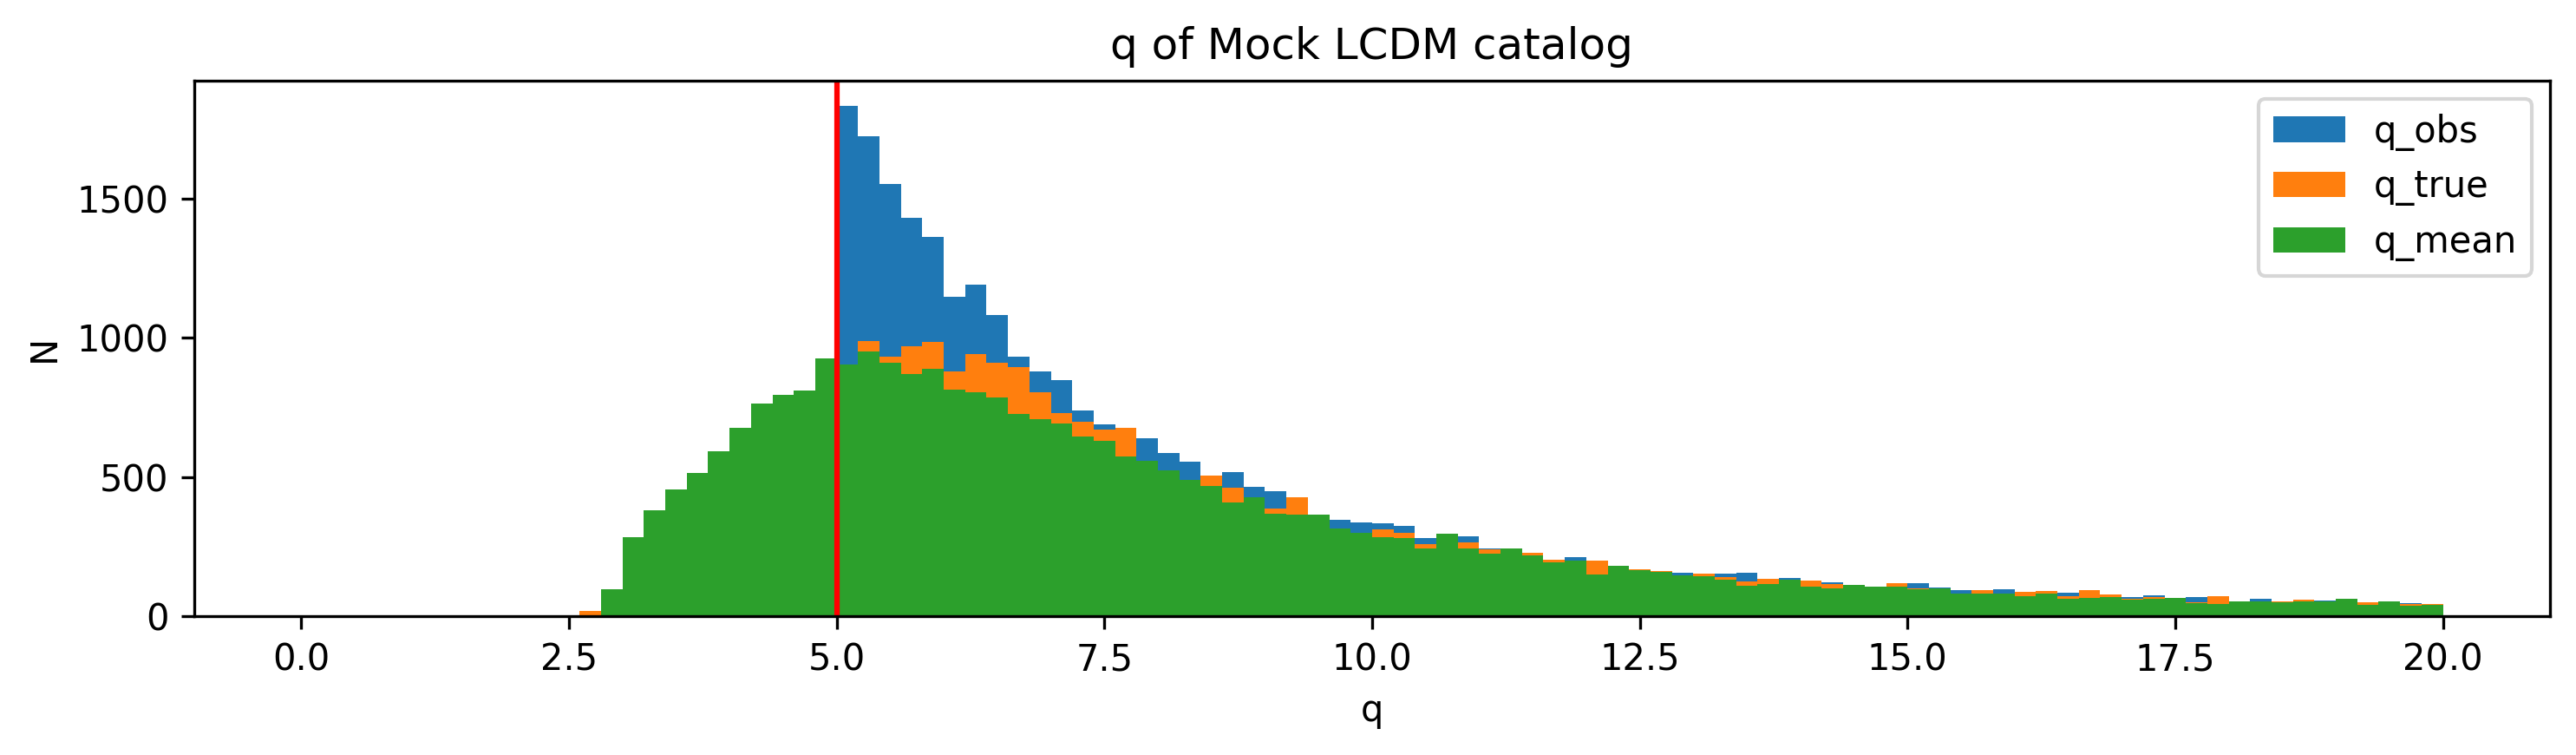

In [10]:
fig, axes = plt.subplots(1, 1, figsize=(10, 3), dpi=300)

axes.hist(cats['LCDM']['q_obs'], bins=100, range=(0, 20), label='q_obs')
axes.hist(cats['LCDM']['q_true'], bins=100, range=(0, 20), label='q_true')
axes.hist(cats['LCDM']['q_mean'], bins=100, range=(0, 20), label='q_mean')
axes.axvline(cats['LCDM']['Q_TH'], color='r')

axes.set_title("q of Mock LCDM catalog")
axes.set_xlabel("q")
axes.set_ylabel("N")
axes.legend()

plt.tight_layout()
plt.show()

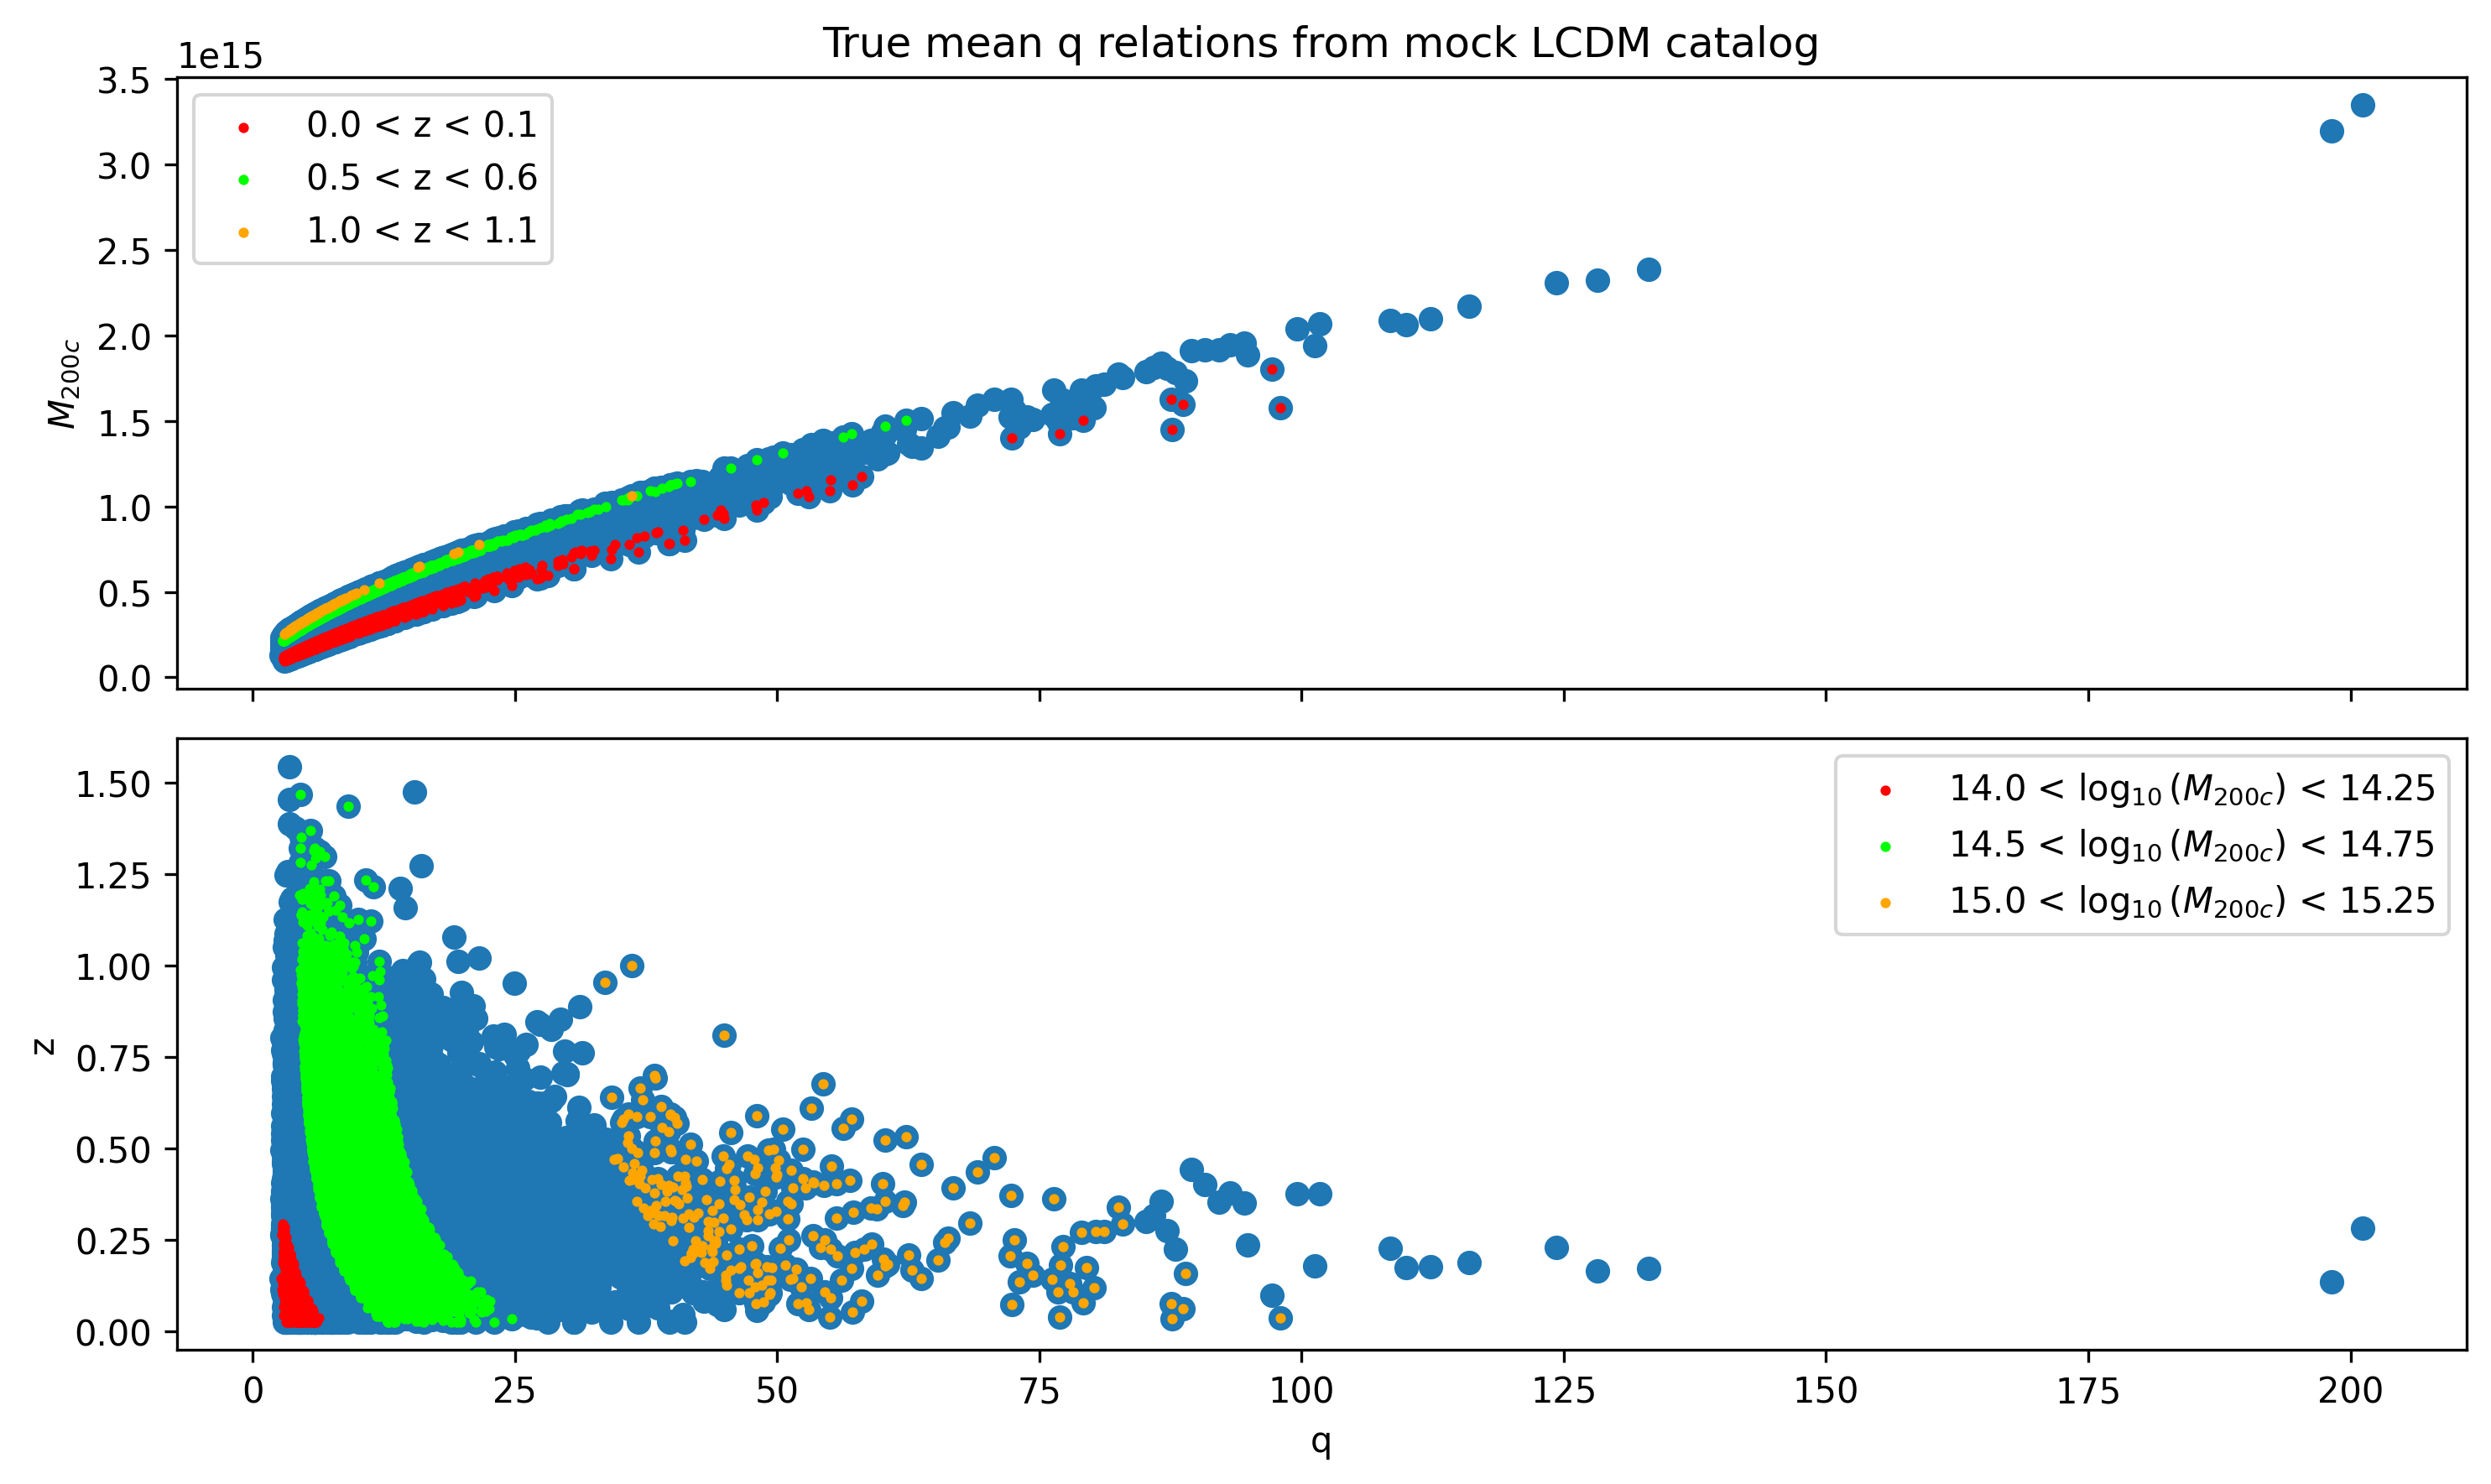

In [16]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), dpi=300, sharex=True)

ax0.scatter(catalogue['q_mean'],catalogue['M200c_true'])

zmin, zmax = 0.0, 0.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='red', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 0.5, 0.6
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='lime', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 1.0, 1.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='orange', s=15, label=f'{zmin} < z < {zmax}', marker='.')
ax0.legend()
ax0.set_ylabel(r"$M_{{200c}}$")

ax1.scatter(catalogue['q_mean'],catalogue['z'])

Mmin, Mmax = 10**14, 10**14.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='red', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**14.5, 10**14.75
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='lime', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**15, 10**15.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='orange', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')

ax1.legend()
ax1.set_ylabel("z")

ax1.set_xlabel("q")
ax0.set_title("True mean q relations from mock LCDM catalog")
plt.tight_layout()
plt.show()

###### Theory comparison

Building theory hmf_M_matrix and q_mean_grid (mirrors generator)...
Theory mean N (after selection) = 30677.92

Loading mock catalogs...
n_selected per seed: [np.int64(30134), np.int64(29736), np.int64(29835), np.int64(30127), np.int64(30047), np.int64(30134), np.int64(29725), np.int64(29793), np.int64(30090), np.int64(30244)]
mean n_selected: 29986.5  (theory: 30677.9)

N(M200c):
    centre     theory  mock_mean   frac_off   frac_SEM  poisson_mean
    14.050      53.38      87.60     0.6412     0.0407        0.0433
    14.150     347.64     439.70     0.2648     0.0154        0.0170
    14.250    1176.51    1574.60     0.3384     0.0120        0.0092
    14.350    3890.32    4201.70     0.0800     0.0051        0.0051
    14.450    6363.92    7510.20     0.1801     0.0047        0.0040
    14.550    7325.55    7462.90     0.0187     0.0021        0.0037
    14.650    3897.57    4478.50     0.1491     0.0040        0.0051
    14.750    2276.14    2286.70     0.0046     0.0073        0.

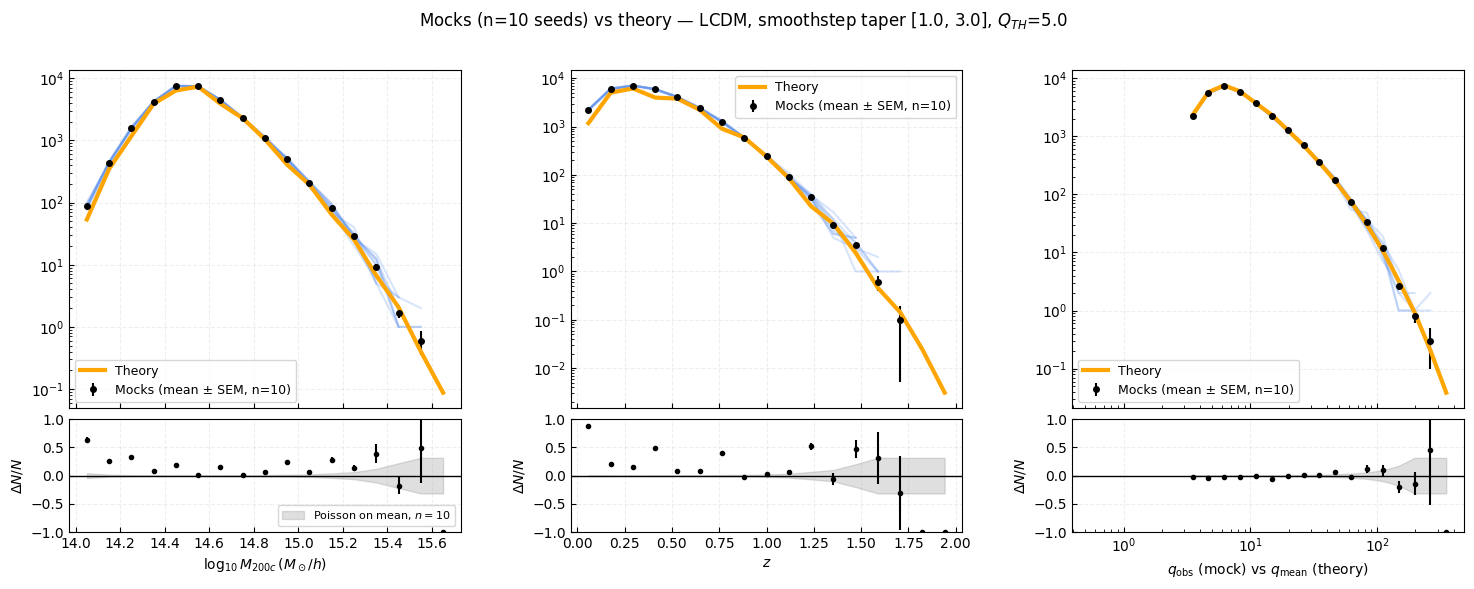

In [8]:
import os
import pickle
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import integrate
from scipy.special import erf

# ── CONFIG — must match generate_mock_catalogs.py exactly ───────────────────
HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
MOCK_DIR        = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
HMF_TYPE        = "LCDM"
SEEDS           = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]

FSKY  = 0.4
Q_TH  = 5.0
Q_MIN = 3.0
Q_FLOOR = 1.0
SIGMA_LN_Q_INTRINSIC = 0.173
SIGMA_Q_OBS          = 1.0

M_TRANSITION = 10**12.5
M_MIN_SAMPLE = 10**12.5
M_MAX_SAMPLE = 1e16
NUM_M_SAMPLE = 300
ln_M_target  = np.linspace(np.log(M_MIN_SAMPLE), np.log(M_MAX_SAMPLE), NUM_M_SAMPLE)
M_target     = np.exp(ln_M_target)

Z_ARR = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1.0 / K_ARR.min()), 1500)

# Bin edges for the comparison plots
M_edges = np.linspace(14.0, 15.7, 18)
z_edges = np.linspace(0.0,  2.0,  18)
q_edges = np.logspace(np.log10(3.0), np.log10(400.), 18)

# ── IMPORTS ───────────────────────────────────────────────────────────────────
from feedback_mimic import (
    dn_dlog10Mtot, get_NFW_profile, get_realspace_profile,
    dV_dz, profile_to_q, Mtot_to_MDelta, get_some_quantities,
)

def bin_2d_to_1d_simpson(hist2d, z_arr, lnM_arr, edges, axis_to_integrate_first, target_is_M):
    """
    Properly integrate hist2d (n_z, n_M) into 1D bins using Simpson's rule
    within each bin, rather than a coarse point-weighted histogram.
    """
    if target_is_M:
        # Integrate over z first -> dN/dlnM, then bin in log10(M) using Simpson per bin
        dN_dlnM = integrate.simpson(hist2d, x=z_arr, axis=0)   # (n_M,)
        log10_M = lnM_arr / np.log(10.)
        out = np.zeros(len(edges)-1)
        for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            mask = (log10_M >= lo) & (log10_M < hi)
            if mask.sum() >= 2:
                out[i] = integrate.simpson(dN_dlnM[mask] * np.log(10.), x=log10_M[mask])
        return out
    else:
        # Integrate over lnM first -> dN/dz, then bin in z using Simpson per bin
        dN_dz = integrate.simpson(hist2d, x=lnM_arr, axis=1)   # (n_z,)
        out = np.zeros(len(edges)-1)
        for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            mask = (z_arr >= lo) & (z_arr < hi)
            if mask.sum() >= 2:
                out[i] = integrate.simpson(dN_dz[mask], x=z_arr[mask])
        return out

# ── BUILD THEORY: exactly mirrors generate_mock_catalogs.py's hmf_M_matrix ──

def smoothstep_taper(q_of_M200c, q_floor=Q_FLOOR, q_min_soft=Q_MIN):
    x = (q_of_M200c - q_floor) / (q_min_soft - q_floor)
    t = np.clip(x, 0., 1.)
    return t**2 * (3. - 2.*t)

def selection_probability_exact(q_mean_grid, n_eps=1024,
                                 sigma_lnq=SIGMA_LN_Q_INTRINSIC,
                                 sigma_qobs=SIGMA_Q_OBS, q_th=Q_TH):
    q_mean_grid = np.asarray(q_mean_grid)
    eps  = np.linspace(-6*sigma_lnq, 6*sigma_lnq, n_eps)
    w    = np.exp(-0.5*(eps/sigma_lnq)**2)
    w   /= np.trapezoid(w, eps)
    q_t  = q_mean_grid[None, :, :] * np.exp(eps[:, None, None])
    arg  = (q_th - q_t) / sigma_qobs
    p    = 0.5*(1. - erf(arg/np.sqrt(2.)))
    return np.trapezoid(w[:, None, None]*p, eps, axis=0)

print("Building theory hmf_M_matrix and q_mean_grid (mirrors generator)...")

hmf_M_matrix = np.zeros((len(Z_ARR), NUM_M_SAMPLE))
q_mean_grid  = np.zeros_like(hmf_M_matrix)

for iz, z in enumerate(Z_ARR):
    with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data = pickle.load(f)

    Mtot, hmf_log10 = dn_dlog10Mtot(data, "LCDM")
    hmf = hmf_log10 / np.log(10)

    r_t, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = \
        get_some_quantities(data)

    rho = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t, k_arr=K_ARR, r_s=r_s, r_t=r_t),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot, r_t=r_t)

    valid = Mtot > M_TRANSITION
    Mtot_v = Mtot[valid]; hmf_v = hmf[valid]; rho_v = rho[valid]; r_t_v = r_t[valid]

    M200c, _ = Mtot_to_MDelta(
        data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
        Del=200, reference_density="critical",
        rho=rho_v, k_arr=K_ARR)

    q_of_M200c = profile_to_q(
        data, rho=rho_v, r_t=r_t_v, M_arr=Mtot_v, k_arr=K_ARR, r_arr=R_ARR,
        bias_sz=0.8, dof=0.0, axion_dic=None)

    hmf_M200c = hmf_v * np.gradient(np.log(Mtot_v)) / np.gradient(np.log(M200c))

    order = np.argsort(M200c)
    M200c_s = M200c[order]; hmf_M200c_s = hmf_M200c[order]; q_s = q_of_M200c[order]

    # SAME smoothstep taper as the current generator (NOT the old hard Q_MIN mask)
    taper = smoothstep_taper(q_s)
    hmf_M200c_masked = hmf_M200c_s * taper

    hmf_M_matrix[iz] = np.interp(
        ln_M_target, np.log(M200c_s), hmf_M200c_masked * dV_dz(data),
        left=0., right=0.)

    q_mean_grid[iz] = np.interp(
        ln_M_target, np.log(M200c_s), q_s,
        left=q_s[0], right=q_s[-1])

hmf_M_fsky = hmf_M_matrix * FSKY   # matches generator's hmf_M_fsky exactly

Psel    = selection_probability_exact(q_mean_grid)
hmf_sel = hmf_M_fsky * Psel        # dN/(dlnM dz) after full selection, fsky included

n_mean_theory = integrate.simpson(
    integrate.simpson(hmf_sel, x=ln_M_target, axis=1), x=Z_ARR)
print(f"Theory mean N (after selection) = {n_mean_theory:.2f}")

# weights for binning: dN per (z,M) grid cell, integrated over the cell
dlnM = np.gradient(ln_M_target)
dz   = np.gradient(Z_ARR)
weights_theory = hmf_sel * dlnM[None, :] * dz[:, None]   # (n_z, n_M)

# ── THEORY HISTOGRAMS ─────────────────────────────────────────────────────────

theory_M, _ = np.histogram(
    np.log10(np.tile(M_target, len(Z_ARR))),
    bins=M_edges, weights=weights_theory.ravel())

theory_z, _ = np.histogram(
    np.repeat(Z_ARR, len(M_target)),
    bins=z_edges, weights=weights_theory.ravel())

theory_M = bin_2d_to_1d_simpson(hmf_sel, Z_ARR, ln_M_target, M_edges, axis_to_integrate_first=0, target_is_M=True)
theory_z = bin_2d_to_1d_simpson(hmf_sel, Z_ARR, ln_M_target, z_edges, axis_to_integrate_first=1, target_is_M=False)

theory_q, _ = np.histogram(
    q_mean_grid.ravel(),
    bins=q_edges, weights=weights_theory.ravel())

# ── LOAD MOCKS AND BUILD PER-SEED HISTOGRAMS ─────────────────────────────────

print("\nLoading mock catalogs...")
mock_M_list, mock_z_list, mock_q_list = [], [], []
n_sel_per_seed = []

for seed in SEEDS:
    path = f"{MOCK_DIR}/{HMF_TYPE}_mock_seed{seed}.pkl"
    with open(path, "rb") as f:
        cat = pickle.load(f)

    M200c_mock = np.asarray(cat['M200c_true'])   # Msol/h
    z_mock     = np.asarray(cat['z'])
    q_mock     = np.asarray(cat['q_mean'])         # observed, noisy q

    n_sel_per_seed.append(cat['n_selected'])

    h_M, _ = np.histogram(np.log10(M200c_mock), bins=M_edges)
    h_z, _ = np.histogram(z_mock,                bins=z_edges)
    h_q, _ = np.histogram(q_mock,                bins=q_edges)

    mock_M_list.append(h_M)
    mock_z_list.append(h_z)
    mock_q_list.append(h_q)

mock_M = np.array(mock_M_list)   # (n_seeds, n_bins)
mock_z = np.array(mock_z_list)
mock_q = np.array(mock_q_list)
n_seeds = len(SEEDS)

print(f"n_selected per seed: {n_sel_per_seed}")
print(f"mean n_selected: {np.mean(n_sel_per_seed):.1f}  (theory: {n_mean_theory:.1f})")

# ── PRINT DIAGNOSTIC TABLE ────────────────────────────────────────────────────

def print_comparison_table(name, theory_hist, mock_hist, centres):
    mean = mock_hist.mean(axis=0)
    sem  = mock_hist.std(axis=0) / np.sqrt(n_seeds)
    frac_offset = (mean - theory_hist) / np.maximum(theory_hist, 1e-30)
    frac_sem    = sem / np.maximum(theory_hist, 1e-30)
    poisson_on_mean = 1.0 / np.sqrt(np.maximum(theory_hist, 1.0) * n_seeds)

    print(f"\n{name}:")
    print(f"{'centre':>10} {'theory':>10} {'mock_mean':>10} {'frac_off':>10} "
          f"{'frac_SEM':>10} {'poisson_mean':>13}")
    for i in range(len(centres)):
        if theory_hist[i] > 0.5:
            print(f"{centres[i]:>10.3f} {theory_hist[i]:>10.2f} {mean[i]:>10.2f} "
                  f"{frac_offset[i]:>10.4f} {frac_sem[i]:>10.4f} {poisson_on_mean[i]:>13.4f}")

M_centres = 0.5*(M_edges[1:] + M_edges[:-1])
z_centres = 0.5*(z_edges[1:] + z_edges[:-1])
q_centres = 0.5*(q_edges[1:] + q_edges[:-1])

print_comparison_table("N(M200c)", theory_M, mock_M, M_centres)
print_comparison_table("N(z)",     theory_z, mock_z, z_centres)
print_comparison_table("N(q)",     theory_q, mock_q, q_centres)

# ── PLOT ──────────────────────────────────────────────────────────────────────

fig = plt.figure(figsize=(18, 6))
gs  = fig.add_gridspec(2, 3, height_ratios=[3, 1], hspace=0.05, wspace=0.28)

panels = [
    (M_edges, mock_M, theory_M, r"$\log_{10} M_{200c}\,(M_\odot/h)$", False),
    (z_edges, mock_z, theory_z, r"$z$",                                False),
    (q_edges, mock_q, theory_q, r"$q_{\rm obs}$ (mock) vs $q_{\rm mean}$ (theory)", True),
]

for panel, (edges, mocks, theory_hist, xlabel, logx) in enumerate(panels):
    ax  = fig.add_subplot(gs[0, panel])
    axr = fig.add_subplot(gs[1, panel], sharex=ax)
    centres = 0.5*(edges[1:] + edges[:-1])

    for m in mocks:
        ax.plot(centres, np.where(m > 0, m, np.nan), color="cornflowerblue", alpha=0.25)

    mean = mocks.mean(axis=0)
    sem  = mocks.std(axis=0) / np.sqrt(n_seeds)

    ax.errorbar(centres, mean, yerr=sem, fmt="ko", ms=4, label=f"Mocks (mean ± SEM, n={n_seeds})")
    ax.plot(centres, theory_hist, color="orange", lw=3, label="Theory")
    ax.set_yscale("log")
    if logx:
        ax.set_xscale("log"); axr.set_xscale("log")
    ax.legend(fontsize=9)
    ax.tick_params(labelbottom=False, which='both', direction='in')
    ax.grid(alpha=0.2, ls='--')

    frac     = (mean - theory_hist) / np.maximum(theory_hist, 1e-30)
    frac_sem = sem / np.maximum(theory_hist, 1e-30)
    poisson_on_mean = 1.0 / np.sqrt(np.maximum(theory_hist, 1.0) * n_seeds)

    axr.fill_between(centres, -poisson_on_mean, poisson_on_mean,
                      color="gray", alpha=0.25, label=r"Poisson on mean, $n=$"+str(n_seeds))
    axr.axhline(0, color="k", lw=1)
    axr.errorbar(centres, frac, yerr=frac_sem, fmt="ko", ms=3)
    axr.set_ylim(-1, 1)
    axr.set_xlabel(xlabel)
    axr.set_ylabel(r"$\Delta N/N$")
    axr.tick_params(which='both', direction='in')
    axr.grid(alpha=0.2, ls='--')
    if panel == 0:
        axr.legend(fontsize=8, loc='lower right')

fig.suptitle(f"Mocks (n={n_seeds} seeds) vs theory — {HMF_TYPE}, smoothstep taper "
             f"[{Q_FLOOR}, {Q_MIN}], $Q_{{TH}}$={Q_TH}", fontsize=12)

plt.show()

###### cosmocnc Comparison

##### Likelihood Code Testing

###### External Shear Likelihood and cosmocnc_jax Likelihood Implementation

In [10]:
import pickle
import numpy as np
import os
import cosmocnc_axionHMcode_jax.cosmocnc_jax as cosmocnc
from wl_likelihoods import logP_gt_all, logP_gt_numerical
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    func_axionHMcode_D_z_unnorm_int,
    func_axionHMcode_D_z_unnorm)
from astropy.cosmology import FlatLambdaCDM
from scipy.integrate import simpson
import jax
import jax.numpy as jnp

h_fid       = 0.68
omega_b_fid = 0.0226576
ns_fid      = 0.965

omega_m_fid = 0.143344
A_s_fid   = 2.1e-09
#sigma_8_fid = 0.825264573 # found from axionHMcode

_SURVEY_SR  = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_sr_so_sim.py"
_SURVEY_CAT = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_cat_so_sim.py"

Z_ARR        = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

In [11]:
# Precompute a bunch of quantities so we dont have to do it on the fly, and can just interpolate
#################################################################################### COSMOLOGY CACHE
_astropy_cosmo_fid = FlatLambdaCDM(H0=h_fid*100., Om0=omega_m_fid/h_fid**2)
_omega_m_grid      = np.linspace(0.05, 0.30, 200)
_Om0_grid          = _omega_m_grid / h_fid**2
_z_table           = np.concatenate([np.linspace(1e-6, 1., 500), np.linspace(1., 100., 500)])
_z_source_bins     = np.array([0.285, 0.476, 0.743, 0.942])
from feedback_mimic import comoving_distance
_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30

_cache_path = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_GRID_CACHE.pkl"
if os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table = pickle.load(f)
    print("Loaded precomputed tables from cache")
else:
    print("Precomputing tables (one-time cost)...")
    _G_a_grid  = np.array([
        func_axionHMcode_D_z_unnorm_int(
            0., Om0,
            lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
        for Om0 in _Om0_grid])
    _norm_grid = np.array([
    func_axionHMcode_D_z_unnorm(
        0., Om0,
        lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
    for Om0 in _Om0_grid])
    _D_table = np.zeros((len(_omega_m_grid), len(_z_table)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        E_z_i   = lambda z, c=cosmo_i: c.H(z).value / (h_fid * 100.)
        norm_i  = _norm_grid[i]
        _D_table[i] = [func_axionHMcode_D_z_unnorm(z, Om0, E_z_i) / norm_i
                       for z in _z_table]
    _DA_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        for j, z in enumerate(Z_ARR):
            _DA_table[i, j] = comoving_distance(
                {"cosmos": {"z": z, "h": h_fid,
                             "Omega_m_0": Om0, "Omega_w_0": 1.-Om0}}, z) / (1+z)
    _Sigma_crit_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        for j, z in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z]
            if len(usable) == 0:
                _Sigma_crit_table[i, j] = np.inf
                continue
            inv_scs = []
            DA_l = cosmo_i.angular_diameter_distance(z).value  # Mpc, astropy ← fix
            for z_s in usable:
                DA_s  = cosmo_i.angular_diameter_distance(z_s).value
                DA_ls = cosmo_i.angular_diameter_distance_z1z2(z, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * DA_l*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            _Sigma_crit_table[i, j] = 1./np.mean(inv_scs) if inv_scs else np.inf    
    with open(_cache_path, "wb") as f:
        pickle.dump((_G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table), f)
    print("Saved tables")


def _interp_omega_m(omega_m, table):
    """Linear interpolation over the omega_m grid."""
    w    = np.interp(omega_m/h_fid**2, _Om0_grid, np.arange(len(_Om0_grid), dtype=float))
    i_lo = int(np.clip(np.floor(w), 0, len(_Om0_grid)-2))
    frac = w - i_lo
    return (1.-frac)*table[i_lo] + frac*table[i_lo+1]

def get_G_a_interp(omega_m):        return np.interp(omega_m, _omega_m_grid, _G_a_grid)
def get_norm_interp(omega_m):       return np.interp(omega_m, _omega_m_grid, _norm_grid)
def get_D_grid_interp(omega_m):     return _z_table.copy(), _interp_omega_m(omega_m, _D_table)
def get_DA_grid_interp(omega_m):    return Z_ARR.copy(),    _interp_omega_m(omega_m, _DA_table)
def get_Sigma_crit_arr(omega_m):    return _interp_omega_m(omega_m, _Sigma_crit_table)

#################################################################################### PROFILE CACHE
import os
import pickle
import numpy as np
from tqdm import tqdm
from astropy.cosmology import FlatLambdaCDM
from scipy.interpolate import interp1d

from feedback_mimic import (
    get_NFW_profile, get_realspace_profile, get_some_quantities,
    dn_dlog10Mtot, Mtot_to_MDelta, get_tangential_shear
)

CACHE_PATH = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_SHEAR_LCDM_CACHE.npz"
if os.path.exists(CACHE_PATH):
    print("Shear cache already made")
else:
    HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
    
    # ── grids ─────────────────────────────────────────────────────────────────────
    h_fid         = 0.68
    omega_m_0_fid = 0.143344
    
    Z_ARR = np.linspace(0.0, 2.0, 81)
    Z_ARR = Z_ARR[Z_ARR > 0]
    
    K_ARR = np.logspace(-6, 6, 8192)
    R_ARR = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)
    
    M_TRANSITION     = 10**12.5
    M_DELTA          = 200
    M_REF_DENS       = "critical"
    R_PROJ_ARR_NUM   = 300
    R_FOR_SIGMA_NUM  = 100
    
    # ── KEY FIX: single common R grid for ALL redshifts ──────────────────────────
    # Use the smallest R_max across all z (= 3.2/(1+z_max)) so every z slice
    # covers the full grid. Profiles beyond a given z's r_vir will naturally
    # drop to zero; we never extrapolate outward.
    R_MAX_GLOBAL  = 3.2 / (1. + Z_ARR.min())   # ~1.6/(1+2) ≈ 0.533 Mpc/h for z_max=2
    R_proj_common = np.linspace(0.5, R_MAX_GLOBAL, R_PROJ_ARR_NUM)   # (nR,) fixed
    
    # ── Sigma_crit ────────────────────────────────────────────────────────────────
    _G_SI    = 6.674e-11
    _c_SI    = 2.998e8
    _Mpc_m   = 3.0857e22
    _Msol_kg = 1.989e30

    def compute_Sigma_crit_arr(omega_m, h_fid=h_fid,
                                _z_source_bins=np.array([0.285, 0.476, 0.743, 0.942])):
        Om0   = omega_m / h_fid**2
        cosmo = FlatLambdaCDM(H0=h_fid * 100.0, Om0=Om0)
        Sigma_crit_arr = np.zeros(len(Z_ARR))
        for j, z_l in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z_l]
            if len(usable) == 0:
                Sigma_crit_arr[j] = np.inf
                continue
            DA_l    = cosmo.angular_diameter_distance(z_l).value
            inv_scs = []
            for z_s in usable:
                DA_s  = cosmo.angular_diameter_distance(z_s).value
                DA_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * DA_l*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            Sigma_crit_arr[j] = 1./np.mean(inv_scs) if inv_scs else np.inf
        return Sigma_crit_arr
    
    # Sigma_crit in Msol/h/(Mpc/h)^2
    Sigma_crit_arr = compute_Sigma_crit_arr(omega_m_0_fid) / h_fid
    
    # ── mass grid ─────────────────────────────────────────────────────────────────
    lnM_min    = np.log(10**13.5)
    lnM_max    = np.log(1e16)
    N_M        = 600
    lnM_common = np.linspace(lnM_min, lnM_max, N_M)   # log(M200c [Msol/h])
    M_common   = np.exp(lnM_common)
    
    # ── allocate output arrays ────────────────────────────────────────────────────
    nZ = len(Z_ARR)
    nM = N_M
    nR = R_PROJ_ARR_NUM
    
    GT_cache = np.zeros((nZ, nM, nR))
    DS_cache = np.zeros((nZ, nM, nR))
    S_cache  = np.zeros((nZ, nM, nR))
    
    # ── main loop ─────────────────────────────────────────────────────────────────
    print("Computing shear cache...")
    for iz, z in enumerate(tqdm(Z_ARR)):
    
        with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
            data = pickle.load(f)
    
        Mtot, _ = dn_dlog10Mtot(data, 'LCDM')
        r_t, _, _, _, r_s, _, _, _ = get_some_quantities(data, axion_dic=None)
    
        valid  = Mtot > M_TRANSITION
        Mtot_v = Mtot[valid]
        r_t_v  = r_t[valid]
        r_s_v  = r_s[valid]
    
        rho_v = get_realspace_profile(
            u_k=get_NFW_profile(r_v=r_t_v, k_arr=K_ARR, r_s=r_s_v, r_t=r_t_v),
            r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_v, r_t=r_t_v)
    
        M200c, _ = Mtot_to_MDelta(
            data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
            Del=M_DELTA, reference_density=M_REF_DENS,
            axion_dic=None, rho=rho_v, k_arr=K_ARR)
    
        # ── KEY FIX: pass R_proj_common so every z uses the same R grid ──────────
        GT_raw, DS_raw, S_raw, R_proj_out = get_tangential_shear(
            rho_v, R_ARR, z, Mtot_v, M200c, r_t_v,
            Sigma_crit_arr[iz],
            R_min=R_proj_common[0],
            R_max=R_proj_common[-1],          # same R_max for every z
            R_proj_arr_num=R_PROJ_ARR_NUM,
            R_for_Sigma_num=R_FOR_SIGMA_NUM,
            M_min_to_consider=M_TRANSITION,
            full_output=True)
    
        # verify R_proj_out matches (it should by construction)
        assert np.allclose(R_proj_out, R_proj_common, rtol=1e-6), \
            f"R grid mismatch at z={z}"
    
        # filter valid entries and sort by M200c
        valid2    = M200c > 0
        lnM_nat   = np.log(M200c[valid2])
        GT_valid  = np.array([GT_raw[i] for i in range(len(M200c))
                              if valid2[i] and GT_raw[i] is not None])
        DS_valid  = np.array([DS_raw[i] for i in range(len(M200c))
                              if valid2[i] and DS_raw[i] is not None])
    
        # Sigma is on R_for_Sigma (log grid); resample onto R_proj_common
        R_for_Sigma = np.logspace(np.log10(1e-4), np.log10(R_proj_common[-1]),
                                  R_FOR_SIGMA_NUM)
        S_valid = np.array([
            np.interp(R_proj_common, R_for_Sigma, np.array(S_raw[i]))
            for i in range(len(M200c))
            if valid2[i] and S_raw[i] is not None])
    
        lnM_valid = lnM_nat[[GT_raw[i] is not None
                              for i in range(len(lnM_nat))]]
    
        order     = np.argsort(lnM_valid)
        lnM_valid = lnM_valid[order]
        GT_valid  = GT_valid[order]
        DS_valid  = DS_valid[order]
        S_valid   = S_valid[order]
    
        # interpolate onto common lnM grid for each R bin
        for ir in range(nR):
            GT_cache[iz, :, ir] = np.interp(lnM_common, lnM_valid, GT_valid[:, ir],
                                             left=0., right=0.)
            DS_cache[iz, :, ir] = np.interp(lnM_common, lnM_valid, DS_valid[:, ir],
                                             left=0., right=0.)
            S_cache[iz,  :, ir] = np.interp(lnM_common, lnM_valid, S_valid[:, ir],
                                             left=0., right=0.)
    
    np.savez(CACHE_PATH,
             GT_cache   = GT_cache,       # (nZ, nM, nR)
             DS_cache   = DS_cache,       # (nZ, nM, nR)
             S_cache    = S_cache,        # (nZ, nM, nR)
             R_proj     = R_proj_common,  # (nR,)  SINGLE common grid — key fix
             Z_ARR      = Z_ARR,          # (nZ,)
             lnM_common = lnM_common)     # (nM,)  log(M200c Msol/h)
    
    print(f"Saved to {CACHE_PATH}")
    print(f"Grid: nZ={nZ}, nM={nM}, nR={nR}")
    print(f"R grid: {R_proj_common[0]:.3f} to {R_proj_common[-1]:.3f} Mpc/h (FIXED for all z)")
    print(f"lnM:    {lnM_min:.2f} to {lnM_max:.2f}  "
          f"({np.exp(lnM_min):.2e} to {np.exp(lnM_max):.2e} Msol/h)")

Loaded precomputed tables from cache
Shear cache already made


In [12]:
def get_log_likelihood_externalShear(
    catalogue_name,
    # ── free parameters ──
    omega_m  = omega_m_fid,
    A_s      = A_s_fid,
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz  = 2.0,
    b_WL_0    = 0.0, 
    b_WL_M    = 1.0,
    # ── fixed ────────────
    bias_sz       = 0.8,
    sigma_lnq     = 0.173,
    dof           = 0.0,
    q_cutoff      = 5.0,
    M_WL_pivot    = 2e14, # Msol/h
    wl_catalogue = None,
    sigma_shape = 0.37,
    n_source    = 5.5,  # arcmin^-2
    return_nc = False,
    use_shear_cache = False, # True to use the numerical, interpolated, truncated NFW profiles rather than just the analytic ones
    wl_z_max = None, # cuts off the max z that we use to constrain wl bias params
    wl_only = False,        # no abundance or SZ data -> use broad flat mass prior
    wl_n_mass_points = 200, # esolution of the broad mass grid if wl_only
    DR = 0.3  # radial grid in h^-1 Mpc for shear profiles
):
    z_table, D_grid = get_D_grid_interp(omega_m)
    nc = cosmocnc.cluster_number_counts()
    nc.cnc_params.update({
        "survey_sr"                : _SURVEY_SR,
        "survey_cat"               : _SURVEY_CAT,
        "obs_select"               : "q_so_sim",
        "observables"              : [["q_so_sim"]],
        "obs_select_min"           : 5.,
        "obs_select_max"           : 300.0,
        "z_min"                    : Z_ARR[0],
        "z_max"                    : Z_ARR[-1],
        "M_min"                    : 10**12.5 / h_fid,
        "M_max"                    : 1e16 / h_fid,
        "cluster_catalogue"        : catalogue_name,
        "likelihood_type"          : "unbinned",
        "data_lik_from_abundance"  : False,
        "scalrel_type_deriv"       : "analytical",
        "n_points"                 : 1000,
        "n_z"                      : len(Z_ARR),
        "cosmology_tool"           : "classy_sz_jax",
        "power_spectrum_type"      : "cosmopower",
        "cosmo_amplitude_parameter": "A_s",
        "hmf_calc"                 : "cnc",
        "hmf_type"                 : "ST_axionHMcode",
        "mass_definition"          : "200c",
        "number_cores_hmf"         : 1,
        "number_cores_abundance"   : 1,
        "number_cores_data"        : 1,
        "cosmocnc_verbose"         : "none",
        "return_profile_params"    : True,
        "stacked_likelihood"       : False,
        "non_validated_clusters"   : False,
    })
    nc.cosmo_params.update({
        "Om0"     : omega_m / h_fid**2,
        "Ob0"     : omega_b_fid / h_fid**2,
        "h"       : h_fid,
        "H0": h_fid * 100.,
        "A_s"     : A_s,
        "n_s"     : ns_fid,
        "m_nu"    : 0.0,
        "tau_reio": 0.06,
        "n_mass_points_coarse": 50,
        # ── These are necessary to make ST_axionHMcode fast ──
        "G_a_precomputed":           get_G_a_interp(omega_m),
        "D_grid_z_precomputed":      z_table,
        "D_grid_precomputed":        D_grid,
        "normalisation_precomputed": get_norm_interp(omega_m),
        "Sigma_crit_vec": get_Sigma_crit_arr(omega_m)
    })
    nc.scal_rel_params.update({
        "A_szifi"        : A_sz,
        "alpha_szifi"    : alpha_sz,
        "beta_szifi"     : beta_sz,
        "bias_sz"        : bias_sz,
        "sigma_lnq_szifi": sigma_lnq,
        "dof"            : dof,
        "q_cutoff"       : q_cutoff,
    })
    nc.initialise()

    try:
        nc.get_hmf(return_profile_params=True)        
        log_lik_sz_cosmocnc = nc.get_log_lik()
        print(f"cosmocnc output: {log_lik_sz_cosmocnc}")
    except Exception as e:
        print(f"cosmocnc_jax failed: {e}")
        return -np.inf
    P_q_and_hmf_kernel = nc.bc_cpdf_array

    if wl_catalogue is not None:
        z_wl    = np.asarray(nc.bc_z_clusters)
        lnM_arr = np.asarray(nc.bc_lnM_array)     # (n_cl, n_pts), ln(M/1e14 Msol)
        cwh     = np.asarray(nc.bc_cpdf_array)     # (n_cl, n_pts), unnormalised
        n_cl = len(z_wl)
    
        # NFW profile on the full mass grid (n_cl, n_pts)
        profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)
        rho_crit_per_cluster = np.interp(z_wl, Z_ARR, np.asarray(nc.rho_c))  # Msol/Mpc^3
        R_200c_per_cluster   = (3. * np.exp(lnM_arr) * 1e14             # M in Msol on grid
                                / (4. * np.pi * rho_crit_per_cluster[:, None] * 200.))**(1./3.)
        # r_s in Mpc (from profile), c_200c dimensionless
        c_200c = R_200c_per_cluster / profile['r_s']   # (n_cl, n_pts)
        rho_m_h      = profile['rho_m']      * h_fid**3   # Msol/(h^-1 Mpc)^3
        rho_crit_z_h = rho_crit_per_cluster  / h_fid**2
        r_s_h        = profile['r_s']        * h_fid       # h^-1 Mpc
        r_vir_h = profile['R_vir'] * h_fid
    
        # Sigma_crit: Msol/Mpc^2 → Msol/(h^-1 Mpc)^2
        #Sigma_crit_wl = np.interp(z_wl, Z_ARR,
        #        get_Sigma_crit_arr(omega_m)) * h_fid   # (n_cl,)
        iz_wl = np.argmin(np.abs(Z_ARR[:, None] - z_wl[None, :]), axis=0)
        Sigma_crit_wl = get_Sigma_crit_arr(omega_m)[iz_wl] / h_fid
        # treating it like a step function rather than something continuous
    
        # DA for annulus area: Mpc → h^-1 Mpc
        DA_z_arr, DA_arr = get_DA_grid_interp(omega_m)
        DA_halo = np.interp(wl_catalogue['z'], DA_z_arr, DA_arr) * h_fid
    
        # ── Radial grid (h^-1 Mpc), same convention as Bocquet ──
        z_wl_cat = wl_catalogue['z']
        gt_orig  = np.asarray(wl_catalogue["gt_true"])
        R_orig   = np.asarray(wl_catalogue["R_proj_arr"])

        R_new_list, gt_new_list = [], []
        for i, zi in enumerate(z_wl_cat):
            r_min  = 0.5
            r_max  = 3.2 / (1. + zi)
            n_bins = max(int(np.round((r_max - r_min) / DR)) + 1, 2)
            r_new  = np.linspace(r_min, r_max, n_bins)
            R_new_list.append(r_new)
            gt_new_list.append(np.interp(r_new, R_orig[i], gt_orig[i]))
    
        N_R    = max(len(r) for r in R_new_list)
        R_proj = np.array([np.pad(r,  (0, N_R - len(r)),  constant_values=r[-1])
                           for r in R_new_list])
        gt_obs = np.array([np.pad(gt, (0, N_R - len(gt)), constant_values=0.)
                           for gt in gt_new_list])
    
        dR_arr = np.gradient(R_proj, axis=1)
        A_ann  = (2.*np.pi * R_proj * dR_arr
                  * (180.*60./np.pi / DA_halo[:, None])**2)
        sigma_g = sigma_shape / np.sqrt(np.maximum(n_source * A_ann, 1.))
        
        # Mask padded bins
        for i, r_new in enumerate(R_new_list):
            sigma_g[i, len(r_new):] = 1e10
        
        for i, r_new in enumerate(R_new_list):
            dR_i = np.gradient(r_new)                          # gradient on real bins only
            A_ann_i = (2.*np.pi * r_new * dR_i
                       * (180.*60./np.pi / DA_halo[i])**2)
            sigma_g[i, :len(r_new)] = sigma_shape / np.sqrt(
                np.maximum(n_source * A_ann_i, 1.))
            sigma_g[i, len(r_new):] = 1e10
        if wl_z_max is not None:
            above_zmax = z_wl_cat > wl_z_max   # (n_cl,) boolean
            sigma_g[above_zmax, :] = 1e10
            
        if wl_only:
            # Broad flat prior: same grid for every cluster
            lnM_lo  = np.log(10**13.5)
            lnM_hi  = np.log(1e16)
            lnM_int = np.linspace(lnM_lo, lnM_hi, wl_n_mass_points)  # log(Msol/h)
            M_arr_wl = jnp.array(                                      # (n_cl, n_pts_wl) Msol/h
                np.tile(np.exp(lnM_int), (n_cl, 1)))
            lnM_sz_in_Msol_h = lnM_arr + np.log(1e14) + np.log(h_fid)
            c_200c_wl = np.array([
                np.interp(lnM_int, lnM_sz_in_Msol_h[i], c_200c[i],
                          left=c_200c[i, 0], right=c_200c[i, -1])
                for i in range(n_cl)])   # (n_cl, n_pts_wl)
        
            lnM_for_simpson = lnM_int   # 1D, common for all clusters
        else:
            # Use SZ posterior grid as before
            M_arr_wl      = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
            c_200c_wl     = c_200c                              # (n_cl, n_pts)
            lnM_for_simpson = nc.bc_lnM_array      

        # ── Compute logP_gt ────────────────────────────────────────────────
        if use_shear_cache:
            logP_gt = logP_gt_numerical(
                gt_obs, sigma_g, R_proj,
                M_arr_wl, rho_crit_z_h, c_200c_wl,
                Sigma_crit_wl, b_WL_0, b_WL_M, M_WL_pivot, z_wl)
        else:
            logP_gt = logP_gt_all(
                jnp.array(gt_obs), jnp.array(sigma_g), jnp.array(R_proj),
                M_arr_wl, rho_crit_z_h, c_200c_wl,
                jnp.array(Sigma_crit_wl), jnp.array(b_WL_0), jnp.array(b_WL_M), M_WL_pivot)   # (n_cl, n_pts_wl)

        # ── Integrate over mass ────────────────────────────────────────────
        if wl_only:
            # Flat prior: all clusters use the same lnM axis
            P_kernel = jnp.exp(logP_gt)
        else:
            # SZ posterior: per-cluster lnM axis (as before)
            P_kernel = jnp.exp(logP_gt) * P_q_and_hmf_kernel
    else:
        P_kernel = P_q_and_hmf_kernel

    n_bc = len(nc.bc_cluster_indices)
    cluster_liks = np.zeros(n_bc)
    for i in range(n_bc):
        cat_idx = int(nc.bc_cluster_indices[i])
        # P_kernel = cwh = cpdf * HMF * 4π * skyfrac (possible times P(g_t) as well)
        cluster_liks[i] = np.log(max(simpson(P_kernel[i], x=nc.bc_lnM_array[i]), 1e-300))
    log_lik = np.sum(cluster_liks)
    if not wl_only:
        log_lik += -nc.n_tot
    print(f"Manual integration: {log_lik}")
        
    if return_nc:
        return float(log_lik), nc
    return float(log_lik)

In [13]:
def get_log_likelihood(
    catalogue_name,
    # ── free parameters ──
    omega_m  = omega_m_fid,
    A_s    = A_s_fid,
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz  = 2.0,
    b_WL_0    = 0.0, 
    b_WL_M    = 1.0,
    # ── fixed ────────────
    bias_sz       = 0.8,
    sigma_lnq     = 0.0,#0.173, -> for now this is using q_mean as the variable
    dof           = 0.0,
    q_cutoff      = 5.0,
    M_WL_pivot    = 2e14, # Msol/h
    sigma_shape = 0.37,
    n_source    = 5.5,  # arcmin^-2
    return_nc   = False
):
    z_table, D_grid = get_D_grid_interp(omega_m)
    nc = cosmocnc.cluster_number_counts()
    nc.cnc_params.update({
        "survey_sr"                : _SURVEY_SR,
        "survey_cat"               : _SURVEY_CAT,
        "obs_select"               : "q_so_sim",
        "observables"              : [["q_so_sim"],["gt"]],
        "obs_select_min"           : 5.,
        "obs_select_max"           : 300.0,
        "z_min"                    : Z_ARR[0],
        "z_max"                    : Z_ARR[-1],
        "M_min"                    : 10**12.5 / h_fid,
        "M_max"                    : 1e16 / h_fid,
        "cluster_catalogue"        : catalogue_name,
        "likelihood_type"          : "unbinned",
        "data_lik_from_abundance"  : False,
        "scalrel_type_deriv"       : "analytical",
        "n_points"                 : 1000,
        "n_z"                      : len(Z_ARR),
        "cosmology_tool"           : "classy_sz_jax",
        "power_spectrum_type"      : "cosmopower",
        "cosmo_amplitude_parameter": "A_s",
        "hmf_calc"                 : "cnc",
        "hmf_type"                 : "ST_axionHMcode",
        "mass_definition"          : "200c",
        "number_cores_hmf"         : 1,
        "number_cores_abundance"   : 1,
        "number_cores_data"        : 1,
        "cosmocnc_verbose"         : "none",
        "return_profile_params"    : True,
        "stacked_likelihood"       : False,
        "non_validated_clusters"   : False,
        "compute_abundance_matrix" : True
    })
    nc.cosmo_params.update({
        "Om0"     : omega_m / h_fid**2,
        "Ob0"     : omega_b_fid / h_fid**2,
        "h"       : h_fid,
        "H0"      : h_fid * 100.,
        "A_s"     : A_s,
        "n_s"     : ns_fid,
        "m_nu"    : 0.0,
        "tau_reio": 0.06,
        "n_mass_points_coarse": 50,
        # ── These are necessary to make ST_axionHMcode fast ──
        "G_a_precomputed":           get_G_a_interp(omega_m),
        "D_grid_z_precomputed":      z_table,
        "D_grid_precomputed":        D_grid,
        "normalisation_precomputed": get_norm_interp(omega_m),
        "Sigma_crit_vec": get_Sigma_crit_arr(omega_m)
    })
    nc.scal_rel_params.update({
        "A_szifi"        : A_sz,
        "alpha_szifi"    : alpha_sz,
        "beta_szifi"     : beta_sz,
        "bias_sz"        : bias_sz,
        "sigma_lnq_szifi": sigma_lnq,
        "dof"            : dof,
        "q_cutoff"       : q_cutoff,
        "b_WL_0":      b_WL_0,
        "b_WL_M":      b_WL_M,
        "M_WL_pivot":  M_WL_pivot / h_fid,   # in Msol
        "h_fid":      h_fid,        # ← required by get_profile_sr_params
    })
    nc.initialise()

    try:
        nc.get_hmf(return_profile_params=True)        
        log_lik_sz_cosmocnc = nc.get_log_lik()
    except Exception as e:
        print(f"cosmocnc_jax failed: {e}")
        return -np.inf

    if return_nc:
        return float(log_lik_sz_cosmocnc), nc
    return float(log_lik_sz_cosmocnc)

In [14]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
ln_L, nc = get_log_likelihood_externalShear(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    A_s      = 2.1e-9,
    A_sz     = -4.4580166296603672,
    alpha_sz = 1.2468585981093097,
    beta_sz  = 0.8796081344595097,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    wl_catalogue = catalogue,
    return_nc = True
)
print(ln_L)

PATH_TO_CLASS_SZ_DATA not set. Setting it now...
Defaulting to: /home/jange/class_sz_data_directory


2026-06-17 14:18:47.888189: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:782: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


cosmocnc output: 168082.246950418
Manual integration: -1146007.1962455418
-1146007.1962455418


In [15]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
ln_L, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    A_s      = 2.1e-9,
    A_sz     = -4.4580166296603672,
    alpha_sz = 1.2468585981093097,
    beta_sz  = 0.8796081344595097,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True
)
print(ln_L)

-1294660.989478403


###### Consistency Checks (first pass)

In [16]:
import numpy as np
from astropy.cosmology import FlatLambdaCDM
from astropy import units as u

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30


# ── NFW helper functions (pure numpy) ────────────────────────────────────────

def _f_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.ones_like(x)
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.arctanh(np.sqrt(1. - x[lt]**2)) / np.sqrt(1. - x[lt]**2)
    out[gt] = np.arctan( np.sqrt(x[gt]**2 - 1.)) / np.sqrt(x[gt]**2 - 1.)
    return out

def _g_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.full_like(x, 1. + np.log(0.5))
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.log(x[lt]/2.) + np.arctanh(np.sqrt(1.-x[lt]**2)) / np.sqrt(1.-x[lt]**2)
    out[gt] = np.log(x[gt]/2.) + np.arctan( np.sqrt(x[gt]**2-1.)) / np.sqrt(x[gt]**2-1.)
    return out

def gt_nfw_analytic(R_bins_Mpc_h, M_Msol_h, rho_crit_h, c_200c, Sigma_crit_h):
    """
    Analytic NFW reduced tangential shear.

    All inputs in h-unit system:
        R_bins_Mpc_h   : (nR,)  projected radii        [Mpc/h]
        M_Msol_h       : scalar M_200c                 [Msol/h]
        rho_crit_h     : scalar rho_crit(z)            [Msol/h / (Mpc/h)^3]
                         = rho_crit_astropy / h^2
        c_200c         : scalar concentration          [dimensionless]
        Sigma_crit_h   : scalar critical surface dens  [Msol/h / (Mpc/h)^2]
                         = Sigma_crit_table * h

    Returns gt : (nR,) dimensionless reduced shear
    """
    r_200 = (3. * M_Msol_h / (4. * np.pi * 200. * rho_crit_h))**(1./3.)  # Mpc/h
    r_s   = r_200 / c_200c                                                  # Mpc/h
    g_c   = np.log(1. + c_200c) - c_200c / (1. + c_200c)
    rho_s = M_Msol_h / (4. * np.pi * r_s**3 * g_c)                        # Msol/h/(Mpc/h)^3

    x         = R_bins_Mpc_h / r_s
    Sigma     = 2. * rho_s * r_s / (x**2 - 1.) * (1. - _f_nfw_np(x))     # Msol/h/(Mpc/h)^2
    Sigma_bar = 4. * rho_s * r_s / x**2 * _g_nfw_np(x)                    # Msol/h/(Mpc/h)^2
    return (Sigma_bar - Sigma) / (Sigma_crit_h - Sigma)


# ── Main check function ───────────────────────────────────────────────────────

def run_checks(nc, catalogue, omega_m, h_fid=0.68,
               cluster_indices=None, Z_ARR=None,
               get_Sigma_crit_arr=None):
    """
    Parameters
    ----------
    nc                  : cosmocnc object after get_log_lik()
    catalogue           : mock catalogue dict
    omega_m             : physical matter density (Omega_m * h^2)
    h_fid               : Hubble parameter
    cluster_indices     : list of catalogue indices to check
    Z_ARR               : redshift array used in cosmocnc
    get_Sigma_crit_arr  : function(omega_m) → (n_z,) Msol/Mpc^2
    """
    if cluster_indices is None:
        cluster_indices = [0, 50, 200]
    if Z_ARR is None:
        Z_ARR = np.linspace(0., 2., 81)[1:]

    z_wl    = np.asarray(nc.bc_z_clusters)
    lnM_arr = np.asarray(nc.bc_lnM_array)
    rho_c_vec = np.asarray(nc.rho_c)          # Msol/Mpc^3, on Z_ARR grid
    profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)

    SEP = "=" * 70

    # ── Section 1: Unit conversion verification ───────────────────────────────
    print(SEP)
    print("SECTION 1: UNIT CONVERSION VERIFICATION")
    print(SEP)
    print("Confirmed conversions (from physical R200c check):")
    print("  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3")
    print("  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2")
    print()

    # Verify rho_crit conversion using R200c at a reference cluster
    ci_ref = cluster_indices[0]
    bc_pos = np.where(nc.bc_cluster_indices == ci_ref)[0]
    if len(bc_pos) == 0:
        print(f"  Warning: cluster {ci_ref} not in bc_cluster_indices, skipping rho_crit check")
    else:
        pos   = bc_pos[0]
        z_ref = float(catalogue['z'][ci_ref])
        M_ref_h   = float(catalogue['M200c_true'][ci_ref])    # Msol/h
        M_ref_Msol = M_ref_h / h_fid                           # Msol
        iz    = int(np.argmin(np.abs(Z_ARR - z_ref)))
        rho_crit_raw = float(np.interp(z_ref, Z_ARR, rho_c_vec))  # Msol/Mpc^3

        # Physical R200c (no h)
        R200c_Mpc   = (M_ref_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h = R200c_Mpc * h_fid

        # Mock R200c
        R200c_mock = float(np.interp(np.log(M_ref_h),
                                      np.log(catalogue['M200c_slices'][iz]),
                                      catalogue['R200c_slices'][iz]))

        # rho_crit / h^2 version
        rho_crit_h = rho_crit_raw / h_fid**2
        R200c_check = (M_ref_h / ((4*np.pi/3)*200*rho_crit_h))**(1./3.)

        print(f"  Reference cluster ci={ci_ref}, z={z_ref:.3f}, M={M_ref_h:.3e} Msol/h")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit / h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  R200c physical (Mpc→Mpc/h):       {R200c_Mpc:.4f} → {R200c_Mpc_h:.4f}")
        print(f"  R200c from rho_crit/h^2:           {R200c_check:.4f} Mpc/h")
        print(f"  R200c from mock catalogue:          {R200c_mock:.4f} Mpc/h")
        print(f"  Ratio (check/physical):             {R200c_check/R200c_Mpc_h:.6f}  ← expect 1.000")
        print()

    # Verify Sigma_crit conversion
    if get_Sigma_crit_arr is not None:
        z_test = 0.3
        #Sigma_raw = float(np.interp(z_test, Z_ARR, get_Sigma_crit_arr(omega_m)))
        iz_wl = np.argmin(np.abs(Z_ARR - z_test), axis=0)
        Sigma_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        Sigma_h   = Sigma_raw / h_fid**2

        # External check: astropy
        Om0   = omega_m / h_fid**2
        cosmo = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        # Use z_source = 0.742 (third source bin)
        z_s   = 0.743
        DA_l  = cosmo.angular_diameter_distance(z_test).value
        DA_s  = cosmo.angular_diameter_distance(z_s).value
        DA_ls = cosmo.angular_diameter_distance_z1z2(z_test, z_s).value
        Sigma_crit_ext = (_c_SI**2 / (4*np.pi*_G_SI)
                          * DA_s / (DA_l * DA_ls) / _Mpc_m
                          * _Mpc_m**2 / _Msol_kg)   # Msol/Mpc^2

        print(f"  Sigma_crit at z={z_test} (single source z_s={z_s}):")
        print(f"  From table (Msol/Mpc^2):           {Sigma_raw:.4e}")
        print(f"  Astropy external (Msol/Mpc^2):     {Sigma_crit_ext:.4e}")
        print(f"  Ratio table/astropy:                {Sigma_raw/Sigma_crit_ext:.4f}  ← expect ~1 (multi-source average)")
        print(f"  Table * h (Msol/h/(Mpc/h)^2):      {Sigma_h:.4e}")
        print()

    # ── Section 2: Per-cluster checks ─────────────────────────────────────────
    print(SEP)
    print("SECTION 2: PER-CLUSTER SHEAR COMPARISON")
    print(SEP)

    ratios_all = []

    for ci in cluster_indices:
        bc_pos = np.where(nc.bc_cluster_indices == ci)[0]
        if len(bc_pos) == 0:
            print(f"  Cluster ci={ci} not found in bc_cluster_indices, skipping.")
            continue
        pos = bc_pos[0]

        z_cl      = float(catalogue['z'][ci])
        M_true_h  = float(catalogue['M200c_true'][ci])   # Msol/h
        M_true_Msol = M_true_h / h_fid                    # Msol
        iz        = int(np.argmin(np.abs(Z_ARR - z_cl)))

        # rho_crit
        rho_crit_raw = float(np.interp(z_cl, Z_ARR, rho_c_vec))  # Msol/Mpc^3
        rho_crit_h   = rho_crit_raw / h_fid**2                    # Msol/h/(Mpc/h)^3

        # R200c
        R200c_Mpc    = (M_true_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h  = R200c_Mpc * h_fid
        R200c_mock   = float(np.interp(np.log(M_true_h),
                                        np.log(catalogue['M200c_slices'][iz]),
                                        catalogue['R200c_slices'][iz]))

        # r_s from cosmocnc profile at true mass
        M_coarse_Msol = np.asarray(nc.profile_params['M_vec'])      # Msol
        r_s_coarse    = nc.profile_params['r_s'][iz]                 # Mpc
        r_s_Mpc       = float(np.interp(np.log(M_true_Msol/1e14),
                                         np.log(M_coarse_Msol/1e14),
                                         r_s_coarse))
        r_s_Mpc_h     = r_s_Mpc * h_fid                              # Mpc/h
        c_200c        = R200c_Mpc / r_s_Mpc                          # dimensionless

        # Sigma_crit
        if get_Sigma_crit_arr is not None:
            iz_wl = np.argmin(np.abs(Z_ARR - z_cl), axis=0)
            Sigma_crit_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        else:
            Sigma_crit_raw = float(catalogue['Sigma_crit'][iz]) * h_fids
        Sigma_crit_h = Sigma_crit_raw / h_fid   # Msol/h/(Mpc/h)^2

        # Mock Sigma_crit
        Sigma_crit_mock_raw = float(catalogue['Sigma_crit'][iz]) * h_fid  # Msol/Mpc^2
        Sigma_crit_mock_h   = Sigma_crit_mock_raw / h_fid

        # Radial bins and observed shear
        R_proj_mock = np.asarray(catalogue['R_proj_arr'][ci])   # Mpc/h
        gt_mock     = np.asarray(catalogue['gt_true'][ci])      # dimensionless

        # Analytic NFW at true mass
        gt_analytic = gt_nfw_analytic(R_proj_mock, M_true_h, rho_crit_h,
                                       c_200c, Sigma_crit_h)

        # NFW intermediate quantities for inspection
        r_200_h  = R200c_Mpc_h
        g_c      = np.log(1.+c_200c) - c_200c/(1.+c_200c)
        rho_s_h  = M_true_h / (4.*np.pi * r_s_Mpc_h**3 * g_c)
        x0       = R_proj_mock[0] / r_s_Mpc_h
        Sigma0   = 2.*rho_s_h*r_s_Mpc_h/(x0**2-1.)*(1.-_f_nfw_np(np.array([x0]))[0])
        SigBar0  = 4.*rho_s_h*r_s_Mpc_h/x0**2*_g_nfw_np(np.array([x0]))[0]
        DS0      = SigBar0 - Sigma0

        n_show   = min(5, len(gt_mock))
        valid    = np.abs(gt_analytic) > 1e-10
        ratio_arr = np.where(valid, gt_mock / gt_analytic, np.nan)
        mean_ratio = float(np.nanmean(ratio_arr))
        ratios_all.append((ci, z_cl, M_true_h, c_200c, mean_ratio))

        print(f"\n{'─'*70}")
        print(f"ci={ci}  z={z_cl:.4f}  M200c={M_true_h:.3e} Msol/h")
        print(f"{'─'*70}")

        print(f"\n  ── Geometry ──")
        print(f"  R200c physical (Mpc/h):    {R200c_Mpc_h:.4f}")
        print(f"  R200c from mock catalogue: {R200c_mock:.4f}")
        print(f"  Ratio:                     {R200c_Mpc_h/R200c_mock:.5f}  ← expect 1.000")
        print(f"  r_s (Mpc/h):               {r_s_Mpc_h:.4f}")
        print(f"  c_200c = R200c/r_s:        {c_200c:.4f}")

        print(f"\n  ── Densities ──")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit/h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  rho_s (Msol/h/(Mpc/h)^3):        {rho_s_h:.4e}")
        print(f"  rho_s / rho_crit_h:               {rho_s_h/rho_crit_h:.1f}")

        print(f"\n  ── Sigma_crit ──")
        print(f"  From likelihood table (Msol/Mpc^2):  {Sigma_crit_raw:.4e}")
        print(f"  From mock catalogue   (Msol/Mpc^2):  {Sigma_crit_mock_raw:.4e}")
        print(f"  Ratio likelihood/mock:                {Sigma_crit_raw/Sigma_crit_mock_raw:.5f}  ← expect ~1.000")
        print(f"  Sigma_crit_h = /h (Msol/h/(Mpc/h)^2): {Sigma_crit_h:.4e}")
        print(f"  Mock Sigma_crit_h      (Msol/h/(Mpc/h)^2): {Sigma_crit_mock_h:.4e}")

        print(f"\n  ── DeltaSigma at R[0]={R_proj_mock[0]:.3f} Mpc/h ──")
        print(f"  Sigma     (Msol/h/(Mpc/h)^2): {Sigma0:.4e}")
        print(f"  SigmaBar  (Msol/h/(Mpc/h)^2): {SigBar0:.4e}")
        print(f"  DeltaSigma(Msol/h/(Mpc/h)^2): {DS0:.4e}")
        print(f"  kappa = Sigma/Sigma_crit:      {Sigma0/Sigma_crit_h:.5f}")
        print(f"  gt_analytic[0]:                {gt_analytic[0]:.6f}")
        print(f"  gt_mock[0]:                    {gt_mock[0]:.6f}")
        print(f"  ratio mock/analytic [0]:       {gt_mock[0]/gt_analytic[0]:.5f}  ← expect 1.000")

        print(f"\n  ── Full radial profile (first {n_show} bins) ──")
        print(f"  R_proj (Mpc/h):      {R_proj_mock[:n_show]}")
        print(f"  gt_mock:             {gt_mock[:n_show]}")
        print(f"  gt_analytic:         {gt_analytic[:n_show]}")
        print(f"  ratio mock/analytic: {ratio_arr[:n_show]}")
        print(f"  mean ratio all bins: {mean_ratio:.5f}  ← expect 1.000")

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 3: SUMMARY")
    print(SEP)
    print(f"{'ci':>6}  {'z':>6}  {'M200c':>12}  {'c200c':>6}  {'ratio':>8}")
    print(f"{'─'*6}  {'─'*6}  {'─'*12}  {'─'*6}  {'─'*8}")
    for ci, z, M, c, r in ratios_all:
        flag = "✓" if abs(r - 1.) < 0.05 else "✗ CHECK"
        print(f"{ci:>6}  {z:>6.3f}  {M:>12.3e}  {c:>6.3f}  {r:>8.4f}  {flag}")
    overall = float(np.mean([r for *_, r in ratios_all]))
    print(f"\n  Overall mean ratio: {overall:.5f}")
    if abs(overall - 1.) < 0.05:
        print("  ✓ Mock and likelihood are consistent — b_WL_0=0, b_WL_M=1 is unbiased")
    else:
        print(f"  ✗ Residual offset of {overall:.3f}x — check concentration or unit mismatch")
    print()

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 4: WL BIAS TESTS")
    print(SEP)

    for (b_WL_0, b_WL_M) in [(0.0,1.0), (0.5,0.5), (0.5,1.0), (0.5,1.5), (-0.5,0.5)]:
        print(f"For b_WL,0 = {b_WL_0} and b_WL,M = {b_WL_M}")
        lnM_pivot = jnp.log(2e14)
        ln_L, nc = get_log_likelihood(
            catalogue_name = catalogue_name,
            omega_m  = 0.143344,
            A_s    = 2.1e-9,
            A_sz     = -4.1946821722123948,
            alpha_sz = 0.8554747574595338,
            beta_sz  = 0.6853096274053094,
            b_WL_0 = b_WL_0,
            b_WL_M = b_WL_M,
            return_nc = True
        )
        lnM_arr = np.asarray(nc.ln_M)
        M_arr = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
        ln_MWL = b_WL_0 + b_WL_M*jnp.log(M_arr) - b_WL_M*lnM_pivot + lnM_pivot
        MWL = jnp.exp(ln_MWL)
        print(f"     log10(M200) = {np.round(np.log10(M_arr[0]),3)} has MWL/M200c={np.round((MWL/M_arr)[0],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[250]),3)} has MWL/M200c= {np.round((MWL/M_arr)[250],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[500]),3)} has MWL/M200c= {np.round((MWL/M_arr)[500],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[750]),3)} has MWL/M200c= {np.round((MWL/M_arr)[750],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[1000]),3)} has MWL/M200c= {np.round((MWL/M_arr)[1000],3)}")

run_checks(nc, catalogue, omega_m=0.143344, h_fid=0.68,
           cluster_indices=[0, 50, 200],
           get_Sigma_crit_arr=get_Sigma_crit_arr)

SECTION 1: UNIT CONVERSION VERIFICATION
Confirmed conversions (from physical R200c check):
  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3
  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2

  Reference cluster ci=0, z=0.445, M=3.487e+14 Msol/h
  rho_crit (Msol/Mpc^3):           2.0898e+11
  rho_crit / h^2 (Msol/h/(Mpc/h)^3): 4.5195e+11
  R200c physical (Mpc→Mpc/h):       1.4307 → 0.9729
  R200c from rho_crit/h^2:           0.9729 Mpc/h
  R200c from mock catalogue:          0.9716 Mpc/h
  Ratio (check/physical):             1.000000  ← expect 1.000

  Sigma_crit at z=0.3 (single source z_s=0.743):
  From table (Msol/Mpc^2):           3.5130e+15
  Astropy external (Msol/Mpc^2):     3.2354e+15
  Ratio table/astropy:                1.0858  ← expect ~1 (multi-source average)
  Table * h (Msol/h/(Mpc/h)^2):      7.5973e+15

SECTION 2: PER-CLUSTER SHEAR COMPARISON

──────────────────────────────────────────────────────────────────────
ci=0  z=0.4450  M200c=3.487e+14 Msol/h
─────────────────

cosmocnc output: 168082.246950418
Manual integration: -1145961.2319105165


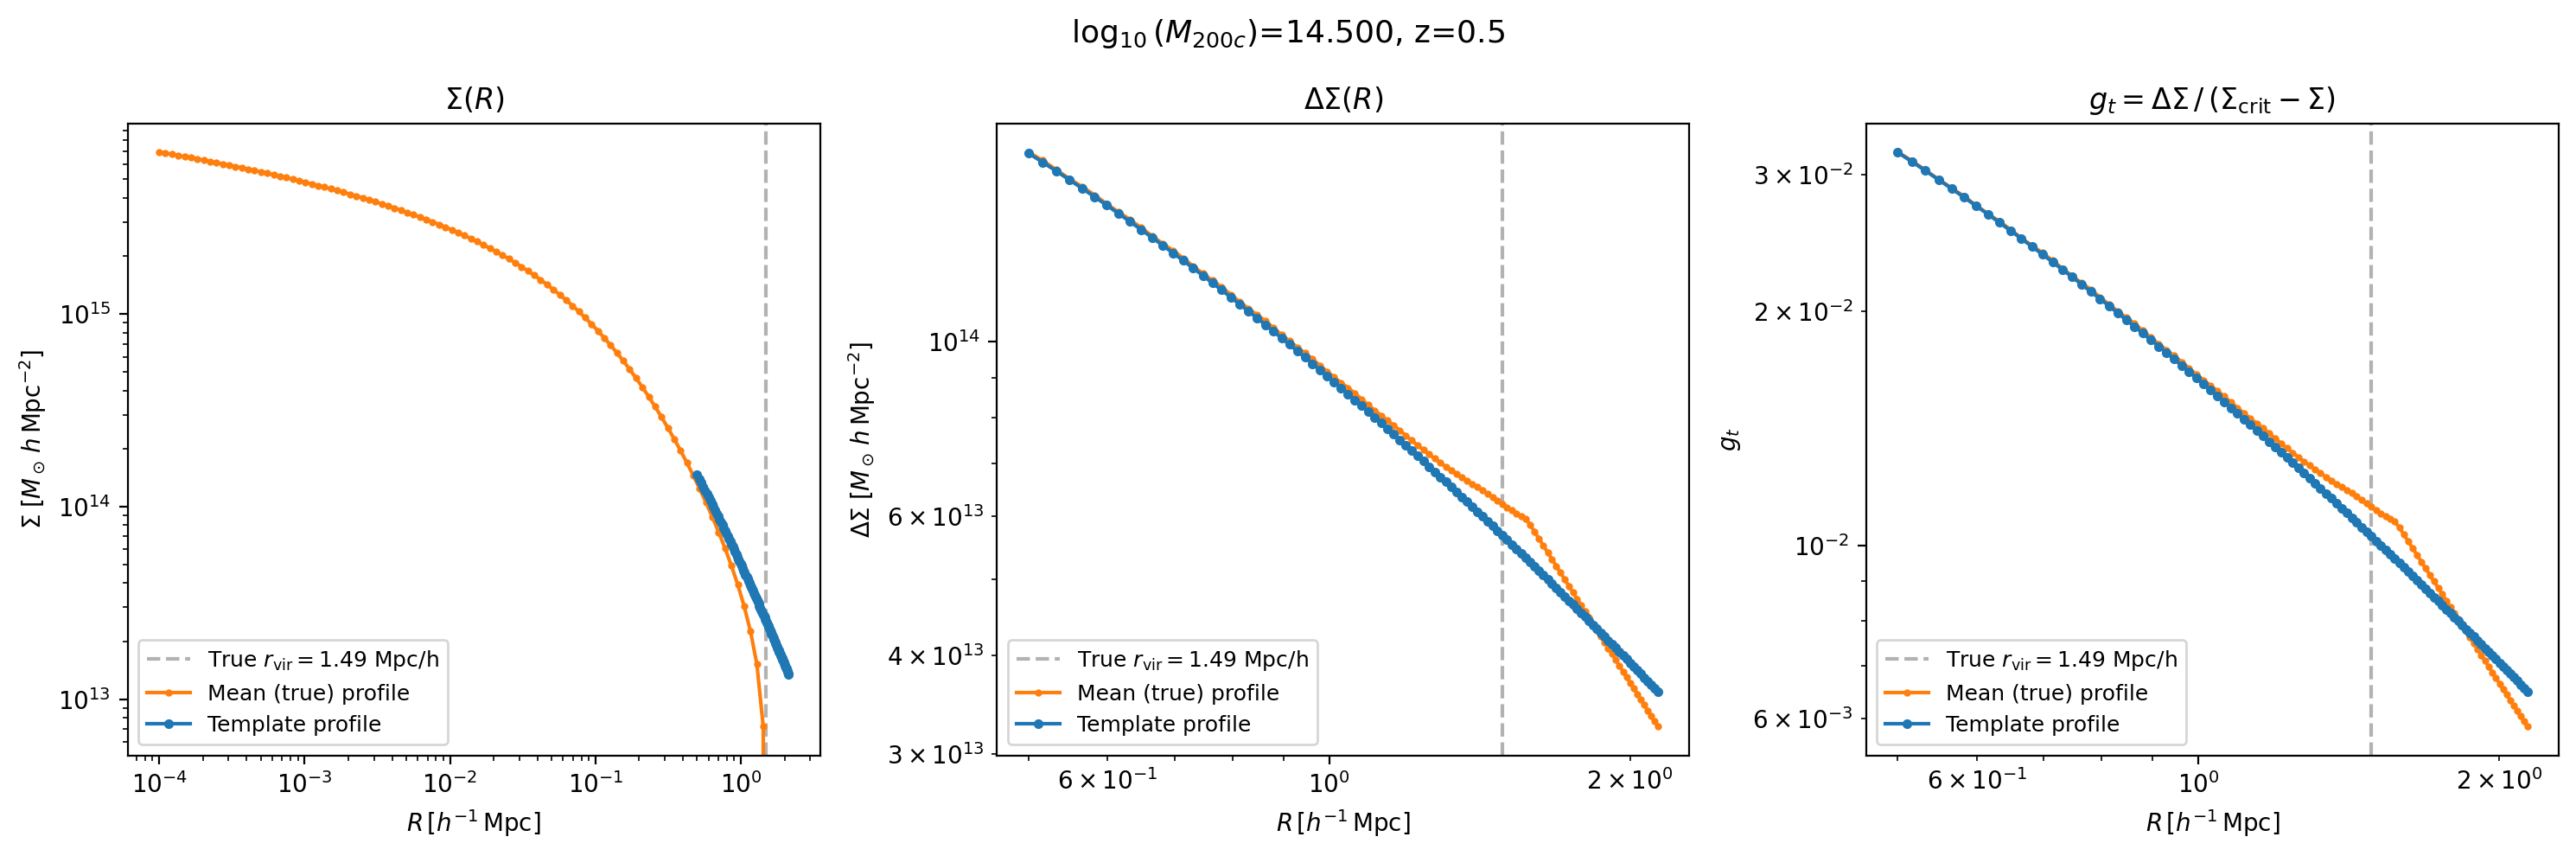

In [18]:
from wl_likelihoods import gt_nfw_from_profile
import matplotlib.pyplot as plt

z     = 0.5
M     = 10**14.5    # Msol/h
omega_m = 0.143344

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
ln_L, nc = get_log_likelihood_externalShear(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    A_s    = 2.1e-9,
    A_sz     = -4.4580166296603672,
    alpha_sz = 1.2468585981093097,
    beta_sz  = 0.8796081344595097,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    wl_catalogue = catalogue,
    use_shear_cache = True,
    return_nc = True
)

# ── Query cosmocnc profile at (z, M) ──────────────────────────────────────
profile = nc.get_profile_params_at_clusters(
    np.array([z]),
    np.array([[np.log(M / (h_fid * 1e14))]])
)

# ── rho_crit at z ─────────────────────────────────────────────────────────
rho_crit_raw = float(np.interp(z, Z_ARR, np.asarray(nc.rho_c)))
rho_crit_h   = rho_crit_raw / h_fid**2

# ── R200c and c_200c at (z, M) ────────────────────────────────────────────
M_Msol    = M / h_fid
R200c_Mpc = (M_Msol / ((4*np.pi/3) * 200 * rho_crit_raw))**(1./3.)
r_s_Mpc   = float(profile['r_s'][0, 0])
c_200c    = R200c_Mpc / r_s_Mpc

# ── Sigma_crit at z ───────────────────────────────────────────────────────
iz_z         = np.argmin(np.abs(Z_ARR - z))
Sigma_crit_h = get_Sigma_crit_arr(omega_m)[iz_z] / h_fid

# ── Radial bins ───────────────────────────────────────────────────────────
r_min  = 0.5
r_max  = 3.2 / (1. + z)
r_bins = np.linspace(r_min, r_max, 100)

# ── Analytic prediction ───────────────────────────────────────────────────
gt_pred = gt_nfw_from_profile(
    jnp.array(r_bins), M, rho_crit_h, c_200c, Sigma_crit_h)

# ── NFW components (numpy) ────────────────────────────────────────────────
def _f_nfw_np(x):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.ones_like(x)
    lt = x < 1.; gt_mask = x > 1.
    out[lt] = np.arctanh(np.sqrt(1-x[lt]**2)) / np.sqrt(1-x[lt]**2)
    out[gt_mask] = np.arctan(np.sqrt(x[gt_mask]**2-1)) / np.sqrt(x[gt_mask]**2-1)
    return out

def _g_nfw_np(x):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.full_like(x, 1.+np.log(0.5))
    lt = x < 1.; gt_mask = x > 1.
    out[lt] = np.log(x[lt]/2) + np.arctanh(np.sqrt(1-x[lt]**2))/np.sqrt(1-x[lt]**2)
    out[gt_mask] = np.log(x[gt_mask]/2) + np.arctan(np.sqrt(x[gt_mask]**2-1))/np.sqrt(x[gt_mask]**2-1)
    return out

def nfw_components(r_bins, M, rho_crit_h, c_200c):
    r_200 = (3.*M / (4.*np.pi*200.*rho_crit_h))**(1./3.)
    r_s   = r_200 / c_200c
    g_c   = np.log(1.+c_200c) - c_200c/(1.+c_200c)
    rho_s = M / (4.*np.pi*r_s**3*g_c)
    x     = r_bins / r_s
    Sigma     = 2.*rho_s*r_s / (x**2-1.) * (1.-_f_nfw_np(x))
    Sigma_bar = 4.*rho_s*r_s / x**2 * _g_nfw_np(x)
    return Sigma, Sigma_bar - Sigma

Sigma_pred, Delta_pred = nfw_components(r_bins, M, rho_crit_h, c_200c)

# ── Mock catalogue ────────────────────────────────────────────────────────
iz_cat = np.argmin(np.abs(catalogue['Z_ARR'] - z))
iM_cat = np.argmin(np.abs(np.array(catalogue['M200c_slices'][iz_cat]) - M))

gt_true    = catalogue['shear_profiles'][iz_cat][iM_cat]
Delta_true = catalogue['DeltaSigma_profiles'][iz_cat][iM_cat]
Sigma_true = catalogue['Sigma_profiles'][iz_cat][iM_cat]
R_true     = np.linspace(0.5, 3.2/(1.+z), 100)
R_for_Sigma = np.logspace(np.log10(1e-4), np.log10(3.2/(1+z)), 100)
r_vir_h    = catalogue['Rvir_slices'][iz_cat][iM_cat]

# ── Cache ─────────────────────────────────────────────────────────────────
cache    = np.load("/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_SHEAR_LCDM_CACHE.npz")
Z_grid   = cache["Z_ARR"]
M_grid   = np.exp(cache["lnM_common"])
R_common = cache["R_proj"]      # (nR,) — single static grid, FIX 1

iz_c  = np.argmin(np.abs(Z_grid - z))

b_WL_0    = 0.0
b_WL_M    = 1.0
lnM_pivot = np.log(2e14)
logM_wl   = b_WL_0 + b_WL_M*np.log(M) - b_WL_M*lnM_pivot + lnM_pivot
M_wl      = np.exp(logM_wl)
iM_c      = np.argmin(np.abs(M_grid - M_wl))

GT_cached = cache["GT_cache"][iz_c, iM_c]   # (nR,)
DS_cached = cache["DS_cache"][iz_c, iM_c]   # (nR,)
S_cached  = cache["S_cache"][iz_c,  iM_c]   # (nR,)
# FIX 2: all three use R_common, not R_proj[iz] or R_for_Sigma
R_cache   = R_common                         # (nR,) same for GT, DS, S

# ── Three-panel plot ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=200)
fig.suptitle(fr"$\log_{{10}}(M_{{200c}})$={np.log10(M):.3f}, z={z}", fontsize=13)

kw_pred  = dict(label='Template profile', color='C0', marker='o',  ms=3, lw=1.5)
kw_mock  = dict(label='Mean (true) profile',      color='C1', marker='.',  ms=4, lw=1.5)
#kw_cache = dict(label='Numeric template profile',    color='C2', marker='',   linestyle='--', lw=1.5)

for ax in axes:
    ax.axvline(r_vir_h, color='gray', linestyle='--', alpha=0.6,
               label=fr'True $r_{{\rm vir}}={r_vir_h:.2f}$ Mpc/h')


axes[0].loglog(R_for_Sigma, Sigma_true,  **kw_mock)
axes[0].loglog(r_bins,      Sigma_pred,  **kw_pred)
#axes[0].loglog(R_cache,     S_cached,    **kw_cache)
axes[0].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$\Sigma\;[M_\odot\,h\,\mathrm{Mpc}^{-2}]$",
            title=r"$\Sigma(R)$")
axes[0].legend(fontsize=9)


axes[1].loglog(R_true,  Delta_true,  **kw_mock)
axes[1].loglog(r_bins,  Delta_pred,  **kw_pred)
#axes[1].loglog(R_cache, DS_cached,   **kw_cache)
axes[1].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$\Delta\Sigma\;[M_\odot\,h\,\mathrm{Mpc}^{-2}]$",
            title=r"$\Delta\Sigma(R)$")
axes[1].legend(fontsize=9)

axes[2].loglog(R_true,  gt_true,           **kw_mock)
axes[2].loglog(r_bins,  np.array(gt_pred), **kw_pred)
#axes[2].loglog(R_cache, GT_cached,         **kw_cache)
axes[2].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$g_t$",
            title=r"$g_t = \Delta\Sigma\,/\,(\Sigma_{\rm crit} - \Sigma)$")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [162]:
import numpy as np
import pandas as pd
from tqdm import tqdm

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
b_WL_0_grid = np.linspace(-0.2, 0.2, 8)
b_WL_M_grid = np.linspace(0.8, 1.2, 8)

print("Numeric Likelihoods")
numeric_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood_externalShear(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            A_s    = 2.1e-9,
            A_sz     = -4.4580166296603672,
            alpha_sz = 1.2468585981093097,
            beta_sz  = 0.8796081344595097,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=True
        )
        numeric_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Analytic Likelihoods")
analytic_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood_externalShear(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            A_s    = 2.1e-9,
            A_sz     = -4.4580166296603672,
            alpha_sz = 1.2468585981093097,
            beta_sz  = 0.8796081344595097,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=False
        )
        analytic_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Analytic Likelihoods (zmax=08)")
analytic08_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood_externalShear(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            A_s    = 2.1e-9,
            A_sz     = -4.4580166296603672,
            alpha_sz = 1.2468585981093097,
            beta_sz  = 0.8796081344595097,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=False,
            wl_z_max = 0.8
        )
        analytic08_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Cosmocnc Likelihood")
cosmocnc_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz     = -4.4580166296603672,
            alpha_sz = 1.2468585981093097,
            beta_sz  = 0.8796081344595097,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M
        )
        cosmocnc_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })


Numeric Likelihoods


  0%|          | 0/8 [00:00<?, ?it/s]

cosmocnc output: 166215.14440058678
Manual integration: -1103905.7271518535
cosmocnc output: 166215.14440058678
Manual integration: -1103417.4208191123
cosmocnc output: 166215.14440058678
Manual integration: -1102994.6448836534
cosmocnc output: 166215.14440058678
Manual integration: -1102647.0536028682
cosmocnc output: 166215.14440058678
Manual integration: -1102383.9197259627
cosmocnc output: 166215.14440058678
Manual integration: -1102213.7996236503
cosmocnc output: 166215.14440058678
Manual integration: -1102144.3117862088
cosmocnc output: 166215.14440058678


 12%|█▎        | 1/8 [00:49<05:44, 49.22s/it]

Manual integration: -1102181.951962448
cosmocnc output: 166215.14440058678
Manual integration: -1103273.4156251203
cosmocnc output: 166215.14440058678
Manual integration: -1102847.2951210134
cosmocnc output: 166215.14440058678
Manual integration: -1102494.4929205996
cosmocnc output: 166215.14440058678
Manual integration: -1102224.754563805
cosmocnc output: 166215.14440058678
Manual integration: -1102047.241810527
cosmocnc output: 166215.14440058678
Manual integration: -1101970.246162882
cosmocnc output: 166215.14440058678
Manual integration: -1102000.9789139403
cosmocnc output: 166215.14440058678


 25%|██▌       | 2/8 [01:37<04:53, 48.89s/it]

... (46 outputs left out)

Manual integration: -1246000.0379769546
cosmocnc output: 166215.14440058678
Manual integration: -1243624.152827902
cosmocnc output: 166215.14440058678
Manual integration: -1243725.361141177
cosmocnc output: 166215.14440058678
Manual integration: -1243943.7972614376
cosmocnc output: 166215.14440058678
Manual integration: -1244288.3223158333
cosmocnc output: 166215.14440058678
Manual integration: -1244766.373552195
cosmocnc output: 166215.14440058678
Manual integration: -1245383.7528222518
cosmocnc output: 166215.14440058678
Manual integration: -1246144.5316414547
cosmocnc output: 166215.14440058678


100%|██████████| 8/8 [04:55<00:00, 36.91s/it]


Manual integration: -1247051.0586968907
Cosmocnc Likelihood


100%|██████████| 8/8 [01:32<00:00, 11.61s/it]


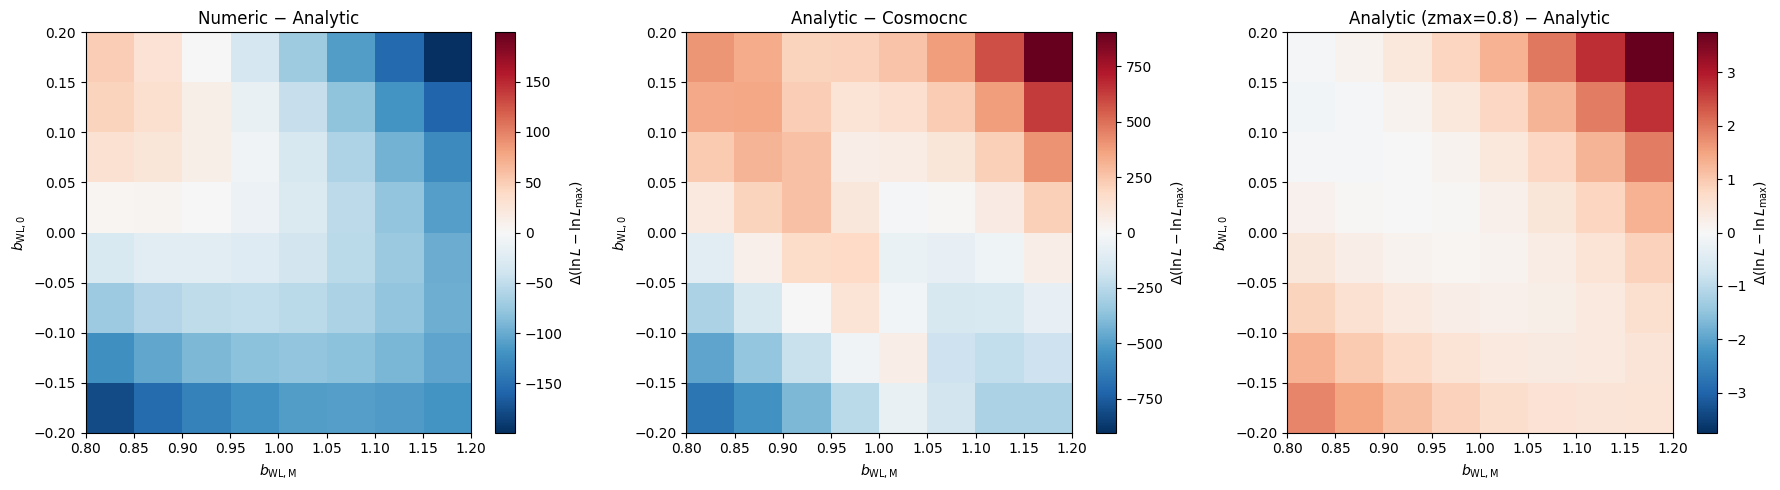

In [163]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

analytic = pd.DataFrame(analytic_likelihoods)
numeric = pd.DataFrame(numeric_likelihoods)
cosmocnc_L = pd.DataFrame(cosmocnc_likelihoods)
analytic08 = pd.DataFrame(analytic08_likelihoods)

def shape_difference(df1, df2):
    df1 = df1.copy()
    df2 = df2.copy()

    # Remove arbitrary likelihood normalization
    df1["dlnL"] = df1["ln_L"] - df1["ln_L"].max()
    df2["dlnL"] = df2["ln_L"] - df2["ln_L"].max()

    merged = df1.merge(
        df2,
        on=["b_WL_0", "b_WL_M"],
        suffixes=("_1", "_2")
    )

    merged["delta_shape"] = (
        merged["dlnL_1"] - merged["dlnL_2"]
    )

    return merged

comparisons = {
    "Numeric − Analytic": shape_difference(
        numeric, analytic
    ),
    "Analytic − Cosmocnc": shape_difference(
        numeric, cosmocnc_L
    ),
    "Analytic (zmax=0.8) − Analytic": shape_difference(
        analytic08, analytic
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, df) in zip(axes, comparisons.items()):

    heatmap = df.pivot(
        index="b_WL_0",
        columns="b_WL_M",
        values="delta_shape"
    )

    vmax = np.nanmax(np.abs(heatmap.values))

    im = ax.imshow(
        heatmap.values,
        origin="lower",
        aspect="auto",
        extent=[
            heatmap.columns.min(),
            heatmap.columns.max(),
            heatmap.index.min(),
            heatmap.index.max(),
        ],
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
    )

    ax.set_title(title)
    ax.set_xlabel(r"$b_{\rm WL,M}$")
    ax.set_ylabel(r"$b_{\rm WL,0}$")

    plt.colorbar(
        im,
        ax=ax,
        label=r"$\Delta(\ln L-\ln L_{\max})$"
    )

plt.tight_layout()
plt.show()

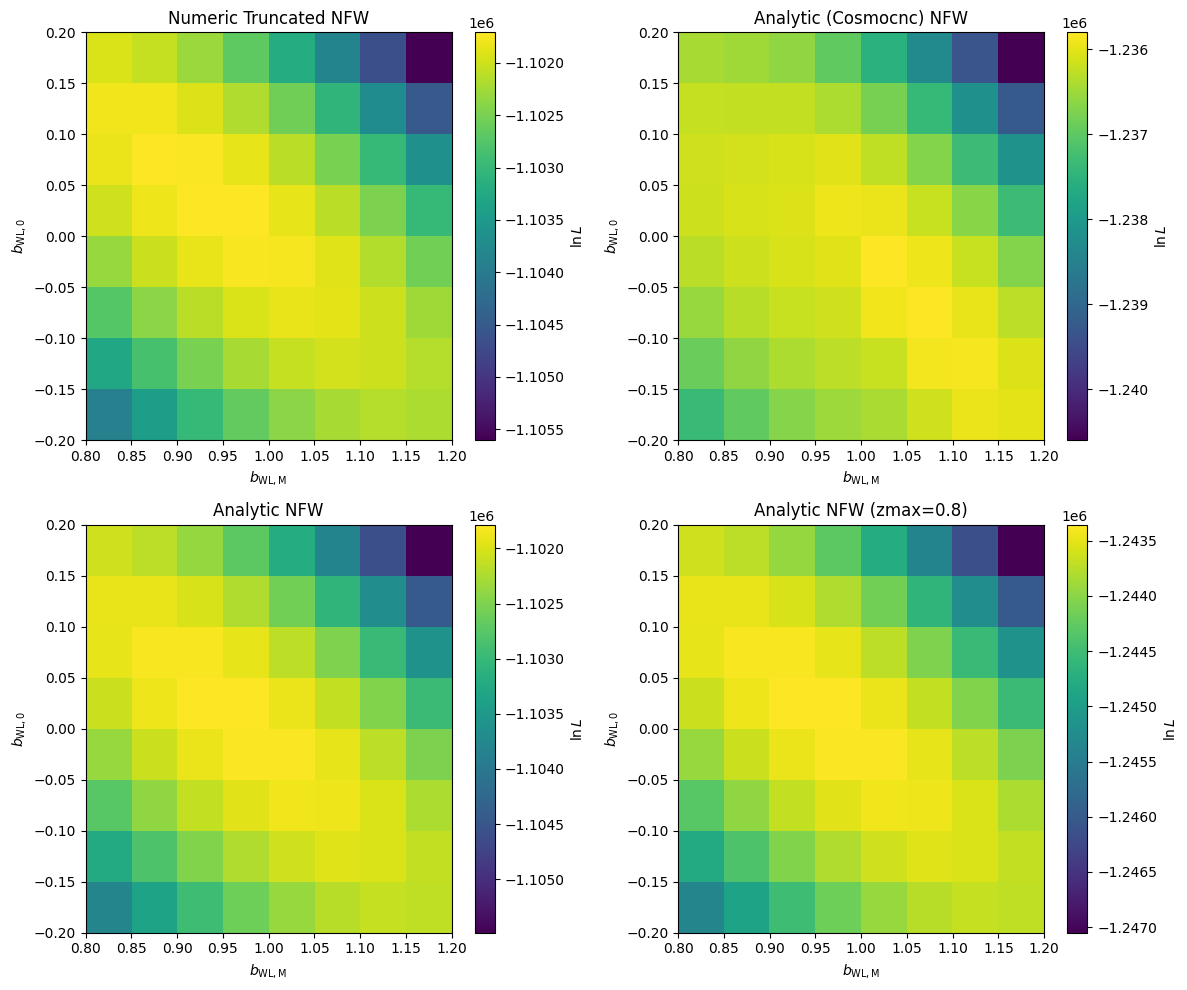

In [166]:
import pandas as pd
import matplotlib.pyplot as plt

datasets = {
    "Numeric Truncated NFW": pd.DataFrame(numeric_likelihoods),
    "Analytic (Cosmocnc) NFW": pd.DataFrame(cosmocnc_likelihoods),
    "Analytic NFW": pd.DataFrame(analytic_likelihoods),
    "Analytic NFW (zmax=0.8)": pd.DataFrame(analytic08_likelihoods),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (title, df) in zip(axes.flat, datasets.items()):

    heatmap = df.pivot(
        index="b_WL_0",
        columns="b_WL_M",
        values="ln_L"
    )

    im = ax.imshow(
        heatmap.values,
        origin="lower",
        aspect="auto",
        extent=[
            heatmap.columns.min(),
            heatmap.columns.max(),
            heatmap.index.min(),
            heatmap.index.max(),
        ],
    )

    ax.set_title(title)
    ax.set_xlabel(r"$b_{\rm WL,M}$")
    ax.set_ylabel(r"$b_{\rm WL,0}$")

    plt.colorbar(im, ax=ax, label=r"$\ln L$")

plt.tight_layout()
plt.show()

###### Consistency Checks (second pass)

In [19]:
def _smooth_log_jacobian(M200c_coarse, Mvir_coarse):
    """
    Compute d(lnMvir)/d(lnM200c) using central differences in log-log space.
    Uses forward/backward at endpoints but with larger stencil to avoid
    the one-sided difference instability of np.gradient.
    """
    n = len(M200c_coarse)
    lnM200c = np.log(M200c_coarse)
    lnMvir  = np.log(Mvir_coarse)
    result  = np.zeros(n)

    # Central differences for interior points
    result[1:-1] = (lnMvir[2:] - lnMvir[:-2]) / (lnM200c[2:] - lnM200c[:-2])

    # Forward/backward at endpoints
    result[0]  = (lnMvir[1]  - lnMvir[0])  / (lnM200c[1]  - lnM200c[0])
    result[-1] = (lnMvir[-1] - lnMvir[-2]) / (lnM200c[-1] - lnM200c[-2])

    return result

import pickle
import numpy as np
from scipy.special import gamma as Gamma
from scipy.integrate import simpson as scipy_simpson

# ══════════════════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════════════════

HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"

Z_TEST  = 0.5          # redshift at which to compare (pick a mid-range value)
M_TEST  = 3.0e14       # Msol/h — reference mass for point comparisons

H_FID   = 0.68
OMEGA_M = 0.143344
A_S = 2.1e-9

# cosmocnc call parameters (must match what nc was initialised with)
A_SZ     = -4.4580166296603672
ALPHA_SZ = 1.2468585981093097
BETA_SZ  = 0.8796081344595097

M_TRANSITION = 10**12.5

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

# ── adjust these two lines ────────────────────────────────────────────────────
from feedback_mimic import (
    dn_dlog10Mtot, get_realspace_profile, get_NFW_profile,
    dV_dz, Mtot_to_MDelta, get_some_quantities,
)

# ══════════════════════════════════════════════════════════════════════════════
# LOAD HALO MODEL DATA SLICE
# ══════════════════════════════════════════════════════════════════════════════

def sep(title):
    print(f"\n{'='*60}")
    print(f"  {title}")
    print("=" * 60)

sep("Loading halo model slice")

with open(f"{HALO_INPUT_FILE}/{Z_TEST}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data = pickle.load(f)

omega_m_data = data['cosmos']['omega_m_0']
h_data       = data['cosmos']['h']
Om0          = omega_m_data / h_data**2

print(f"  z_test          = {Z_TEST}")
print(f"  omega_m (data)  = {omega_m_data:.6f}")
print(f"  h (data)        = {h_data:.4f}")
print(f"  Om0             = {Om0:.6f}")
print(f"  M_test          = {M_TEST:.3e} Msol/h")

# ══════════════════════════════════════════════════════════════════════════════
# INITIALISE COSMOCNC
# ══════════════════════════════════════════════════════════════════════════════

sep("Initialising cosmocnc")

lnL, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = OMEGA_M,
    A_s      = A_S,
    A_sz     = A_SZ,
    alpha_sz = ALPHA_SZ,
    beta_sz  = BETA_SZ,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True
)

h_cnc  = nc.cosmo_params["h"]
Om0_cnc = nc.cosmo_params["Om0"]

print(f"  h (cosmocnc)    = {h_cnc:.4f}")
print(f"  Om0 (cosmocnc)  = {Om0_cnc:.6f}")
print(f"  H0 (cosmocnc)   = {nc.cosmology.background_cosmology.H0.value:.4f}")
print(f"\n  CHECK: h should match between data and cosmocnc")
print(f"    data h = {h_data:.4f},  cnc h = {h_cnc:.4f},  match = {abs(h_data-h_cnc)<1e-4}")
print(f"    data Om0 = {Om0:.6f},  cnc Om0 = {Om0_cnc:.6f},  match = {abs(Om0-Om0_cnc)<1e-4}")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 1: CRITICAL DENSITY rho_crit(z)
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 1: Critical density rho_crit(z)")

# Generation side: from get_some_quantities
_, rho_crit_gen, _, _, _, _, _, _ = get_some_quantities(data)
# Units from halo model — print raw value and infer units
print(f"  rho_crit from data (raw)   = {rho_crit_gen:.6e}")

# What units? Compare to astropy
from astropy.cosmology import FlatLambdaCDM
cosmo_astropy = FlatLambdaCDM(H0=h_data * 100., Om0=Om0)
rho_crit_astropy_Msol_Mpc3 = (
    cosmo_astropy.critical_density(Z_TEST).value
    * 1000. * (3.08567758149137e22)**3 / 1.98855e30
)
print(f"  rho_crit astropy [Msol/Mpc³] = {rho_crit_astropy_Msol_Mpc3:.6e}")
print(f"  rho_crit astropy [Msol/h/( Mpc/h)³] = {rho_crit_astropy_Msol_Mpc3/h_data**2:.6e}")
print(f"  ratio data/astropy_Msol_Mpc3 = {rho_crit_gen/rho_crit_astropy_Msol_Mpc3:.6f}")
print(f"  → data rho_crit is in Msol/Mpc³: {abs(rho_crit_gen/rho_crit_astropy_Msol_Mpc3 - 1) < 0.01}")

# cosmocnc side
iz_cnc = np.argmin(np.abs(np.asarray(nc.redshift_vec) - Z_TEST))
rho_crit_cnc_Msol_Mpc3 = float(nc.rho_c[iz_cnc])
rho_c0_cnc = nc.halo_mass_function.rho_c_0
E_z_cnc = float(nc.E_z[iz_cnc])
rho_crit_cnc_from_E = rho_c0_cnc * E_z_cnc**2

print(f"\n  cosmocnc rho_c[iz] [Msol/Mpc³]  = {rho_crit_cnc_Msol_Mpc3:.6e}")
print(f"  cosmocnc rho_c0*E²  [Msol/Mpc³] = {rho_crit_cnc_from_E:.6e}")
print(f"  cosmocnc H0.value               = {nc.cosmology.background_cosmology.H0.value:.4f}")

print(f"\n  COMPARISON rho_crit(z={Z_TEST}):")
print(f"    generation  = {rho_crit_gen:.6e}  Msol/Mpc³")
print(f"    cosmocnc    = {rho_crit_cnc_Msol_Mpc3:.6e}  Msol/Mpc³")
print(f"    ratio       = {rho_crit_gen / rho_crit_cnc_Msol_Mpc3:.6f}  (should be 1.0)")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 2: VIRIAL OVERDENSITY Delta_vir
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 2: Virial overdensity Delta_vir")

# Generation side
_, _, _, _, _, Delta_vir_gen, _, _ = get_some_quantities(data)
print(f"  Delta_vir (generation) = {Delta_vir_gen:.6f}")

# cosmocnc side
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    func_axionHMcode_Delta_vir,
    func_axionHMcode_delta_c,
)
E_z_fn = lambda z: nc.cosmology.background_cosmology.H(z).value / (h_cnc * 100.)
g_a_cnc = (
    np.interp(Z_TEST, nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full)
    * nc.cosmology.normalisation_cached * (1 + Z_TEST)
)
G_a_cnc = nc.cosmology.G_a_cached
Delta_vir_cnc = func_axionHMcode_Delta_vir(Z_TEST, Om0_cnc, G_a_cnc, E_z_fn, g_a_cnc)
delta_c_cnc   = func_axionHMcode_delta_c(  Z_TEST, Om0_cnc, G_a_cnc, E_z_fn, g_a_cnc)

print(f"  Delta_vir (cosmocnc)   = {Delta_vir_cnc:.6f}")
print(f"  delta_c   (cosmocnc)   = {delta_c_cnc:.6f}")
print(f"  ratio Delta_vir        = {Delta_vir_gen / Delta_vir_cnc:.6f}  (should be 1.0)")

# Generation side delta_c equivalent
# Your halo model uses fixed delta_c=1.686 (Press-Schechter) or the axionHMcode version?
# Print what G_a your data slice stores
print(f"\n  G_a from data['cosmos'] = {data['cosmos'].get('G_a', 'not stored'):.6f}")
print(f"  G_a from cosmocnc       = {G_a_cnc:.6f}")
print(f"  These must match for Delta_vir and delta_c to agree")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 3: Mvir <-> M200c CONVERSION at M_TEST
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 3: Mvir <-> M200c conversion at M_test")

# Generation side: find Mvir corresponding to M200c ≈ M_TEST
valid = data['M'] > M_TRANSITION
Mtot_gen = data['M'][valid]
r_t_gen, rho_crit_g, rho_char_g, conc_g, r_s_gen, Dv_g, rho0_g, rho0wh_g = \
    get_some_quantities(data)
r_t_gen  = r_t_gen[valid]
r_s_gen  = r_s_gen[valid]
conc_g   = conc_g[valid]

rho_g  = get_realspace_profile(
    u_k=get_NFW_profile(r_v=r_t_gen, k_arr=K_ARR, r_s=r_s_gen, r_t=r_t_gen),
    r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_gen, r_t=r_t_gen)

M200c_gen, R200c_gen = Mtot_to_MDelta(
    data, r_t=r_t_gen, M_arr=Mtot_gen, r_arr=R_ARR,
    Del=200, reference_density="critical",
    axion_dic=None, rho=rho_g, k_arr=K_ARR)

order = np.argsort(M200c_gen)
M200c_gen = M200c_gen[order];  Mtot_gen  = Mtot_gen[order]
R200c_gen = R200c_gen[order];  r_s_gen   = r_s_gen[order]
conc_g    = conc_g[order]

# Interpolate to M_TEST
Mvir_at_test = np.interp(np.log(M_TEST), np.log(M200c_gen), np.log(Mtot_gen))
Mvir_at_test = np.exp(Mvir_at_test)   # Msol/h
R200c_at_test = np.interp(np.log(M_TEST), np.log(M200c_gen), np.log(R200c_gen))
R200c_at_test = np.exp(R200c_at_test)  # Mpc/h (from Mtot_to_MDelta units)

print(f"  Generation side at M200c = {M_TEST:.3e} Msol/h:")
print(f"    Mvir  = {Mvir_at_test:.6e}  Msol/h")
print(f"    R200c = {R200c_at_test:.6e}  Mpc/h")
print(f"    concentration (virial) = {np.interp(np.log(M_TEST), np.log(M200c_gen), np.log(conc_g)):.4f}")

# cosmocnc side: uses find_M_vir_from_M_200c
# M_TEST in Msol/h → Msol (cosmocnc works in Msol no h)
M_test_Msol = M_TEST / H_FID   # Msol
rho_m_cnc   = rho_c0_cnc * Om0_cnc   # Msol/Mpc³

R200c_cnc = (3. * M_test_Msol / (4. * np.pi * rho_crit_cnc_Msol_Mpc3 * 200.))**(1./3.)  # Mpc

from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    find_M_vir_from_M_200c, sigma_R, func_axionHMcode_z_formation_fast,
)
import jax.numpy as jnp

k_cnc, ps_cnc = nc.cosmology.power_spectrum.get_linear_power_spectrum(Z_TEST)
sr_cnc = sigma_R((jnp.asarray(k_cnc), jnp.asarray(ps_cnc)), cosmology=nc.cosmology)
sr_cnc.get_derivative(type_deriv="analytical")

M_test_arr = np.array([M_test_Msol])
R200c_arr  = np.array([R200c_cnc])

Mvir_cnc_arr = find_M_vir_from_M_200c(
    M_test_arr, R200c_arr, rho_m_cnc, rho_crit_cnc_Msol_Mpc3,
    Delta_vir_cnc, 5.196, Z_TEST, Om0_cnc, sr_cnc,
    nc.cosmology.normalisation_cached, delta_c_cnc, E_z_fn,
    nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full,
    min_factor=0.1, max_factor=20)

Mvir_cnc = float(Mvir_cnc_arr[0])   # Msol
Mvir_cnc_h = Mvir_cnc * H_FID       # Msol/h for comparison

print(f"\n  cosmocnc side at M200c = {M_TEST:.3e} Msol/h ({M_test_Msol:.3e} Msol):")
print(f"    Mvir  = {Mvir_cnc:.6e}  Msol  = {Mvir_cnc_h:.6e}  Msol/h")
print(f"    R200c = {R200c_cnc:.6e}  Mpc   = {R200c_cnc*H_FID:.6e}  Mpc/h")

print(f"\n  COMPARISON Mvir at M_test:")
print(f"    generation  = {Mvir_at_test:.6e}  Msol/h")
print(f"    cosmocnc    = {Mvir_cnc_h:.6e}  Msol/h")
print(f"    ratio       = {Mvir_at_test / Mvir_cnc_h:.6f}  (should be 1.0)")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 4: sigma(Mvir) — power spectrum normalisation
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 4: sigma(Mvir) from power spectrum")

# cosmocnc sigma at Mvir_cnc
rho_m_cnc_for_sigma = rho_m_cnc   # Msol/Mpc³ (mean matter density)
sigma_cnc_at_test = float(sr_cnc.get_sigma_M(
    jnp.array([Mvir_cnc]), rho_m_cnc_for_sigma, get_deriv=False)[0])

nu_cnc = delta_c_cnc / sigma_cnc_at_test

print(f"  cosmocnc sigma(Mvir) = {sigma_cnc_at_test:.6f}")
print(f"  cosmocnc nu = delta_c/sigma = {nu_cnc:.6f}")

# Generation sigma: your halo model stores sigma implicitly in dn_dlog10Mtot
# Extract it by comparing the HMF value to the ST formula
# dn/dlnMvir = rho_m/Mvir * |d ln sigma² / d ln Mvir| * f_ST(nu)
# Reconstruct numerically
Mtot_all, hmf_log10_all = dn_dlog10Mtot(data, 'LCDM')
hmf_all = hmf_log10_all / np.log(10)   # dn/dlnMvir [Mpc^-3] or [(Mpc/h)^-3]

# Interpolate at Mvir_at_test (in Msol/h)
hmf_at_test_gen = np.interp(np.log(Mvir_at_test), np.log(Mtot_all), hmf_all)

# cosmocnc dn/dlnMvir at the same Mvir (convert Mvir_cnc to Msol for sigma)
sigma_cnc_v, dsigmadR_cnc_v = sr_cnc.get_sigma_M(
    jnp.array([Mvir_cnc]), rho_m_cnc, get_deriv=True)
sigma_cnc_v    = float(sigma_cnc_v[0])
dsigmadR_cnc_v = float(dsigmadR_cnc_v[0])

R_lag = float(sr_cnc.R_eval[0])
dM_dR = 4. * np.pi * rho_m_cnc * R_lag**2
dlnsig2_dlnMvir = (Mvir_cnc / sigma_cnc_v**2) * (2.*sigma_cnc_v*dsigmadR_cnc_v) / dM_dR

nu_v = delta_c_cnc / sigma_cnc_v
p_st = 0.3; q_st = 0.707
A_st = np.sqrt(2.*q_st) / (np.sqrt(np.pi) + Gamma(0.5-p_st) / 2**p_st)
f_ST = A_st * nu_v * (1. + (q_st**0.5*nu_v)**(-2.*p_st)) * np.exp(-q_st*nu_v**2/2.)

hmf_cnc_vir = 0.5 * (rho_m_cnc / Mvir_cnc**2) * f_ST * abs(dlnsig2_dlnMvir) * Mvir_cnc
# → dn/dlnMvir [Mpc^-3]
hmf_cnc_vir_in_h_units = hmf_cnc_vir * H_FID**3   # → [(Mpc/h)^-3]

print(f"\n  dn/dlnMvir at Mvir={Mvir_at_test:.3e} Msol/h:")
print(f"    generation  = {hmf_at_test_gen:.6e}  [units of generation code]")
print(f"    cosmocnc    = {hmf_cnc_vir:.6e}  [Mpc^-3]")
print(f"    cosmocnc    = {hmf_cnc_vir_in_h_units:.6e}  [(Mpc/h)^-3]")
print(f"    ratio (gen / cnc in h-units) = {hmf_at_test_gen / hmf_cnc_vir_in_h_units:.6f}")
print(f"    If ~1: HMF amplitudes match")
print(f"    If ~h^3={H_FID**3:.4f}: generation is in Mpc^-3, not (Mpc/h)^-3")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 5: Jacobian d(lnM200c)/d(lnMvir)
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 5: Jacobian d(lnMvir)/d(lnM200c)")

# Generation side: numerical gradient
jac_gen = np.gradient(np.log(Mtot_gen)) / np.gradient(np.log(M200c_gen))
jac_gen_at_test = np.interp(np.log(M_TEST), np.log(M200c_gen), jac_gen)

# cosmocnc side: from _smooth_log_jacobian on coarse grid
n_coarse = nc.cosmo_params.get("n_mass_points_coarse", 50)
M_vec_cnc_grid = np.exp(np.linspace(
    np.log(nc.halo_mass_function.M_min),
    np.log(nc.halo_mass_function.M_max), n_coarse))
R200c_cnc_grid = (3.*M_vec_cnc_grid/(4.*np.pi*rho_crit_cnc_Msol_Mpc3*200.))**(1./3.)

Mvir_cnc_grid = find_M_vir_from_M_200c(
    M_vec_cnc_grid, R200c_cnc_grid, rho_m_cnc, rho_crit_cnc_Msol_Mpc3,
    Delta_vir_cnc, 5.196, Z_TEST, Om0_cnc, sr_cnc,
    nc.cosmology.normalisation_cached, delta_c_cnc, E_z_fn,
    nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full,
    min_factor=0.1, max_factor=20)

jac_cnc_grid = _smooth_log_jacobian(M_vec_cnc_grid, Mvir_cnc_grid)
jac_cnc_at_test = np.interp(np.log(M_test_Msol), np.log(M_vec_cnc_grid), jac_cnc_grid)

print(f"  Jacobian d(lnMvir)/d(lnM200c) at M_test:")
print(f"    generation  = {jac_gen_at_test:.6f}")
print(f"    cosmocnc    = {jac_cnc_at_test:.6f}")
print(f"    ratio       = {jac_gen_at_test / jac_cnc_at_test:.6f}  (should be 1.0)")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 6: dn/dlnM200c at M_test
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 6: dn/dlnM200c at M_test")

# Generation
hmf_M200c_gen_arr = np.interp(
    ln_M_target if False else np.log(M200c_gen),
    np.log(M200c_gen),
    (hmf_all[np.isin(Mtot_all, data['M'][valid])] *
     np.gradient(np.log(data['M'][valid])) / np.gradient(np.log(M200c_gen)))
    if False else
    np.interp(np.log(M200c_gen), np.log(Mtot_gen),
              hmf_all[:len(Mtot_gen)]) * jac_gen)

# Simpler: interpolate from already-computed arrays
hmf_M200c_gen_vals = np.interp(np.log(Mtot_gen), np.log(Mtot_all), hmf_all) * jac_gen
dn_dlnM200c_gen_at_test = np.interp(np.log(M_TEST), np.log(M200c_gen), hmf_M200c_gen_vals)

# cosmocnc
dn_dlnM200c_cnc_at_test = hmf_cnc_vir * jac_cnc_at_test   # Mpc^-3
dn_dlnM200c_cnc_h       = dn_dlnM200c_cnc_at_test * H_FID**3  # (Mpc/h)^-3

print(f"  dn/dlnM200c at M_test:")
print(f"    generation  = {dn_dlnM200c_gen_at_test:.6e}  [generation units]")
print(f"    cosmocnc    = {dn_dlnM200c_cnc_at_test:.6e}  [Mpc^-3]")
print(f"    cosmocnc    = {dn_dlnM200c_cnc_h:.6e}  [(Mpc/h)^-3]")
print(f"    ratio (gen / cnc_h) = {dn_dlnM200c_gen_at_test / dn_dlnM200c_cnc_h:.6f}")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 7: Volume element dV/dz
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 7: Volume element dV/dz")

dV_gen = dV_dz(data)   # full sphere, Mpc³
print(f"  dV_dz (generation, full sphere) = {dV_gen:.6e}  Mpc³")

# cosmocnc: differential_comoving_volume returns per sr
dV_cnc_per_sr = float(
    nc.cosmology.background_cosmology.differential_comoving_volume(Z_TEST).value)
dV_cnc_full   = dV_cnc_per_sr * 4. * np.pi   # full sphere Mpc³

# astropy reference
dV_astropy_per_sr = cosmo_astropy.differential_comoving_volume(Z_TEST).value  # Mpc³/sr
dV_astropy_full   = dV_astropy_per_sr * 4. * np.pi

print(f"  dV/dz (cosmocnc, per sr)        = {dV_cnc_per_sr:.6e}  Mpc³/sr")
print(f"  dV/dz (cosmocnc, full sphere)   = {dV_cnc_full:.6e}  Mpc³")
print(f"  dV/dz (astropy,  full sphere)   = {dV_astropy_full:.6e}  Mpc³")

print(f"\n  COMPARISON dV/dz (full sphere):")
print(f"    generation / astropy = {dV_gen / dV_astropy_full:.6f}  (should be 1.0)")
print(f"    cosmocnc   / astropy = {dV_cnc_full / dV_astropy_full:.6f}  (should be 1.0)")
print(f"    generation / cosmocnc = {dV_gen / dV_cnc_full:.6f}  (should be 1.0)")


# ══════════════════════════════════════════════════════════════════════════════
# BLOCK 8: dN/dz — full integral over mass at z_test
# ══════════════════════════════════════════════════════════════════════════════

sep("BLOCK 8: dN/dz (full integral over mass)")

# Generation: integrate dn/dlnM200c * dV/dz over ln_M
ln_M_gen_sorted = np.log(M200c_gen)
dndlnM_gen_sorted = hmf_M200c_gen_vals   # (Mpc/h)^-3

# Convert to Mpc^-3 for comparison
dndlnM_gen_Mpc3 = dndlnM_gen_sorted / H_FID**3

# dV_gen is Mpc³ (full sphere) — multiply by dn/dlnM [Mpc^-3] → dN/dlnM per dz
dN_dlnM_gen = dndlnM_gen_Mpc3 * dV_gen   # per dlnM, per dz

# Integrate over ln_M_200c (Msol/h range → but dV is h-independent)
N_z_gen = scipy_simpson(dN_dlnM_gen, x=ln_M_gen_sorted)
print(f"  Generation dN/dz at z={Z_TEST}  = {N_z_gen:.2f}")

# cosmocnc: from nc.n_z (already integrated)
iz_cnc = np.argmin(np.abs(np.asarray(nc.redshift_vec) - Z_TEST))
dz_cnc = float(nc.redshift_vec[1] - nc.redshift_vec[0])
dN_dz_cnc_at_test = float(nc.n_z[iz_cnc])
print(f"  cosmocnc n_z at z={Z_TEST}      = {dN_dz_cnc_at_test:.2f}  (per dz unit)")

# cosmocnc manual: integrate hmf_matrix at iz_cnc
hmf_row_cnc = np.asarray(nc.hmf_matrix[iz_cnc])   # dn/dlnM * dV * 4π * fsky
# Undo 4π * fsky to get raw dn/dlnM * dV/dz / sr
fsky = nc.scaling_relations["q_so_sim"].skyfracs[0]
# hmf_matrix = dn/dlnM * dV/dz/dOmega * 4pi * fsky  (from cnc.py)
N_z_cnc_manual = scipy_simpson(hmf_row_cnc, x=np.asarray(nc.ln_M)) / (4.*np.pi*fsky) \
                 * 4.*np.pi   # full sphere equivalent
print(f"  cosmocnc manual (from hmf_matrix, full sphere) = {N_z_cnc_manual:.2f}")
print(f"  ratio gen / cnc_manual = {N_z_gen / N_z_cnc_manual:.6f}  (should be 1.0)")


# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY
# ══════════════════════════════════════════════════════════════════════════════

sep("SUMMARY")

print(f"  Block 1 — rho_crit:      ratio = {rho_crit_gen / rho_crit_cnc_Msol_Mpc3:.5f}")
print(f"  Block 2 — Delta_vir:     ratio = {Delta_vir_gen / Delta_vir_cnc:.5f}")
print(f"  Block 3 — Mvir(M200c):   ratio = {Mvir_at_test / Mvir_cnc_h:.5f}")
print(f"  Block 4 — dn/dlnMvir:    ratio = {hmf_at_test_gen / hmf_cnc_vir_in_h_units:.5f}")
print(f"  Block 5 — Jacobian:      ratio = {jac_gen_at_test / jac_cnc_at_test:.5f}")
print(f"  Block 6 — dn/dlnM200c:   ratio = {dn_dlnM200c_gen_at_test / dn_dlnM200c_cnc_h:.5f}")
print(f"  Block 7 — dV/dz:         ratio gen/cnc = {dV_gen / dV_cnc_full:.5f}")
print(f"  Block 8 — dN/dz:         ratio = {N_z_gen / N_z_cnc_manual:.5f}")
print()
print("  Any ratio far from 1.0 indicates the source of the HMF discrepancy.")
print("  The first block with ratio ≠ 1 is the root cause;")
print("  downstream ratios are affected by the upstream error.")
print()
print(f"  nc.n_tot_hmf (cosmocnc total, no selection) = {float(nc.n_tot_hmf):.1f}")


  Loading halo model slice
  z_test          = 0.5
  omega_m (data)  = 0.143344
  h (data)        = 0.6800
  Om0             = 0.310000
  M_test          = 3.000e+14 Msol/h

  Initialising cosmocnc
  h (cosmocnc)    = 0.6800
  Om0 (cosmocnc)  = 0.310000
  H0 (cosmocnc)   = 68.0000

  CHECK: h should match between data and cosmocnc
    data h = 0.6800,  cnc h = 0.6800,  match = True
    data Om0 = 0.310000,  cnc Om0 = 0.310000,  match = True

  BLOCK 1: Critical density rho_crit(z)
  rho_crit from data (raw)   = 2.228181e+11
  rho_crit astropy [Msol/Mpc³] = 2.228024e+11
  rho_crit astropy [Msol/h/( Mpc/h)³] = 4.818390e+11
  ratio data/astropy_Msol_Mpc3 = 1.000070
  → data rho_crit is in Msol/Mpc³: True

  cosmocnc rho_c[iz] [Msol/Mpc³]  = 2.233109e+11
  cosmocnc rho_c0*E²  [Msol/Mpc³] = 2.233109e+11
  cosmocnc H0.value               = 68.0000

  COMPARISON rho_crit(z=0.5):
    generation  = 2.228181e+11  Msol/Mpc³
    cosmocnc    = 2.233109e+11  Msol/Mpc³
    ratio       = 0.997793  (s

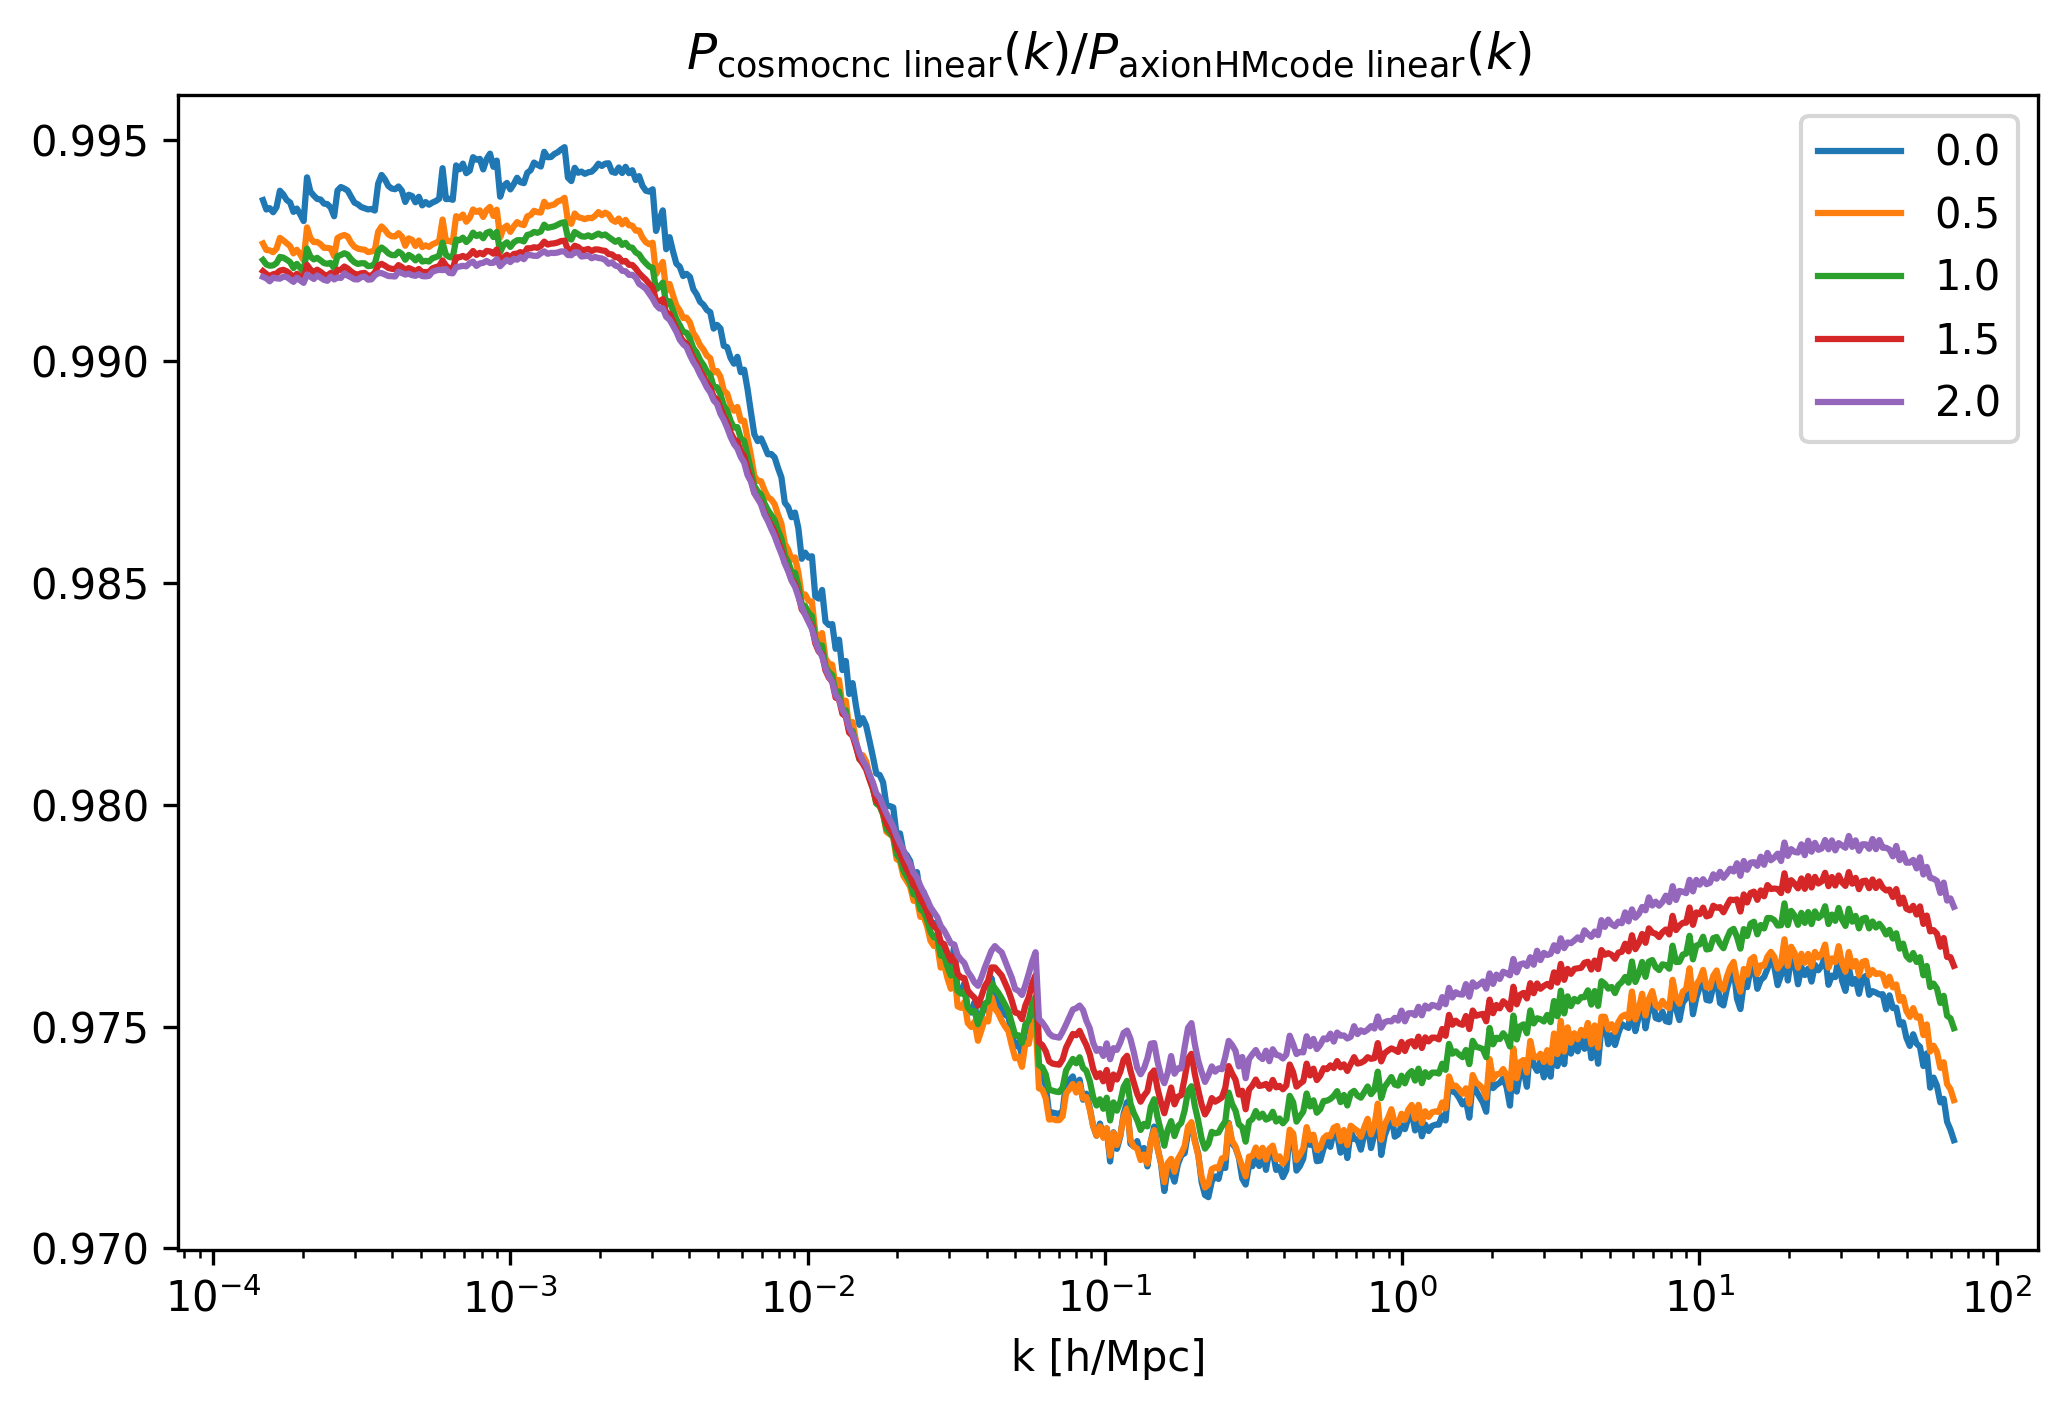

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(8,5),dpi=300)
for redshift in [0.0, 0.5, 1.0, 1.5, 2.0]:
    with open(f"results/halo_model/{redshift}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
    M_ARR_TEST = data_LCDM['M']
    ################### axionhmcode
    from axionHMcode.cosmology.variance import func_sigma_M
    HM_sigma = func_sigma_M(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos']['Omega_m_0'])
    from axionHMcode.halo_model.halo_mass_function import func_dlnsigma2_dlnM
    HM_dsigma2 = func_dlnsigma2_dlnM(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos'], data_LCDM['cosmos']['Omega_m_0'])
    ################### cosmocnc
    from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import sigma_R
    h_fid = 0.68
    rho_c_0 = nc.cosmology.background_cosmology.critical_density(0.).value*nc.const.mpc**3/nc.const.solar*1e3
    rho_m = rho_c_0*nc.cosmology.cosmo_params["Om0"]
    rho_m_for_sigma = rho_m / h_fid**2 
    k, ps   = nc.cosmology.power_spectrum.get_linear_power_spectrum(redshift)
    #sigma_r = sigma_R((data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total']), cosmology=nc.cosmology)
    sigma_r = sigma_R((k*h_fid**-1, ps*h_fid**3), cosmology=nc.cosmology)
    sigma_r.get_derivative(type_deriv="analytical")
    (sigma) = sigma_r.get_sigma_M(
        M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
    cnc_sigma = sigma
    sigma_r.get_dlnsigma2_dlnM(rho_m_for_sigma, h_fid)
    sigma = sigma_r.get_sigma_M(M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
    dlnsigma2_dlnMvir = sigma_r.get_dlnsigma2_dlnM_M(M_ARR_TEST, rho_m_for_sigma)
    cnc_dsigma2 = dlnsigma2_dlnMvir

    kh = k*h_fid**-1
    #plt.loglog(k*h_fid**-1, ps*h_fid**3)
    #plt.loglog(data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], ls='--')
    ps_interp = np.interp(k*h_fid**-1, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'])
    plt.semilogx(kh, ps*h_fid**3 / ps_interp, label=redshift)
plt.legend()
plt.xlabel("k [h/Mpc]")
plt.title(r"$P_\text{cosmocnc linear}(k)/P_\text{axionHMcode linear}(k)$")
plt.show()

In [24]:
redshift = 0.5
with open(f"results/halo_model/{redshift}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
M_ARR_TEST = data_LCDM['M']
################### axionhmcode
from axionHMcode.cosmology.variance import func_sigma_M
HM_sigma = func_sigma_M(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos']['Omega_m_0'])
from axionHMcode.halo_model.halo_mass_function import func_dlnsigma2_dlnM
HM_dsigma2 = func_dlnsigma2_dlnM(M_ARR_TEST, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos'], data_LCDM['cosmos']['Omega_m_0'])
################### cosmocnc
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import sigma_R
h_fid = 0.68
rho_c_0 = nc.cosmology.background_cosmology.critical_density(0.).value*nc.const.mpc**3/nc.const.solar*1e3
rho_m = rho_c_0*nc.cosmology.cosmo_params["Om0"]
rho_m_for_sigma = rho_m / h_fid**2 
k, ps   = nc.cosmology.power_spectrum.get_linear_power_spectrum(redshift)
#sigma_r = sigma_R((data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total']), cosmology=nc.cosmology)
sigma_r = sigma_R((k*h_fid**-1, ps*h_fid**3), cosmology=nc.cosmology)
sigma_r.get_derivative(type_deriv="analytical")
(sigma) = sigma_r.get_sigma_M(
    M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
cnc_sigma = sigma
sigma_r.get_dlnsigma2_dlnM(rho_m_for_sigma, h_fid)
sigma = sigma_r.get_sigma_M(M_ARR_TEST, rho_m_for_sigma, get_deriv=False)
dlnsigma2_dlnMvir = sigma_r.get_dlnsigma2_dlnM_M(M_ARR_TEST, rho_m_for_sigma)
cnc_dsigma2 = dlnsigma2_dlnMvir

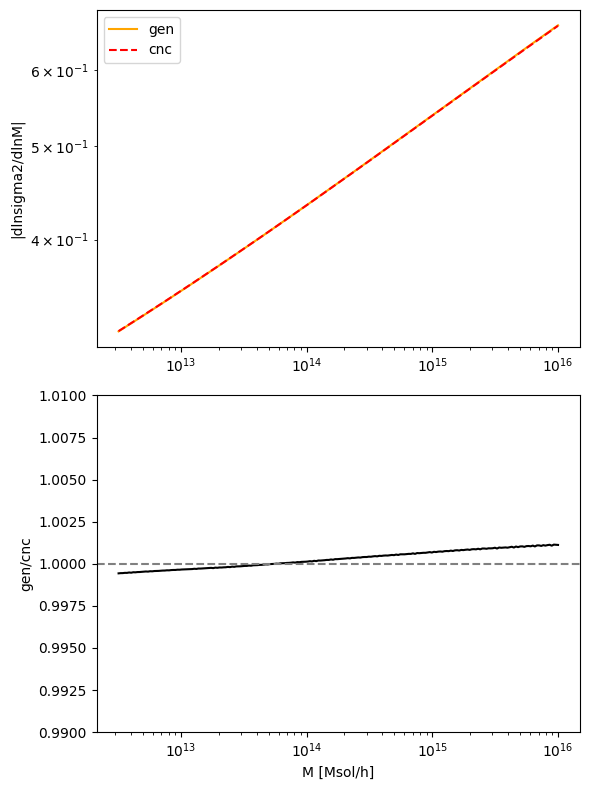

In [35]:
# Direct comparison of dlnsigma2/dlnM at z=0.5
z = redshift
with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data = pickle.load(f)

from axionHMcode.halo_model.halo_mass_function import func_dlnsigma2_dlnM
M_test = data['M'][data['M'] > M_TRANSITION]

# Generation
dlns2_gen = func_dlnsigma2_dlnM(
    M_test,
    data['power_spec_dic']['k'],
    data['power_spec_dic']['power_total'],
    data['cosmos'],
    data['cosmos']['Omega_m_0'])

# cosmocnc
k, ps   = nc.cosmology.power_spectrum.get_linear_power_spectrum(z)
k_h = np.asarray(k) / H_FID       # h/Mpc
ps_h = np.asarray(ps) * H_FID**3  # (Mpc/h)³
sr_test = sigma_R((jnp.asarray(k_h), jnp.asarray(ps_h)), cosmology=nc.cosmology)
sr_test.get_dlnsigma2_dlnM(rho_m_for_sigma, H_FID)
dlns2_cnc = sr_test.get_dlnsigma2_dlnM_M(
    jnp.asarray(M_test), rho_m_for_sigma)

ratio = np.abs(dlns2_gen) / np.abs(np.asarray(dlns2_cnc))

import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 8))
ax1.loglog(M_test, np.abs(dlns2_gen), label='gen', color='orange')
ax1.loglog(M_test, np.abs(np.asarray(dlns2_cnc)), label='cnc', color='red', ls='--')
ax1.set_ylabel('|dlnsigma2/dlnM|'); ax1.legend()
ax2.semilogx(M_test, ratio, color='k')
ax2.axhline(1, ls='--', color='gray')
ax2.set_ylim(0.99, 1.01)
ax2.set_xlabel('M [Msol/h]'); ax2.set_ylabel('gen/cnc')
plt.tight_layout()
plt.savefig('dlns2_ratio.pdf')

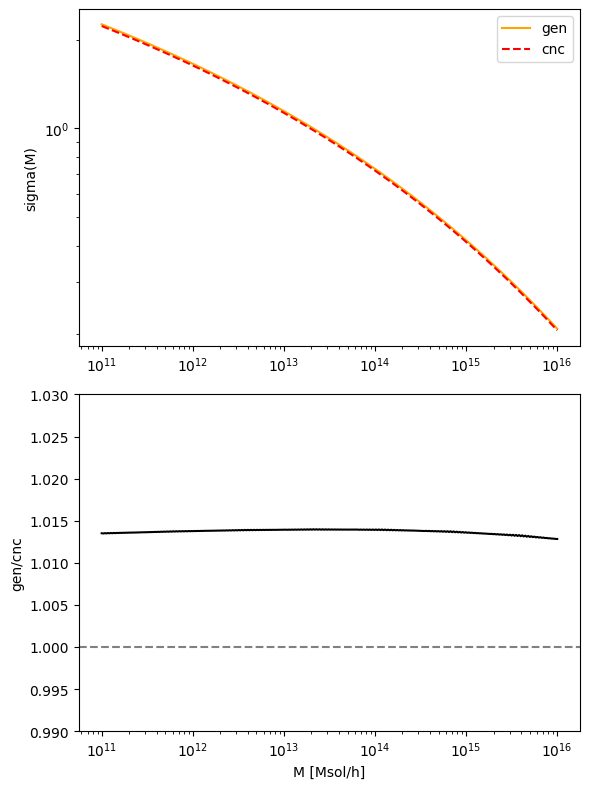

In [42]:
ratio = HM_sigma / cnc_sigma

import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 8))
ax1.loglog(M_ARR_TEST, HM_sigma, label='gen', color='orange')
ax1.loglog(M_ARR_TEST, cnc_sigma, label='cnc', color='red', ls='--')
ax1.set_ylabel('sigma(M)'); ax1.legend()
ax2.semilogx(M_ARR_TEST, ratio, color='k')
ax2.axhline(1, ls='--', color='gray')
ax2.set_ylim(0.99, 1.03)
ax2.set_xlabel('M [Msol/h]'); ax2.set_ylabel('gen/cnc')
plt.tight_layout()
plt.savefig('sigma_ratio.pdf')

In [43]:
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import func_axionHMcode_delta_c
Om0 = nc.cosmology.cosmo_params["Om0"]
Ow0 = 1. - Om0   # flat LCDM, no radiation
E_z = lambda z: np.sqrt(Om0*(1+z)**3 + Ow0)
g_a = (np.interp(redshift, nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full)
                           * nc.cosmology.normalisation_cached * (1 + redshift))
G_a = nc.cosmology.G_a_cached
cnc_delta_c = func_axionHMcode_delta_c(redshift, Om0, G_a, E_z, g_a)

from axionHMcode.cosmology.overdensities import func_delta_c
HM_delta_c = func_delta_c(redshift, 
                          data_LCDM['cosmos']['Omega_ax_0'], data_LCDM['cosmos']['Omega_m_0'], data_LCDM['cosmos']['Omega_w_0'], 
                          data_LCDM['cosmos']['G_a'], data_LCDM['cosmos']['version'])
print(HM_delta_c/cnc_delta_c)

from axionHMcode.halo_model.halo_mass_function import func_sheth_tormen
HM_nu = HM_delta_c / HM_sigma
HM_func_sheth_tormen = func_sheth_tormen(HM_nu)

cnc_nu = cnc_delta_c / cnc_sigma
p_st   = 0.3
q_st   = 0.707
A_st   = np.sqrt(2.*q_st) / (np.sqrt(np.pi) + Gamma(0.5 - p_st) / 2**p_st)
cnc_func_sheth_tormen = (A_st * cnc_nu
                      * (1. + (q_st**0.5 * cnc_nu)**(-2.*p_st))
                      * np.exp(-q_st * cnc_nu**2 / 2.))

1.0000168430813223


(0.5, 1.5)

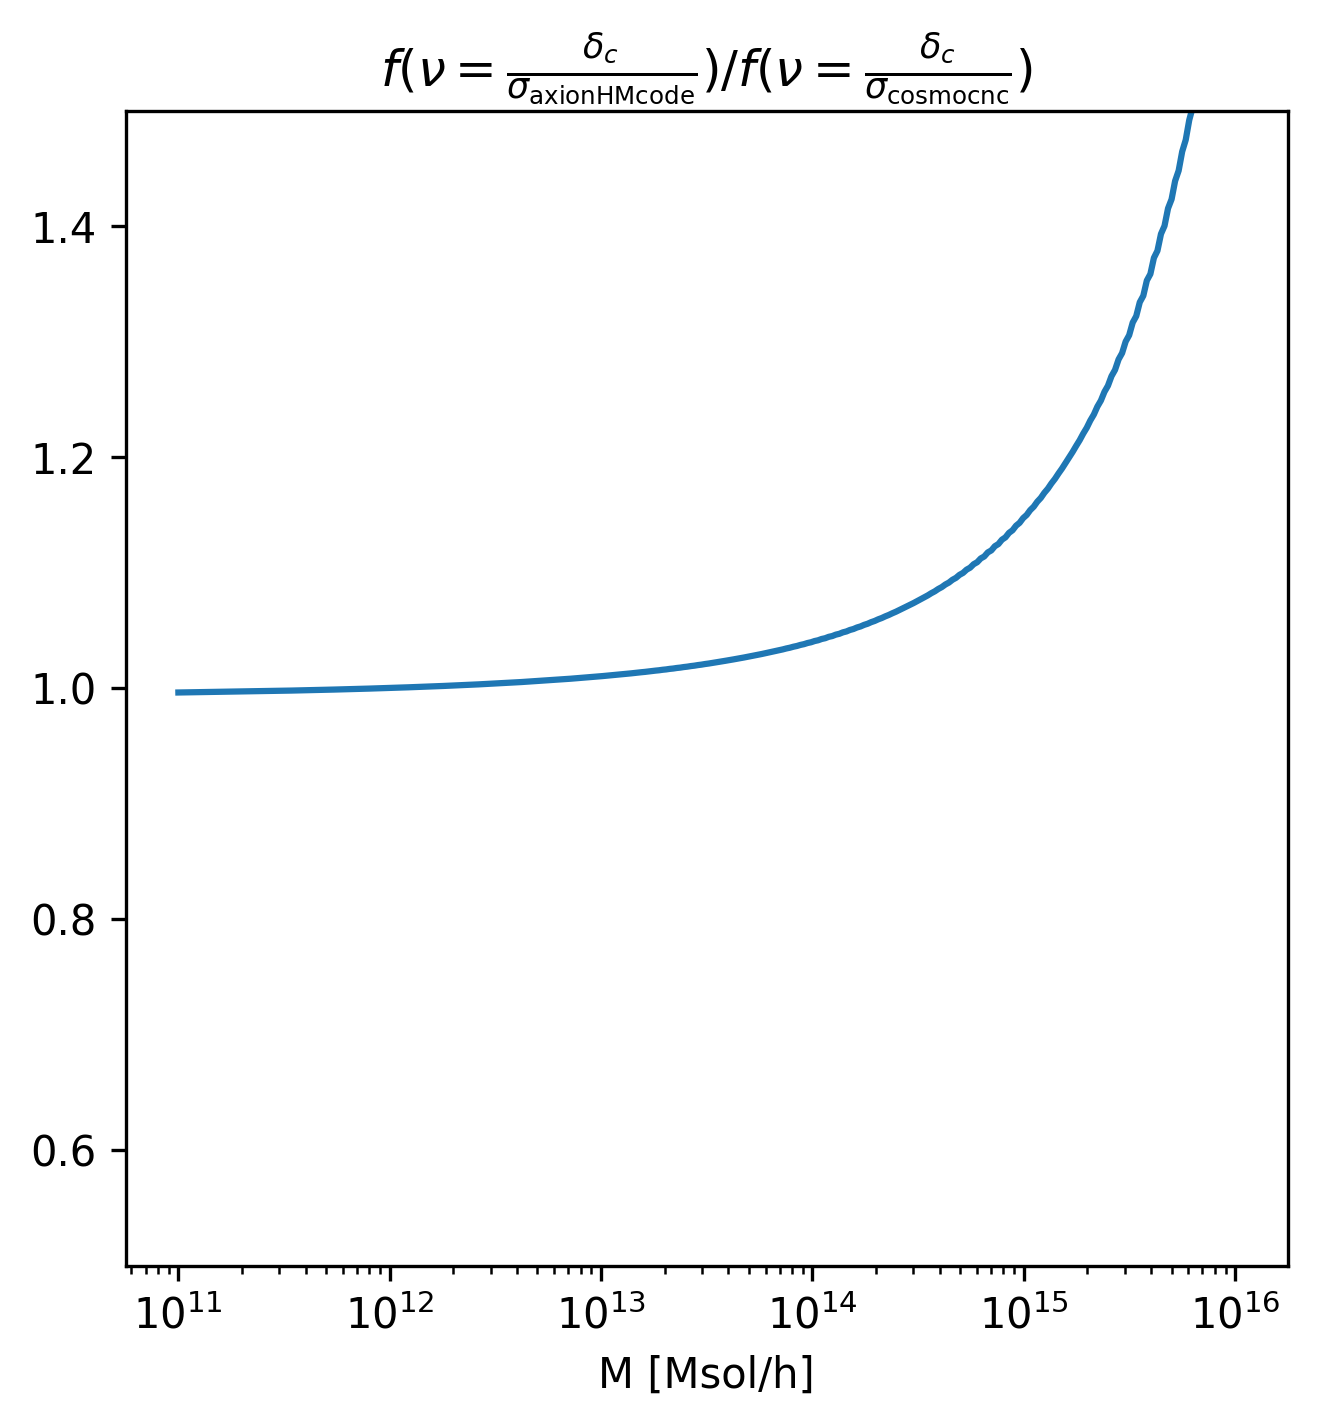

In [51]:
plt.figure(figsize=(5,5),dpi=300)
plt.semilogx(M_ARR_TEST, HM_func_sheth_tormen/cnc_func_sheth_tormen)
plt.title(r"$f(\nu = \frac{\delta_c}{\sigma_\text{axionHMcode}}) / f(\nu = \frac{\delta_c}{\sigma_\text{cosmocnc}})$")
plt.xlabel('M [Msol/h]')
plt.ylim(0.5,1.5)

In [52]:
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import func_axionHMcode_Delta_vir
cnc_Delta_vir = func_axionHMcode_Delta_vir(redshift, Om0, G_a, E_z, g_a)
from axionHMcode.cosmology.overdensities import func_Delta_vir
HM_Delta_vir = func_Delta_vir(redshift, 
                          data_LCDM['cosmos']['Omega_ax_0'], data_LCDM['cosmos']['Omega_m_0'], data_LCDM['cosmos']['Omega_w_0'], 
                          data_LCDM['cosmos']['G_a'], data_LCDM['cosmos']['version'])
print(HM_Delta_vir/cnc_Delta_vir)

0.9997471826528304


In [53]:
K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)
with open(f"results/halo_model/{redshift}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
Mvir = data_LCDM['M']
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, Mvir, K_ARR, R_ARR, Del=200, reference_density="critical"
)

from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import func_axionHMcode_Delta_vir
Om0 = nc.cosmology.cosmo_params["Om0"]
Ow0 = 1. - Om0   # flat LCDM, no radiation
E_z = lambda z: np.sqrt(Om0*(1+z)**3 + Ow0)
g_a = (np.interp(redshift, nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full)
                           * nc.cosmology.normalisation_cached * (1 + redshift))
G_a = nc.cosmology.G_a_cached
cnc_delta_c = func_axionHMcode_delta_c(redshift, Om0, G_a, E_z, g_a)
cnc_Delta_vir = func_axionHMcode_Delta_vir(redshift, Om0, G_a, E_z, g_a)
from axionHMcode.cosmology.overdensities import func_Delta_vir
HM_Delta_vir = func_Delta_vir(redshift, 
                          data_LCDM['cosmos']['Omega_ax_0'], data_LCDM['cosmos']['Omega_m_0'], data_LCDM['cosmos']['Omega_w_0'], 
                          data_LCDM['cosmos']['G_a'], data_LCDM['cosmos']['version'])
print(redshift)
print(HM_Delta_vir)
print(cnc_Delta_vir)
print(HM_Delta_vir/cnc_Delta_vir)

M200_cosmocnc = M200c_arr / h_fid #Msol
R200_cosmocnc = r200c_arr / h_fid  #Mpc
from cosmocnc_axionHMcode_jax.cosmocnc_jax import find_M_vir_from_M_200c
Mvir_cosmocnc = find_M_vir_from_M_200c(M200_cosmocnc, R200_cosmocnc, rho_m, 1.,
                            cnc_Delta_vir, 5.196, redshift, Om0, sigma_r,
                            nc.cosmology.normalisation_cached, cnc_delta_c, E_z,
                            nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full,
                            min_factor=0.1, max_factor=20, return_profile_params=False, h=0.68, num_points=300)

def find_M_vir_from_M_200c_OTHERSIGMA(M_vec, R_200c, rho_m, rho_crit_z,
                            Delta_vir, c_min, redshift, Om0, sigma_r,
                            normalisation, delta_c, E_z, D_grid_z_full, D_grid_full,
                            min_factor=0.1, max_factor=20, return_profile_params=False, h=0.68, num_points = 300):
    # Precompute z_formation grid (numpy, not JIT-able due to sigma_r)
    M_vir_grid = np.exp(np.linspace(
        np.log(min_factor * M_vec.min()),
        np.log(max_factor * M_vec.max()), num_points))
    z_formation_interp = func_axionHMcode_z_formation_fast_OTHERSIGMA(
        redshift, M_vir_grid, rho_m, Om0, sigma_r,
        normalisation, delta_c, E_z, D_grid_z_full, D_grid_full, h=h)

    log_M_vir_grid = jnp.asarray(np.log(M_vir_grid))
    z_f_grid = jnp.asarray(np.array([z_formation_interp(m) for m in M_vir_grid]))

    log_lo = jnp.log(jnp.asarray(min_factor * M_vec))
    log_hi = jnp.log(jnp.asarray(max_factor * M_vec))
    M200c_jnp = jnp.asarray(M_vec)
    R200c_jnp = jnp.asarray(R_200c)

    Mvir_vec, r_s_vec, delta_char_vec = _bisect_vmap(
        log_lo, log_hi, M200c_jnp, R200c_jnp,
        float(rho_m), float(Delta_vir), float(c_min), float(redshift),
        log_M_vir_grid, z_f_grid)

    if return_profile_params:
        R_vir_vec = (3. * Mvir_vec / (4. * jnp.pi * rho_m * Delta_vir))**(1./3.)
        return np.asarray(Mvir_vec), np.asarray(R_vir_vec), np.asarray(r_s_vec), np.asarray(delta_char_vec)
    return np.asarray(Mvir_vec)
def func_axionHMcode_z_formation_fast_OTHERSIGMA(redshift, M_vir_grid, rho_m, Om0,
                                      sigma_r, normalisation, delta_c, E_z,
                                      D_grid_z_full, D_grid_full, f=0.01, h=0.68):
    #Precomputes z_formation on a mass grid using vectorized sigma and a single precomputed D(z) interpolation table.
    # Precompute D(z)/D(0) on a z grid once
    mask = D_grid_z_full > redshift
    z_grid = D_grid_z_full[mask]
    D_grid = D_grid_full[mask]
    D_z = np.interp(redshift, D_grid_z_full, D_grid_full)

    # Vectorized sigma for all masses at once
    #sigma_grid = sigma_r.get_sigma_M(f * M_vir_grid * h, rho_m / h**2, get_deriv=False)
    sigma_grid = func_sigma_M(f * M_vir_grid * h, data_LCDM['power_spec_dic']['k'], data_LCDM['power_spec_dic']['power_total'], data_LCDM['cosmos']['Omega_m_0'])
    target_grid = D_z * delta_c / sigma_grid

    # For each mass, find z_f by interpolating the inverse D(z) table
    #def z_f_from_target(target):
    #    if target >= D_grid[0] or target <= D_grid[-1]:
    #        return redshift  # no root, z_f = z
    #    return np.interp(target, D_grid[::-1], z_grid[::-1])
    #z_f_grid = np.array([z_f_from_target(t) for t in target_grid])
    z_f_grid = np.where(
        (target_grid >= D_grid[0]) | (target_grid <= D_grid[-1]),
        redshift,
        np.interp(target_grid, D_grid[::-1], z_grid[::-1])
    )

    # Return a fast interpolator over log(Mvir)
    log_M_grid = np.log(M_vir_grid)
    def z_formation_interp(Mvir):
        return np.interp(np.log(Mvir), log_M_grid, z_f_grid)

    return z_formation_interp
def _bisect_single(log_lo, log_hi, M200c, R200c, rho_m, Delta_vir, c_min,
                   redshift, log_M_vir_grid, z_f_grid):
    def g(x):
        return jnp.log(1. + x) - x / (1. + x)

    def body(carry, _):
        lo, hi = carry
        mid = 0.5 * (lo + hi)
        Mvir = jnp.exp(mid)
        z_f = jnp.interp(mid, log_M_vir_grid, z_f_grid)
        conc = c_min * (1. + z_f) / (1. + redshift)
        R_vir = (3. * Mvir / (4. * jnp.pi * rho_m * Delta_vir))**(1./3.)
        r_s = R_vir / conc
        delta_char = Delta_vir * conc**3 / (3. * g(conc))
        # NFW enclosed mass uses rho_m (mean matter density at z=0), consistent with Delta_vir definition
        x_200c = R200c / r_s
        M_enc = 4. * jnp.pi * delta_char * rho_m * r_s**3 * g(x_200c)
        lo = jnp.where(M_enc < M200c, mid, lo)
        hi = jnp.where(M_enc < M200c, hi, mid)
        return (lo, hi), None

    (lo, hi), _ = jax.lax.scan(body, (log_lo, log_hi), None, length=30)
    mid = 0.5 * (lo + hi)
    Mvir = jnp.exp(mid)
    z_f = jnp.interp(mid, log_M_vir_grid, z_f_grid)
    conc = c_min * (1. + z_f) / (1. + redshift)
    R_vir = (3. * Mvir / (4. * jnp.pi * rho_m * Delta_vir))**(1./3.)
    r_s = R_vir / conc
    delta_char = Delta_vir * conc**3 / (3. * g(conc))
    return Mvir, r_s, delta_char
_bisect_vmap = jax.jit(jax.vmap(_bisect_single,
    in_axes=(0, 0, 0, 0, None, None, None, None, None, None)))

Mvir_cosmocnc_HMsigma = find_M_vir_from_M_200c_OTHERSIGMA(M200_cosmocnc, R200_cosmocnc, rho_m, 1.,
                            cnc_Delta_vir, 5.196, redshift, Om0, sigma_r,
                            nc.cosmology.normalisation_cached, cnc_delta_c, E_z,
                            nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full,
                            min_factor=0.1, max_factor=20, return_profile_params=False, h=0.68, num_points=500)

0.5
385.49913074209525
385.5966162556946
0.9997471826528304


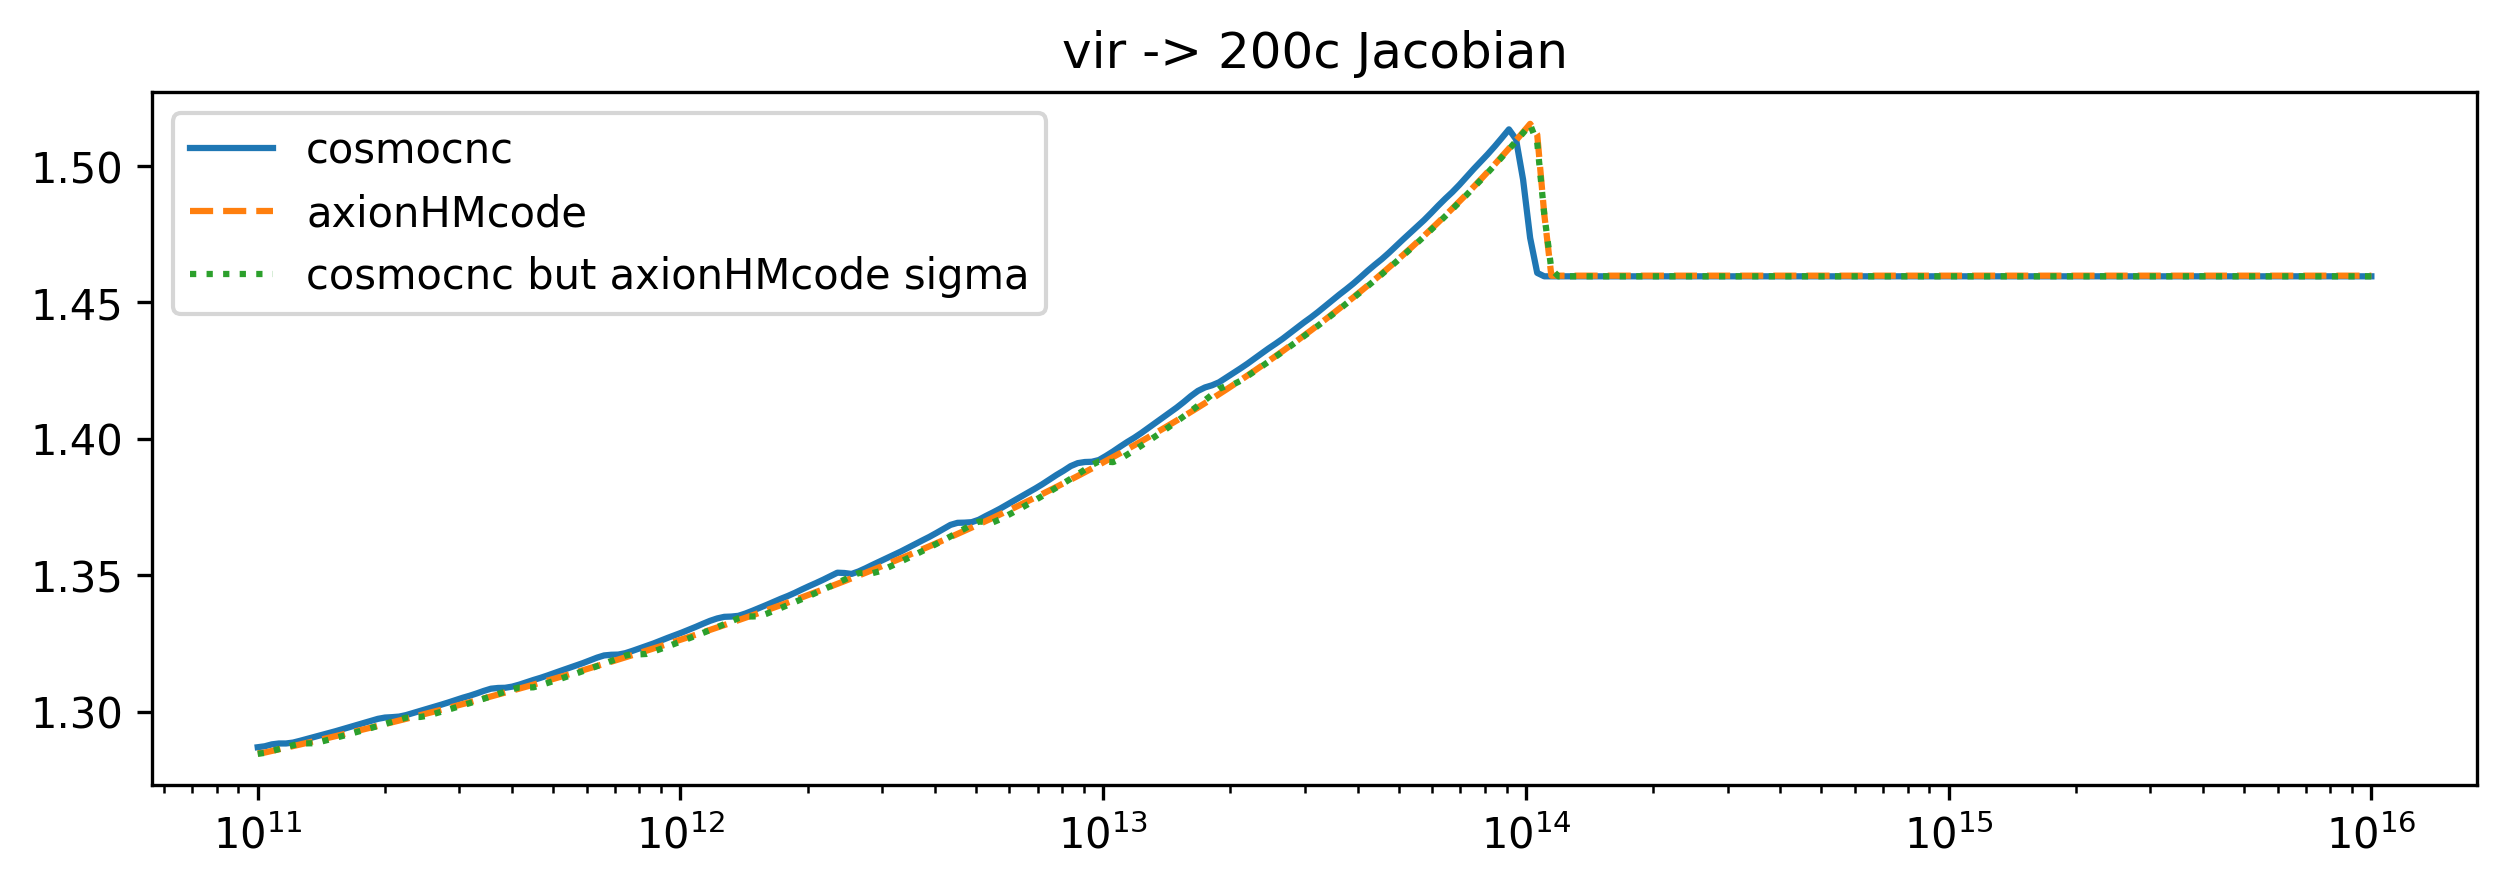

In [54]:
%matplotlib inline
plt.figure(figsize=(10,3), dpi=300)
plt.semilogx(Mvir, np.gradient(Mvir_cosmocnc)/np.gradient(M200_cosmocnc), ls='-', label='cosmocnc')
plt.semilogx(Mvir, np.gradient(Mvir)/np.gradient(M200c_arr), ls='--', label='axionHMcode')
plt.semilogx(Mvir, np.gradient(Mvir_cosmocnc_HMsigma)/np.gradient(M200_cosmocnc), ls=':', label='cosmocnc but axionHMcode sigma')
plt.legend()
plt.title("vir -> 200c Jacobian")
plt.show()

In [56]:
import pickle
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── CONFIG ────────────────────────────────────────────────────────────────────
HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
PLOT_PATH       = "/home/jange/scratch/FeedbackMimic/results/diagnose_mvir.pdf"

H_FID   = 0.68
OMEGA_M = 0.143344
A_S = 2.1e-9

Z_TEST  = [0.25, 0.5, 1.0, 1.5]
M_TRANSITION = 10**12.5

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

# ── IMPORTS ───────────────────────────────────────────────────────────────────
from feedback_mimic import (
    dn_dlog10Mtot, get_realspace_profile, get_NFW_profile,
    Mtot_to_MDelta, get_some_quantities,
)

import jax.numpy as jnp
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    sigma_R,
    func_axionHMcode_Delta_vir,
    func_axionHMcode_delta_c,
    find_M_vir_from_M_200c
)

# ── INIT COSMOCNC ─────────────────────────────────────────────────────────────
print("Initialising cosmocnc...")
get_log_likelihood(
    catalogue_name=catalogue_name,
    omega_m=OMEGA_M, A_s=A_S,
    A_sz=-4.4580166296603672, alpha_sz=1.2468585981093097,
    beta_sz=0.8796081344595097, b_WL_0=0.0, b_WL_M=1.0,
)
h_cnc   = nc.cosmo_params["h"]
Om0_cnc = nc.cosmo_params["Om0"]
rho_c0  = nc.halo_mass_function.rho_c_0   # Msol/Mpc³
rho_m_cnc = rho_c0 * Om0_cnc
E_z_fn  = lambda z: nc.cosmology.background_cosmology.H(z).value / (h_cnc * 100.)

# ── FIGURE SETUP ──────────────────────────────────────────────────────────────
n_cols = len(Z_TEST)
fig = plt.figure(figsize=(5*n_cols, 12), dpi=120)
gs  = gridspec.GridSpec(3, n_cols, figure=fig,
                        height_ratios=[1, 1, 0.5],
                        hspace=0.08, wspace=0.3,
                        left=0.08, right=0.97,
                        bottom=0.07, top=0.93)

C_GEN = "#E08C0A"
C_CNC = "#C44E52"

for col, z in enumerate(Z_TEST):

    print(f"\n{'='*50}")
    print(f"  z = {z}")
    print(f"{'='*50}")

    # ── LOAD GENERATION SLICE ─────────────────────────────────────────────────
    with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data = pickle.load(f)

    Mtot, hmf_log10 = dn_dlog10Mtot(data, 'LCDM')
    r_t, rho_crit_gen, _, _, r_s, Dv_gen, _, _ = get_some_quantities(data)

    valid  = Mtot > M_TRANSITION
    Mtot_v = Mtot[valid];  r_t_v = r_t[valid];  r_s_v = r_s[valid]

    rho_v = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t_v, k_arr=K_ARR, r_s=r_s_v, r_t=r_t_v),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_v, r_t=r_t_v)

    M200c_gen, R200c_gen = Mtot_to_MDelta(
        data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
        Del=200, reference_density="critical",
        axion_dic=None, rho=rho_v, k_arr=K_ARR)

    order    = np.argsort(M200c_gen)
    M200c_gen = M200c_gen[order]
    Mvir_gen  = Mtot_v[order]
    R200c_gen = R200c_gen[order]

    # Generation Jacobian: dMvir/dM200c = (Mvir/M200c) * dlnMvir/dlnM200c
    jac_gen = (Mvir_gen / M200c_gen) * (
        np.gradient(np.log(Mvir_gen)) / np.gradient(np.log(M200c_gen)))

    # Generation concentration from halo model
    # c_vir = r_t / r_s  (virial radius / scale radius)
    conc_gen = r_t_v[order] / r_s_v[order]

    print(f"  Generation: Mvir range = {Mvir_gen.min():.3e} -- {Mvir_gen.max():.3e} Msol/h")
    print(f"  Generation: c_vir range = {conc_gen.min():.2f} -- {conc_gen.max():.2f}")

    # ── COSMOCNC Mvir(M200c) ──────────────────────────────────────────────────
    rho_crit_z = rho_c0 * E_z_fn(z)**2   # Msol/Mpc³
    g_a = (np.interp(z, nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full)
           * nc.cosmology.normalisation_cached * (1 + z))
    G_a = nc.cosmology.G_a_cached

    Delta_vir = func_axionHMcode_Delta_vir(z, Om0_cnc, G_a, E_z_fn, g_a)
    delta_c   = func_axionHMcode_delta_c(  z, Om0_cnc, G_a, E_z_fn, g_a)

    print(f"  Delta_vir: gen={Dv_gen:.3f}, cnc={Delta_vir:.3f}, ratio={Dv_gen/Delta_vir:.4f}")

    # Power spectrum for sigma in z_formation
    k_cnc, ps_cnc = nc.cosmology.power_spectrum.get_linear_power_spectrum(z)
    rho_m_for_sigma = rho_m_cnc / h_cnc**2
    sr = sigma_R((jnp.asarray(k_cnc)*h_cnc**-1, jnp.asarray(ps_cnc)*h_cnc**3),
                 cosmology=nc.cosmology)
    sr.get_derivative(type_deriv="analytical")

    # Use cosmocnc's M200c grid (Msol) to find Mvir
    M200c_cnc_Msol = M200c_gen / H_FID   # convert gen M200c to Msol for cosmocnc
    R200c_cnc_Mpc  = (3.*M200c_cnc_Msol / (4.*np.pi*rho_crit_z*200.))**(1./3.)

    Mvir_cnc_Msol = find_M_vir_from_M_200c(
        M200c_cnc_Msol, R200c_cnc_Mpc,
        rho_m_cnc, rho_crit_z,
        Delta_vir, 5.196, z, Om0_cnc, sr,
        nc.cosmology.normalisation_cached, delta_c, E_z_fn,
        nc.cosmology.D_grid_z_full, nc.cosmology.D_grid_full,
        min_factor=0.1, max_factor=20)

    Mvir_cnc_h = np.asarray(Mvir_cnc_Msol) * H_FID   # Msol/h, same axis as gen

    # cosmocnc Jacobian
    jac_cnc = (Mvir_cnc_h / M200c_gen) * _smooth_log_jacobian(M200c_gen, Mvir_cnc_h)

    # Inferred cosmocnc concentration
    R_vir_cnc = (3.*Mvir_cnc_Msol / (4.*np.pi*rho_m_cnc*Delta_vir))**(1./3.) * H_FID  # Mpc/h
    conc_cnc  = R_vir_cnc / (R200c_gen / H_FID * H_FID)   # approx; just for inspection

    print(f"  Mvir ratio at M200c=3e14: gen/cnc = "
          f"{np.interp(3e14, M200c_gen, Mvir_gen) / np.interp(3e14, M200c_gen, Mvir_cnc_h):.4f}")
    print(f"  Jac ratio at M200c=3e14:  gen/cnc = "
          f"{np.interp(3e14, M200c_gen, jac_gen) / np.interp(3e14, M200c_gen, jac_cnc):.4f}")

    # ── PLOT ──────────────────────────────────────────────────────────────────
    ax_mvir = fig.add_subplot(gs[0, col])
    ax_jac  = fig.add_subplot(gs[1, col])
    ax_rat  = fig.add_subplot(gs[2, col])

    log_M = np.log10(M200c_gen)

    # Panel 1: Mvir(M200c)
    ax_mvir.plot(log_M, np.log10(Mvir_gen),  color=C_GEN, lw=2, label='Generation')
    ax_mvir.plot(log_M, np.log10(Mvir_cnc_h), color=C_CNC, lw=2, ls='--', label='cosmocnc')
    ax_mvir.set_ylabel(r'$\log_{10} M_{\rm vir}\ [M_\odot/h]$', fontsize=10)
    ax_mvir.set_title(f'$z={z:.2f}$', fontsize=12)
    ax_mvir.tick_params(labelbottom=False, which='both', direction='in')
    ax_mvir.grid(alpha=0.2, ls='--')
    if col == 0:
        ax_mvir.legend(fontsize=9)

    # Panel 2: Jacobian dMvir/dM200c
    ax_jac.plot(log_M, jac_gen,  color=C_GEN, lw=2, label='Generation')
    ax_jac.plot(log_M, jac_cnc,  color=C_CNC, lw=2, ls='--', label='cosmocnc')
    ax_jac.set_ylabel(r'$dM_{\rm vir}/dM_{200c}$', fontsize=10)
    ax_jac.tick_params(labelbottom=False, which='both', direction='in')
    ax_jac.grid(alpha=0.2, ls='--')
    ax_jac.set_yscale('log')

    # Panel 3: ratio Mvir and Jacobian gen/cnc
    ratio_Mvir = Mvir_gen / Mvir_cnc_h
    ratio_jac  = jac_gen / np.where(jac_cnc > 0, jac_cnc, np.nan)

    ax_rat.axhline(1.0, color='k', lw=0.8, ls='--', alpha=0.5)
    ax_rat.fill_between(log_M, 0.95, 1.05, color='gray', alpha=0.15)
    ax_rat.plot(log_M, ratio_Mvir, color=C_GEN, lw=1.5, label=r'$M_{\rm vir}$ ratio')
    ax_rat.plot(log_M, ratio_jac,  color=C_CNC, lw=1.5, ls='--', label='Jac ratio')
    ax_rat.set_ylim(0.7, 1.3)
    ax_rat.set_ylabel('Gen / CNC', fontsize=10)
    ax_rat.set_xlabel(r'$\log_{10}[M_{200c}\ (M_\odot/h)]$', fontsize=10)
    ax_rat.tick_params(which='both', direction='in')
    ax_rat.grid(alpha=0.2, ls='--')
    if col == 0:
        ax_rat.legend(fontsize=8)

    # Print table
    print(f"  {'log10(M200c)':>14} | {'Mvir_gen':>12} | {'Mvir_cnc':>12} | "
          f"{'Mvir ratio':>10} | {'Jac_gen':>10} | {'Jac_cnc':>10} | {'Jac ratio':>10}")
    for M_ref in [1e13, 3e13, 1e14, 3e14, 1e15]:
        Mvg = np.exp(np.interp(np.log(M_ref), np.log(M200c_gen), np.log(Mvir_gen)))
        Mvc = np.exp(np.interp(np.log(M_ref), np.log(M200c_gen), np.log(Mvir_cnc_h)))
        Jg  = np.interp(np.log(M_ref), np.log(M200c_gen), jac_gen)
        Jc  = np.interp(np.log(M_ref), np.log(M200c_gen), jac_cnc)
        print(f"  {np.log10(M_ref):>14.2f} | {Mvg:>12.4e} | {Mvc:>12.4e} | "
              f"{Mvg/Mvc:>10.4f} | {Jg:>10.4f} | {Jc:>10.4f} | {Jg/Jc:>10.4f}")

# x limits
for ax in fig.axes:
    ax.set_xlim(13.0, 15.8)

fig.suptitle('Mvir↔M200c conversion',
             fontsize=12, y=0.97)

plt.savefig(PLOT_PATH, dpi=150, bbox_inches='tight')
print(f"\nSaved → {PLOT_PATH}")
plt.close()

Initialising cosmocnc...


/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:782: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")



  z = 0.25
  Generation: Mvir range = 3.199e+12 -- 1.000e+16 Msol/h
  Generation: c_vir range = 5.20 -- 10.45
  Delta_vir: gen=389.729, cnc=390.200, ratio=0.9988
  Mvir ratio at M200c=3e14: gen/cnc = 0.9930
  Jac ratio at M200c=3e14:  gen/cnc = 0.9889
    log10(M200c) |     Mvir_gen |     Mvir_cnc | Mvir ratio |    Jac_gen |    Jac_cnc |  Jac ratio
           13.00 |   1.2119e+13 |   1.2215e+13 |     0.9921 |     1.2252 |     1.2389 |     0.9889
           13.48 |   3.6988e+13 |   3.7306e+13 |     0.9915 |     1.2516 |     1.2665 |     0.9882
           14.00 |   1.2652e+14 |   1.2775e+14 |     0.9904 |     1.2969 |     1.3126 |     0.9881
           14.48 |   3.8655e+14 |   3.8926e+14 |     0.9930 |     1.2832 |     1.2975 |     0.9890
           15.00 |   1.2885e+15 |   1.2975e+15 |     0.9931 |     1.2874 |     1.2975 |     0.9922

  z = 0.5
  Generation: Mvir range = 3.199e+12 -- 1.000e+16 Msol/h
  Generation: c_vir range = 5.20 -- 8.83
  Delta_vir: gen=385.499, cnc=386.710, ratio

Initialising cosmocnc...


/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:782: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


Computing generation HMFs...
0.723404646
  z=0.25: N_gen (per sr, this z) = 4.58e+05
0.635736167
  z=0.50: N_gen (per sr, this z) = 1.30e+06
0.502138555
  z=1.00: N_gen (per sr, this z) = 2.39e+06
0.410407752
  z=1.50: N_gen (per sr, this z) = 2.39e+06
Plotting...
  z=0.25: ratio gen/cnc at M=3e14 Msol/h = 0.9323
  z=0.50: ratio gen/cnc at M=3e14 Msol/h = 0.9621
  z=1.00: ratio gen/cnc at M=3e14 Msol/h = 1.0465
  z=1.50: ratio gen/cnc at M=3e14 Msol/h = 1.2078


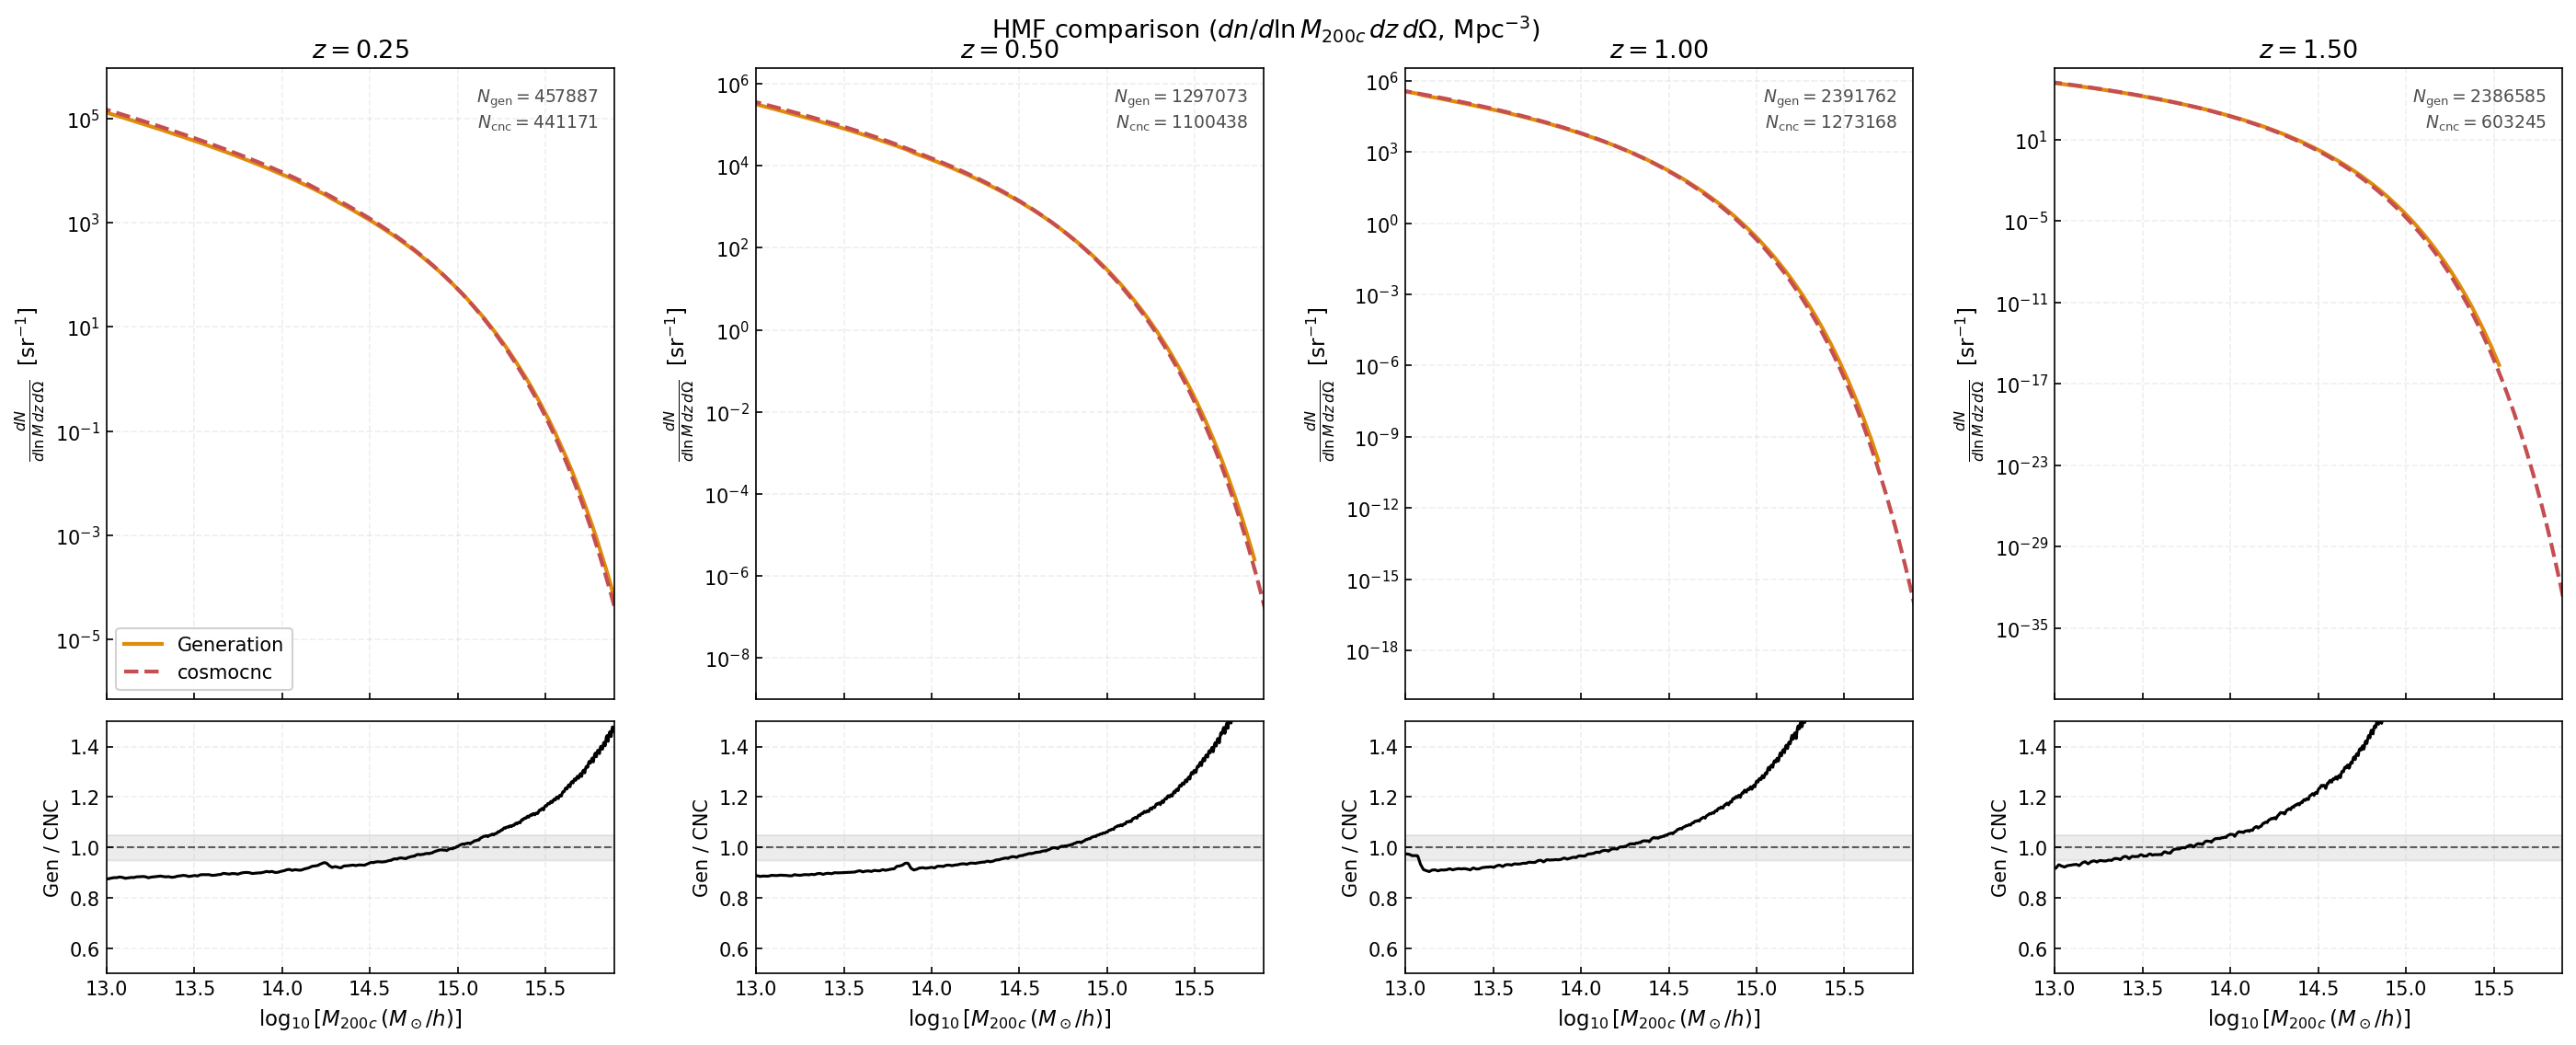

In [57]:
import pickle
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.integrate import simpson as scipy_simpson
%matplotlib inline
# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
PLOT_PATH       = "/home/jange/scratch/FeedbackMimic/results/hmf_comparison.pdf"

H_FID   = 0.68
OMEGA_M = 0.143344
A_SZ     = -4.4580166296603672
ALPHA_SZ = 1.2468585981093097
BETA_SZ  = 0.8796081344595097

M_TRANSITION = 10**12.5

# Redshifts to compare — pick a spread
Z_PLOT = [0.25, 0.5, 1.0, 1.5]

K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

Z_ARR = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

# ──────────────────────────────────────────────────────────────────────────────
# IMPORTS
# ──────────────────────────────────────────────────────────────────────────────
from feedback_mimic import (
    dn_dlog10Mtot, get_realspace_profile, get_NFW_profile,
    dV_dz, Mtot_to_MDelta, get_some_quantities,
)

# ──────────────────────────────────────────────────────────────────────────────
# INITIALISE COSMOCNC
# ──────────────────────────────────────────────────────────────────────────────

print("Initialising cosmocnc...")
lnL, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = OMEGA_M,
    A_s  = A_S,
    A_sz     = A_SZ,
    alpha_sz = ALPHA_SZ,
    beta_sz  = BETA_SZ,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    return_nc = True
)

ln_M_nc   = np.asarray(nc.ln_M)               # ln(M/1e14 Msol), no h
M_nc_Msol = np.exp(ln_M_nc) * 1e14            # Msol
M_nc_Msol_h = M_nc_Msol * H_FID               # Msol/h

redshift_vec_nc = np.asarray(nc.redshift_vec)  # (n_z,)
hmf_matrix_nc   = np.asarray(nc.hmf_matrix)   # (n_z, n_M)
# hmf_matrix = dn/dlnM [Mpc^-3] * dV/dz/dOmega [Mpc³/sr] * 4π * fsky
# → extract dn/dlnM * dV/dz/dOmega = hmf_matrix / (4π * fsky)
fsky_nc = nc.scaling_relations["q_so_sim"].skyfracs[0]

# ──────────────────────────────────────────────────────────────────────────────
# COMPUTE GENERATION HMF AT EACH Z_PLOT
# ──────────────────────────────────────────────────────────────────────────────

print("Computing generation HMFs...")

gen_results = {}   # z -> (M200c_Msol_h, dn_dlnM200c_Mpc3, dV_per_sr)

for z in Z_PLOT:
    iz_arr = np.argmin(np.abs(Z_ARR - z))
    z_actual = float(Z_ARR[iz_arr])

    with open(f"{HALO_INPUT_FILE}/{z_actual}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data = pickle.load(f)
    print(data['cosmos']['sigma_8'])

    Mtot, hmf_log10 = dn_dlog10Mtot(data, 'LCDM')
    hmf = hmf_log10 / np.log(10)   # dn/dlnMvir — carries 4π convention

    r_t, rho_crit, rho_char, conc, r_s, Dv, rho0, rho0wh = \
        get_some_quantities(data)

    valid  = Mtot > M_TRANSITION
    Mtot_v = Mtot[valid];  hmf_v = hmf[valid]
    r_t_v  = r_t[valid];   r_s_v = r_s[valid]

    rho_v = get_realspace_profile(
        u_k=get_NFW_profile(r_v=r_t_v, k_arr=K_ARR, r_s=r_s_v, r_t=r_t_v),
        r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_v, r_t=r_t_v)

    M200c, _ = Mtot_to_MDelta(
        data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
        Del=200, reference_density="critical",
        axion_dic=None, rho=rho_v, k_arr=K_ARR)

    order = np.argsort(M200c)
    M200c  = M200c[order]
    Mtot_v = Mtot_v[order]
    hmf_v  = hmf_v[order]

    jac = np.gradient(np.log(Mtot_v)) / np.gradient(np.log(M200c))
    dn_dlnM200c_gen_4pi = hmf_v * jac   # dn/dlnM200c with 4π convention
    # Remove 4π to get per-steradian [Mpc^-3] matching cosmocnc
    dn_dlnM200c_per_sr = dn_dlnM200c_gen_4pi / (4. * np.pi)

    # dV/dz per steradian [Mpc³/sr] = dV_dz(data) / (4π)
    dV_full   = dV_dz(data)          # full sphere Mpc³
    dV_per_sr = dV_full / (4. * np.pi)  # per sr Mpc³/sr

    gen_results[z] = {
        'z_actual':         z_actual,
        'M200c_Msol_h':     M200c,                  # Msol/h
        'dn_dlnM200c_Mpc3': dn_dlnM200c_per_sr,     # Mpc^-3 per sr
        'dV_per_sr':        dV_per_sr,              # Mpc³/sr
        # Product = dN/(dlnM dz dOmega):
        'dN_dlnM_dz_dOmega': dn_dlnM200c_per_sr * dV_per_sr,
    }

    N_gen = scipy_simpson(dn_dlnM200c_per_sr * dV_per_sr, x=np.log(M200c))
    print(f"  z={z_actual:.2f}: N_gen (per sr, this z) = {N_gen:.2e}")


# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

print("Plotting...")

n_z = len(Z_PLOT)
fig = plt.figure(figsize=(5*n_z, 8), dpi=150)
gs  = gridspec.GridSpec(2, n_z, figure=fig,
                        height_ratios=[1, 0.4], hspace=0.05,
                        left=0.08, right=0.97, bottom=0.10, top=0.92,
                        wspace=0.28)

C_GEN = "#E08C0A"
C_CNC = "#C44E52"

for col, z in enumerate(Z_PLOT):

    ax_top = fig.add_subplot(gs[0, col])
    ax_bot = fig.add_subplot(gs[1, col])

    res = gen_results[z]
    M_gen   = res['M200c_Msol_h']                # Msol/h
    hmf_gen = res['dN_dlnM_dz_dOmega']           # Mpc^-3 * Mpc³/sr = sr^-1

    # Find nearest cosmocnc redshift
    iz_nc = np.argmin(np.abs(redshift_vec_nc - z))
    z_nc  = float(redshift_vec_nc[iz_nc])

    # Extract dn/dlnM * dV/dz/dOmega from hmf_matrix
    hmf_row_nc = hmf_matrix_nc[iz_nc] / (4. * np.pi * fsky_nc)  # sr^-1
    M_nc_plot  = M_nc_Msol_h   # Msol/h

    # ── top panel: HMF ────────────────────────────────────────────────────────
    ax_top.plot(np.log10(M_gen), hmf_gen,
                color=C_GEN, lw=2.0, label='Generation')
    ax_top.plot(np.log10(M_nc_plot), hmf_row_nc,
                color=C_CNC, lw=2.0, ls='--', label='cosmocnc')

    ax_top.set_yscale('log')
    ax_top.set_title(f'$z = {z:.2f}$', fontsize=13)
    ax_top.tick_params(labelbottom=False, which='both', direction='in')
    ax_top.grid(alpha=0.2, linestyle='--')
    ax_top.set_ylabel(r'$\frac{dN}{d\ln M\, dz\, d\Omega}$  [sr$^{-1}$]', fontsize=11)
    if col == 0:
        ax_top.legend(fontsize=10, framealpha=0.9)

    # y limits: cosmocnc range at this z
    valid_nc = hmf_row_nc > 0
    if valid_nc.sum() > 0:
        ax_top.set_ylim(hmf_row_nc[valid_nc].min() * 0.5,
                        hmf_row_nc[valid_nc].max() * 2.)

    # ── bottom panel: ratio gen/cnc ───────────────────────────────────────────
    # Interpolate generation onto cosmocnc mass grid
    hmf_gen_on_nc = np.interp(
        np.log10(M_nc_plot),
        np.log10(M_gen),
        hmf_gen,
        left=np.nan, right=np.nan)

    ratio = hmf_gen_on_nc / np.where(hmf_row_nc > 0, hmf_row_nc, np.nan)

    ax_bot.axhline(1.0, color='k', lw=1.0, ls='--', alpha=0.6)
    ax_bot.fill_between(np.log10(M_nc_plot), 0.95, 1.05,
                        color='gray', alpha=0.15, label='±5%')
    ax_bot.plot(np.log10(M_nc_plot), ratio, color='k', lw=1.5)

    ax_bot.set_ylim(0.5, 1.5)
    ax_bot.set_ylabel('Gen / CNC', fontsize=10)
    ax_bot.set_xlabel(r'$\log_{10}[M_{200c}\,(M_\odot/h)]$', fontsize=11)
    ax_bot.tick_params(which='both', direction='in')
    ax_bot.grid(alpha=0.2, linestyle='--')

    # Print ratio at a reference mass
    M_ref = 3e14  # Msol/h
    ratio_at_ref = np.interp(np.log10(M_ref), np.log10(M_nc_plot), ratio)
    print(f"  z={z:.2f}: ratio gen/cnc at M=3e14 Msol/h = {ratio_at_ref:.4f}")

    # Integrated counts
    N_gen_z  = scipy_simpson(hmf_gen, x=np.log(M_gen))
    N_cnc_z  = scipy_simpson(hmf_row_nc[valid_nc], x=np.log(M_nc_Msol_h[valid_nc]))
    ax_top.text(0.97, 0.97,
                f'$N_{{\\rm gen}}={N_gen_z:.0f}$\n$N_{{\\rm cnc}}={N_cnc_z:.0f}$',
                transform=ax_top.transAxes, ha='right', va='top', fontsize=9,
                color='0.3')

# x limits — shared mass range
M_lo = max(np.log10(min(gen_results[z]['M200c_Msol_h'].min() for z in Z_PLOT)), 13.0)
M_hi = min(np.log10(max(gen_results[z]['M200c_Msol_h'].max() for z in Z_PLOT)), 16.0)
for col in range(n_z):
    fig.axes[col].set_xlim(M_lo, M_hi)
    fig.axes[n_z + col].set_xlim(M_lo, M_hi)

fig.suptitle(
    r'HMF comparison ($dn/d\ln M_{200c}\,dz\,d\Omega$, Mpc$^{-3}$)',
    fontsize=13, y=0.97)

fig.show()

###### Fiducial Params

In [ ]:
'''
import numpy as np
from scipy.optimize import minimize

def objective(params):
    A_sz, alpha_sz, beta_sz = params

    logL = get_log_likelihood(
        catalogue_name=catalogue_name,
        omega_m=0.143344,
        A_s = 2.1e-9,
        A_sz=A_sz,
        alpha_sz=alpha_sz,
        beta_sz=beta_sz,
        b_WL_0=0.0,
        b_WL_M=1.0,
    )

    print(
        f"A_sz = {A_sz:.6f}, "
        f"alpha_sz = {alpha_sz:.6f}, "
        f"beta_sz = {beta_sz:.6f}, "
        f"logL = {logL:.6f}",
        flush=True,
    )

    return -logL

result = minimize(
    objective,
    x0=[-4.3054, 1.233, 2.0],
    method="Nelder-Mead",
    options={
        "disp": True,
        "maxiter": 1000,
        "xatol": 1e-6,
        "fatol": 1e-6,
    },
)

print("\nOptimization complete:")
print(result)
A_final, alpha_final, beta_final = result.x
'''
A_final, alpha_final, beta_final = -4.27685554,  0.88131371,  0.73093547

A_sz = -4.276864, alpha_sz = 0.881317, beta_sz = 0.731216, logL = -1212892.337196
A_sz = -4.490707, alpha_sz = 0.881317, beta_sz = 0.731216, logL = -1231350.968401
A_sz = -4.276864, alpha_sz = 0.925383, beta_sz = 0.731216, logL = -1213152.159623
A_sz = -4.276864, alpha_sz = 0.881317, beta_sz = 0.767777, logL = -1212926.622972
A_sz = -4.063021, alpha_sz = 0.910694, beta_sz = 0.755590, logL = -1232061.302892


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

b_WL_0_grid = np.linspace(0.0 - 0.5, 0.0 + 0.5, 10)
b_WL_M_grid = np.linspace(1.0 - 0.5, 1.0 + 0.5, 10)
lnL = np.zeros((len(b_WL_M_grid), len(b_WL_0_grid)))

for i, b_WL_M in tqdm(enumerate(b_WL_M_grid)):
    for j, b_WL_0 in enumerate(b_WL_0_grid):
        lnL[i, j] = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            A_s = 2.1e-9,
            A_sz=A_final,
            alpha_sz=alpha_final,
            beta_sz=beta_final,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M
        )
delta_lnL = lnL - np.max(lnL)

In [ ]:
'''
import numpy as np
from scipy.optimize import minimize

def objective(params):
    b_WL_0, b_WL_M = params

    logL = get_log_likelihood(
        catalogue_name=catalogue_name,
        omega_m=0.143344,
        A_s = 2.1e-9,
        A_sz=A_final,
        alpha_sz=alpha_final,
        beta_sz=beta_final,
        b_WL_0=b_WL_0,
        b_WL_M=b_WL_M,
    )

    print(
        f"b_WL_0 = {b_WL_0:.6f}, "
        f"b_WL_M = {b_WL_M:.6f}, "
        f"logL = {logL:.6f}",
        flush=True,
    )

    return -logL

result = minimize(
    objective,
    x0=[0.0, 1.0],
    method="Nelder-Mead",
    options={
        "disp": True,
        "maxiter": 1000,
        "xatol": 1e-6,
        "fatol": 1e-6,
    },
)

print("\nOptimization complete:")
print(result)
b_WL_0_final, b_WL_M_final = result.x
'''
b_WL_0_final, b_WL_M_final = 

In [ ]:
# Plot
plt.figure(figsize=(6, 5))
im = plt.imshow(
    delta_lnL,
    origin="lower",
    extent=[
        b_WL_0_grid.min(),
        b_WL_0_grid.max(),
        b_WL_M_grid.min(),
        b_WL_M_grid.max(),
    ],
    aspect="auto",
)

plt.colorbar(im, label=r"$\Delta \ln \mathcal{L}$")
plt.xlabel(r"$b_{\rm WL,0}$")
plt.ylabel(r"$b_{\rm WL,M}$")

# Mark the maximum likelihood
plt.scatter(
    b_WL_0_final,
    b_WL_M_final,
    color="red",
    marker="x",
    s=100,
    label="Optimal Point",
)

plt.legend()
plt.tight_layout()
plt.show()

print(f"Maximum likelihood at b_WL_0 = {b_WL_0_final:.16f}, "
      f"b_WL_M = {b_WL_M_final:.16f}")

###### 1D Likelihood Slices (with the rest fixed)

In [ ]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)


fiducial = {
    "omega_m": 0.143344,
    "A_s" : 2.1e-9,
    "A_sz": A_final,
    "alpha_sz": alpha_final,
    "beta_sz": beta_final,
    "b_WL_0": b_WL_0_final,
    "b_WL_M": b_WL_M_final,
}

num_points = 100
parameter_ranges = {
    "omega_m": np.linspace(0.12, 0.17, num_points),
    "A_s": np.linspace(1.8e-9, 2.4e-9, num_points),
    "A_sz": np.linspace(-6, -3, num_points),
    "alpha_sz": np.linspace(0.0, 2.5, num_points),
    "beta_sz": np.linspace(0.0, 2.5, num_points),
    "b_WL_0": np.linspace(-0.5, 0.5, num_points),
    "b_WL_M": np.linspace(0.5, 1.5, num_points),
}

In [ ]:
results = {}

for param, values in parameter_ranges.items():
    logL = []
    print(param)

    for val in tqdm(values):
        pars = fiducial.copy()
        pars[param] = val

        lnL = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=pars["omega_m"],
            A_s =pars["A_s"],
            A_sz=pars["A_sz"],
            alpha_sz=pars["alpha_sz"],
            beta_sz=pars["beta_sz"],
            b_WL_0=pars["b_WL_0"],
            b_WL_M=pars["b_WL_M"],
        )

        logL.append(lnL)

    logL = np.array(logL)

    results[param] = {
        "x": values,
        "logL": logL,
    }

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    len(results),
    1,
    figsize=(6, 3 * len(results)),
    constrained_layout=True,
)

if len(results) == 1:
    axes = [axes]

for ax, (param, data) in zip(axes, results.items()):

    x = data["x"]
    logL = data["logL"]

    # Relative likelihood normalized to peak = 1
    likelihood = np.exp(logL - np.max(logL))

    ax.plot(x, likelihood, lw=2)
    ax.axvline(fiducial[param], linestyle="--", alpha=0.5)

    ax.set_xlabel(param)
    ax.set_ylabel("Log L")
    ax.set_title(f"1D likelihood slice: {param}")

plt.show()